# Full-data comparisons — aigen / nogen / plain / drawings

One notebook over the **combined full-data tables**, which already hold every condition in a
single file (so nothing here walks the per-condition trees):

- `Data/processed_data/Full_experiment/combined/full_data/trials_final_semantic_tag_image_validation_full_data.csv`
  — semantic tags **validated against the ground-truth image** (solid = supported by the image,
  hollow cap = *hallucinated*, i.e. `n_not_in_image_*`).
- `Data/processed_data/Full_experiment/combined/full_data/trials_final_sim_full_data.csv`
  — gen-vs-GT image similarity (CLIP / VGG).
- `Data/processed_data/wilmas_drawings_2019/combined/full_data/drawing_semantic_tag_image_validation_full_data_with_hint.csv`
  — Wilma's 2019 drawings, described by GPT **with the category hint**, tagged and validated the
  same way.

Colors follow `cross_gen_semantic_counts.ipynb` (Dark2): **green** aigen, **orange** nogen,
**purple** plain, plus **pink** for drawings. `gpt-5.5_desc` (GPT describing the image it can
see, same tagger + same judge) is the dashed reference line in every count figure.

### Which figure answers which question
| # | Question | Feedback types | Attempts | View |
|---|----------|----------------|----------|------|
| 1  | aigen alone, per category | aigen | 1–3 | bars over attempts, panel per task |
| 2a | aigen vs nogen, per category | aigen, nogen | 1–3 | bars over attempts, panel per task |
| 2b | aigen vs nogen, gen-vs-GT similarity | aigen, nogen | 1–3 | CLIP / VGG lines over attempts |
| 3a | aigen vs plain, per category | aigen, plain | 1 only | bars by task |
| 3b | nogen vs plain, per category | nogen, plain | 1 only | bars by task |
| 3c | aigen vs nogen vs plain, first image | all three | 1 only | CLIP / VGG bars by task |
| 4  | all three, every category at once | all three | 1–3 | panel grid, one figure per task |
| 5  | aigen vs drawings | aigen, drawings | 1–3 vs the single drawing | bars on one axis, panel per task |

**Note on `plain`:** it has a single attempt by design, so it only appears in the attempt-1
comparisons (3a/3b/3c) and as a one-attempt bar in view 4.

**`adjectives` is not judged** — "cozy", "old", "photo-realistic" are matters of taste, not of
what the image shows. It is drawn hatched, without a hallucination cap, and labelled
*(unvalidated)*. Never read it as a validated count.

In [56]:
import sys
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find project root (the dir containing config.py) regardless of where the notebook sits.
project_root = Path.cwd()
while not (project_root / "config.py").exists() and project_root != project_root.parent:
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import config
print("project root:", project_root)

project root: /mnt/hdd/anatkorol/Imagination_in_translation


## Load — the combined full-data tables

`COUNT_MODE = "validated"` splits every bar into image-supported tags (solid) and hallucinated
ones (hollow cap). Flip it to `"raw"` for the plain tag counts out of the same file.

`delay` (`perc` / `imm` / `del`) is the task column in these tables; it is mapped to the
`perception` / `immediate` / `delay` names used across the other notebooks. The drawings table
carries its own `task` column with different labels, so it is rebuilt from `delay` too, keeping
one vocabulary everywhere.

In [57]:
# --- THE TOGGLE ------------------------------------------------------------------
# "validated" -> solid bar = tags found in the image, hollow cap = tags that are not
# "raw"       -> plain tag counts, no caps
COUNT_MODE = "validated"

FULL = config.ROOT / "Data" / "processed_data" / "Full_experiment" / "combined" / "full_data"
SEM_PATH  = FULL / "trials_final_semantic_tag_image_validation_full_data.csv"
SIM_PATH  = FULL / "trials_final_sim_full_data.csv"
DRAW_PATH = (config.ROOT / "Data" / "processed_data" / "wilmas_drawings_2019" / "combined"
             / "full_data" / "drawing_semantic_tag_image_validation_full_data_with_hint.csv")

# Semantic-tag categories: csv column -> nice axis label.
CATEGORIES = {
    "objects": "Objects",
    "stuff": "Stuff",
    "scene_category": "Scene category",
    "spatial_relations": "Spatial relations",
    "attr_color": "Color attributes",
    "adjectives": "Adjectives",
}

# Judged by object_accuracy_detector.py. Anything outside this set gets no cap and is drawn
# hatched, because a `false` there would be a matter of taste, not of the image.
VALIDATED_CATEGORIES = ("objects", "stuff", "scene_category", "spatial_relations", "attr_color")

# `delay` is the task column in the full-data tables.
DELAY_TO_TASK = {"perc": "perception", "imm": "immediate", "del": "delay"}

assert COUNT_MODE in ("validated", "raw"), COUNT_MODE


def _count(cell):
    """Length of a stringified list cell; 0 for empty / NaN / unparseable."""
    if pd.isna(cell):
        return 0
    try:
        val = ast.literal_eval(cell)
    except (ValueError, SyntaxError):
        return 0
    return len(val) if isinstance(val, (list, tuple)) else 0


def is_validated(category):
    """True when this category carries a hallucination cap in the current mode."""
    return COUNT_MODE == "validated" and category in VALIDATED_CATEGORIES


def cat_label(category):
    """Axis label, marking the unjudged category so it is never read as validated."""
    base = CATEGORIES[category]
    return base if is_validated(category) or COUNT_MODE == "raw" else f"{base} (unvalidated)"


def _prep_counts(d, name):
    """Drop unjudged rows, add the task column, and derive n_<cat> / h_<cat> per category."""
    # Rows the judge could not score (API failure, missing image, ...) have NaN counts.
    # Dropping is safer than letting them average in as zeros - re-run the validator to fill them.
    if "error" in d.columns and d["error"].notna().any():
        n_bad = int(d["error"].notna().sum())
        print(f"  !! {name}: dropping {n_bad}/{len(d)} row(s) with a validation error")
        d = d[d["error"].isna()].copy()
    d = d.copy()
    d["task"] = d["delay"].map(DELAY_TO_TASK)      # overrides the drawings table's own labels
    assert d["task"].notna().all(), f"{name}: unmapped delay values {set(d['delay'])}"
    d["attempt"] = d["attempt"].astype(int)
    for col in CATEGORIES:
        raw = d[col].apply(_count)
        if is_validated(col):
            # v2: the bar is valid tags, the cap participant hallucinations, so the
            # two extraction-side error types are excluded rather than counted as
            # the participant's. v1 files lack n_valid_* and keep the old behaviour.
            if f"n_valid_{col}" in d.columns:
                d[f"n_{col}"] = pd.to_numeric(d[f"n_valid_{col}"], errors="coerce")
                d[f"h_{col}"] = pd.to_numeric(d[f"n_participant_hallucination_{col}"], errors="coerce")
            else:
                d[f"n_{col}"] = pd.to_numeric(d[f"n_in_image_{col}"], errors="coerce")
                d[f"h_{col}"] = pd.to_numeric(d[f"n_not_in_image_{col}"], errors="coerce")
            # The judge must have seen exactly the tags the tagger produced.
            extracted = pd.to_numeric(d[f"n_extracted_{col}"], errors="coerce")
            n_off = int((extracted != raw).sum())
            if n_off:
                print(f"  !! {name}/{col}: {n_off} row(s) where n_extracted != len(tag list)")
        else:
            d[f"n_{col}"] = raw
            d[f"h_{col}"] = 0
    return d


trials = _prep_counts(pd.read_csv(SEM_PATH), "trials")
print(f"loaded trials: {len(trials)} rows, {trials['uid'].nunique()} participants")

draw = _prep_counts(pd.read_csv(DRAW_PATH), "drawings")
draw["generation"] = "drawing"       # already 'drawing' in the file; pinned so the key is ours
print(f"loaded drawings (with hint): {len(draw)} rows, {draw['uid'].nunique()} participants")

# One table for every count figure. Which generations a figure uses is chosen per figure,
# so the drawings rows simply sit unused in the views that do not ask for them.
keep = [c for c in trials.columns if c in draw.columns]
df = pd.concat([trials, draw[keep]], ignore_index=True)

GRAPHS = config.COMBINED_ANALYSIS_DIR / "graphs" / "full_data_comparisons"
GRAPHS.mkdir(parents=True, exist_ok=True)

# One judge config across the whole table, or the counts are not comparable across conditions.
for col in ("judge_model", "image_detail", "judged_categories", "tagger_model"):
    if col in df.columns:
        vals = sorted(set(df[col].dropna().astype(str)))
        print(f"{col}: {vals}")
        if len(vals) > 1:
            print(f"  !! mixed {col} - revalidate before trusting these counts")

print(f"\nMODE = {COUNT_MODE!r} | figures -> {GRAPHS}")
df.groupby(["generation", "task"])["attempt"].agg(rows="size", attempts="nunique",
                                                  participants="size").join(
    df.groupby(["generation", "task"])["uid"].nunique().rename("uids")).drop(columns="participants")

loaded trials: 2392 rows, 225 participants
loaded drawings (with hint): 171 rows, 74 participants
judge_model: ['gpt-5.4-mini']
image_detail: ['original']
judged_categories: ['objects,stuff,scene_category,spatial_relations,attr_color']
tagger_model: ['gpt-5.5']

MODE = 'validated' | figures -> /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons


rows  attempts  uids
generation task                            
aigen      delay        318         3    25
           immediate    357         3    25
           perception   351         3    25
drawing    delay         35         1    21
           immediate     75         1    30
           perception    61         1    23
nogen      delay        315         3    25
           immediate    345         3    25
           perception   351         3    25
plain      delay        120         1    25
           immediate    114         1    25
           perception   121         1    25

In [58]:
# --- Similarity table: distances -> similarities (we ALWAYS plot similarity) ---
sim = pd.read_csv(SIM_PATH)
sim["task"] = sim["delay"].map(DELAY_TO_TASK)
sim["attempt"] = sim["attempt"].astype(int)
sim["clip_similarity"] = 1 - sim["clip_cosine_distance"]
sim["vgg_similarity"] = 1 - sim["vgg_fc7_distance"]

# Keep the latest record per (generation, task, uid, gt, attempt) in case of repeated slider moves.
sim = (sim.sort_values("ts")
          .groupby(["generation", "task", "uid", "gt", "attempt"], as_index=False, sort=False)
          .tail(1))

# Similarity metrics: column -> axis label. Both are gen-image vs ground-truth-image.
SIM_METRICS = {
    "clip_similarity": "CLIP similarity (gen vs GT)",
    "vgg_similarity":  "VGG fc7 similarity (gen vs GT)",
}
print(f"similarity rows: {len(sim)}")
sim.groupby(["generation", "task"])[list(SIM_METRICS)].count()

similarity rows: 2392


clip_similarity  vgg_similarity
generation task                                       
aigen      delay                   318             318
           immediate               357             357
           perception              351             351
nogen      delay                   315             315
           immediate               345             345
           perception              351             351
plain      delay                   120             120
           immediate               114             114
           perception              121             121

In [59]:
# --- Style + fixed color maps (per generation, reused in every figure) ---
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid", font_scale=1.6)
plt.rcParams.update({
    "axes.titlesize": 22,
    "axes.labelsize": 20,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 16,
    "legend.title_fontsize": 17,
    "figure.titlesize": 26,
})

TASK_ORDER  = ["perception", "immediate", "delay"]
TASK_LABELS = {"perception": "Perception", "immediate": "Immediate memory", "delay": "Delayed memory"}
ATTEMPTS    = [1, 2, 3]

# Dark2: green / orange / purple for the three feedback types, pink for the drawings -
# same fixed mapping as cross_gen_semantic_counts.ipynb, reused in every figure below.
GEN_COLORS = {"aigen": "#1b9e77", "nogen": "#d95f02", "plain": "#7570b3", "drawing": "#e7298a"}
GEN_LABELS = {"aigen": "AI-gen (image)", "nogen": "No-gen (text)", "plain": "Plain (baseline)",
              "drawing": "Drawings (with hint)"}

# The cap is the SAME hue as its bar, hollow instead of solid - it is a part of that
# generation's total, not an extra series, so it must not introduce a new color.
CAP_FACE = "white"
CAP_LW = 1.6
CAP_LABEL = "Participant hallucination"
UNVALIDATED_HATCH = "//"
CI_COLOR = "#333333"

# The number printed over every bar: the mean VALIDATED count, i.e. the solid part only -
# never the hallucination cap and never the two summed.
BAR_LABEL_SIZE = 11
BAR_LABEL_COLOR = "#222222"
BAR_LABEL_FMT = "{:.1f}"

Y_TICK_STEP = None
Y_TARGET_TICKS = 8


def _nice_step(vmax, target=Y_TARGET_TICKS):
    """Round vmax/target up to the nearest 1, 2, 5 x 10^k."""
    if not vmax or vmax <= 0:
        return 1
    raw = vmax / target
    mag = 10 ** np.floor(np.log10(raw))
    for m in (1, 2, 5, 10):
        if raw <= m * mag:
            return m * mag
    return 10 * mag


def _style_count_axis(ax, vmax=None):
    """y starts at 0; ticks every Y_TICK_STEP, or a nice auto step from the panel range.

    When vmax is given the top is set explicitly. On a sharey figure that matters:
    set_ylim disables autoscale for the whole shared axis, so a taller panel drawn later
    would otherwise be clipped. Callers pass the max across every panel.
    """
    if vmax is not None and vmax > 0:
        ax.set_ylim(0, vmax * 1.05)
    else:
        ax.set_ylim(bottom=0)
    top = vmax if vmax is not None else ax.get_ylim()[1]
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP or _nice_step(top)))


def _geom(series, dodge=True):
    """(offsets, width) of each bar slot, matching seaborn's categorical geometry: a total
    slot width of 0.8, split evenly between the hue levels when they are dodged, or used
    whole when the hue *is* the x variable (one bar per x, no dodge)."""
    if not dodge:
        return {s: 0.0 for s in series}, 0.8
    n = len(series)
    width = 0.8 / n
    return {s: (i - (n - 1) / 2) * width for i, s in enumerate(series)}, width


def add_caps(ax, x_index, series, bottoms, caps, geom, color_of=None, hatch=False):
    """Stack the hollow 'not in image' segment on top of each bar.

    x_index : {x category -> integer position on the axis}
    bottoms : {(x, series) -> solid bar height}   caps: {(x, series) -> cap height}
    geom    : (offsets, width) from _geom, so caps land exactly on their bars.
    color_of: (x, series) -> edge color; defaults to the series' generation color.
    """
    offsets, width = geom
    color_of = color_of or (lambda xv, s: GEN_COLORS[s])
    for xv, i in x_index.items():
        for s in series:
            h = caps.get((xv, s), 0)
            if not h or np.isnan(h):
                continue
            ax.bar(i + offsets[s], h, bottom=bottoms.get((xv, s), 0),
                   width=width * 0.92, facecolor=CAP_FACE, edgecolor=color_of(xv, s),
                   linewidth=CAP_LW, hatch=UNVALIDATED_HATCH if hatch else None, zorder=2.5)


def _boot_ci(values, n_boot=2000, ci=95, seed=0):
    """Percentile bootstrap CI of the mean, matching seaborn's errorbar=('ci', 95)."""
    v = np.asarray([x for x in values if not np.isnan(x)], dtype=float)
    if len(v) < 2:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    means = rng.choice(v, size=(n_boot, len(v)), replace=True).mean(axis=1)
    half = (100 - ci) / 2
    return np.percentile(means, half), np.percentile(means, 100 - half)


def add_ci(ax, x_index, series, data, x_col, hue_col, value_col, geom):
    """95% bootstrap CI on the VALIDATED mean of each bar; returns {(x, series) -> (lo, hi)}
    so the value labels can be placed clear of the whisker.

    Drawn on top of everything (zorder 5) so the hollow cap never hides the upper whisker,
    and in neutral ink so it reads as an annotation on the solid bar rather than as data.
    """
    offsets, _ = geom
    out = {}
    for xv, i in x_index.items():
        for s in series:
            vals = data[(data[x_col] == xv) & (data[hue_col] == s)][value_col]
            if len(vals) < 2:
                continue
            lo, hi = _boot_ci(vals)
            if np.isnan(lo):
                continue
            m = vals.mean()
            out[(xv, s)] = (lo, hi)
            ax.errorbar(i + offsets[s], m, yerr=[[m - lo], [hi - m]], fmt="none",
                        ecolor=CI_COLOR, elinewidth=2.0, capsize=4, capthick=2.0, zorder=5)
    return out


def add_bar_labels(ax, x_index, series, means, cis, geom, headroom):
    """Print the mean VALIDATED count over each bar, in small type.

    The number is the solid bar only - the hallucination cap is deliberately excluded, so the
    printed value is always "how much of this did the image support". It is placed above
    whatever is tallest at that bar (the stacked cap or the CI whisker) so nothing overlaps.
    """
    offsets, _ = geom
    for xv, i in x_index.items():
        for s in series:
            if (xv, s) not in means.index:
                continue
            m, cap = means.loc[(xv, s), "count"], means.loc[(xv, s), "cap"]
            if np.isnan(m):
                continue
            top = max(m + (0 if np.isnan(cap) else cap), cis.get((xv, s), (0, 0))[1])
            ax.text(i + offsets[s], top + 0.035 * headroom, BAR_LABEL_FMT.format(m),
                    ha="center", va="bottom", fontsize=BAR_LABEL_SIZE, color=BAR_LABEL_COLOR,
                    zorder=6)


def _figure_legend(fig, gens, marker="bar", labels=None, ncol=None, y=0.90,
                   caps=False, ci=False, gpt=True):
    """One legend for the whole figure, centered above the panels.

    gens   : the generations actually drawn, in draw order.
    labels : optional {gen -> label} override, for views where a generation is pinned to one
             attempt and the legend has to say so (the attempt-1 comparisons).
    marker : "bar" for a color patch, "o" for the line views. caps appends the hollow
             'not in image' patch; ci appends the error-bar entry and may be a string,
             because the interval describes a different quantity in different views.
    """
    labels = labels or {}
    text = lambda g: labels.get(g, GEN_LABELS[g])
    if marker == "bar":
        handles = [Patch(facecolor=GEN_COLORS[g], label=text(g)) for g in gens]
    else:
        handles = [Line2D([], [], color=GEN_COLORS[g], lw=3, marker="o", markersize=9,
                          label=text(g)) for g in gens]
    if caps and COUNT_MODE == "validated":
        handles.append(Patch(facecolor=CAP_FACE, edgecolor="#444444", linewidth=CAP_LW,
                             label=CAP_LABEL))
    if ci:
        handles.append(Line2D([], [], color=CI_COLOR, lw=2.0, marker="_", markersize=10,
                              label=ci if isinstance(ci, str) else "95% CI (validated mean)"))
    if gpt and GPT_DESC:
        handles.append(Line2D([], [], color=GPT_DESC_COLOR, lw=2.4, ls="--", label=GPT_DESC_LABEL))
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, y),
               ncol=ncol or len(handles), frameon=False, columnspacing=2.2,
               handlelength=2.4, handletextpad=0.9)


def _save(fig, out):
    """Save with padding, so the y label / legend are never clipped at the edge."""
    fig.savefig(out, dpi=300, bbox_inches="tight", pad_inches=0.35)
    print("saved:", out)

## `gpt-5.5_desc` baseline — validated on the same scale
One GPT description per ground-truth image, written *while looking at* the image, tagged by the
same tagger and scored by the same judge. In `"validated"` mode the dashed line is therefore a
*validated* count, directly comparable to the solid bars — and its own invalid rate is the
judge's false-positive floor, the number participant hallucination rates should be read against.

In [60]:
GPT_DESC_VERBOSITY = "medium"
# The runs wrote these under both the newer "gpt-5.5_desc" and the older "gpt_ceiling" name;
# accept either, exactly as object_accuracy_detector.py does.
GPT_DESC_CANDIDATES = [
    config.COMBINED_PROCESSED_DIR / "gpt-5.5_desc"
    / f"gpt-5.5_desc_semantic_tag_image_validation_verbosity-{GPT_DESC_VERBOSITY}.csv",
    config.COMBINED_PROCESSED_DIR / "gpt_ceiling"
    / f"gpt_ceiling_semantic_tag_image_validation_verbosity-{GPT_DESC_VERBOSITY}.csv",
]
GPT_DESC_COLOR = "#444444"
GPT_DESC_LABEL = "gpt-5.5_desc"

_path = next((p for p in GPT_DESC_CANDIDATES if p.exists()), None)
if _path is not None:
    gpt_desc_df = pd.read_csv(_path)
    if "error" in gpt_desc_df.columns:
        gpt_desc_df = gpt_desc_df[gpt_desc_df["error"].isna()].copy()
    for col in CATEGORIES:
        if is_validated(col):
            if f"n_valid_{col}" in gpt_desc_df.columns:   # validator v2
                gpt_desc_df[f"n_{col}"] = pd.to_numeric(gpt_desc_df[f"n_valid_{col}"], errors="coerce")
                gpt_desc_df[f"h_{col}"] = pd.to_numeric(
                    gpt_desc_df[f"n_participant_hallucination_{col}"], errors="coerce")
            else:
                gpt_desc_df[f"n_{col}"] = pd.to_numeric(gpt_desc_df[f"n_in_image_{col}"], errors="coerce")
                gpt_desc_df[f"h_{col}"] = pd.to_numeric(
                    gpt_desc_df[f"n_not_in_image_{col}"], errors="coerce")
        else:
            gpt_desc_df[f"n_{col}"] = gpt_desc_df[col].apply(_count)
            gpt_desc_df[f"h_{col}"] = 0
    # Mean over the GT images: one gpt-5.5_desc value per category.
    GPT_DESC = {c: gpt_desc_df[f"n_{c}"].mean() for c in CATEGORIES}
    GPT_DESC_CAP = {c: gpt_desc_df[f"h_{c}"].mean() for c in CATEGORIES}
    print(f"loaded gpt-5.5_desc from {_path.parent.name}/: {len(gpt_desc_df)} descriptions, "
          f"{gpt_desc_df['gt'].nunique()} GT images")
    if COUNT_MODE == "validated":
        n_val = sum(gpt_desc_df[f"n_{c}"].sum() for c in VALIDATED_CATEGORIES)
        n_inv = sum(gpt_desc_df[f"h_{c}"].sum() for c in VALIDATED_CATEGORIES)
        print(f"JUDGE FALSE-POSITIVE FLOOR: {n_inv:.0f}/{n_val + n_inv:.0f} = "
              f"{100 * n_inv / (n_val + n_inv):.2f}% of tags marked 'not in image' in descriptions "
              f"written WITH the image in view.\nRead participant rates against this, not against 0.")
    display(gpt_desc_df[["gt"] + [f"n_{c}" for c in CATEGORIES]])
else:
    gpt_desc_df, GPT_DESC, GPT_DESC_CAP = None, {}, {}
    print("no validated gpt-5.5_desc file - run: python analysis/nlp_analysis/"
          "object_accuracy_detector.py -c gpt-5.5_desc")

loaded gpt-5.5_desc from gpt_ceiling/: 5 descriptions, 5 GT images
JUDGE FALSE-POSITIVE FLOOR: 0/260 = 0.00% of tags marked 'not in image' in descriptions written WITH the image in view.
Read participant rates against this, not against 0.


,gt,n_objects,n_stuff,n_scene_category,n_spatial_relations,n_attr_color,n_adjectives
0,bedroom_l.jpg,27,3,1,15,15,33
1,conference_room_h.jpg,18,0,1,14,17,36
2,lighthouse_h.jpg,24,7,0,15,9,40
3,living_room_h.jpg,17,2,2,8,17,47
4,playground_h.jpg,16,3,3,12,14,31


## Plot helpers — one set, driven by a *selection*

Every question below is the same picture over a different slice, so the selection is the only
thing that changes. A selection is a dict `{generation: attempts}`:

```python
{"aigen": None}                     # aigen, all attempts          -> Q1
{"aigen": None, "nogen": None}      # both, all attempts           -> Q2a
{"aigen": 1, "plain": 1}            # both, attempt 1 only         -> Q3a
{"aigen": None, "drawing": 1}       # the loop against the drawings -> Q5
```

Three views take one:
- `plot_category_over_attempts` — panel per task, x = attempt (needs > 1 attempt).
- `plot_category_by_task` — a single panel, x = task, for a fixed attempt.
- `plot_all_categories_grid` — every category at once for one task, x = attempt.

All draw the same marks: solid bar = mean validated count per participant, **the number printed
over the bar = that same validated mean** (the hallucination cap is never included in it), black
error bar = 95% bootstrap CI on the mean, hollow cap = mean count of tags the image does not
support, dots = individual participants, dashed line = `gpt-5.5_desc`.

In [61]:
# --- Selection -------------------------------------------------------------
def sel(spec, data=None):
    """Rows for a selection: {generation: attempts}, attempts None = all, int or list = those.

    Returns (frame, gens) with gens in the spec's own order, dropping any generation that has
    no rows in that slice - so a legend never shows an empty swatch.
    """
    d = df if data is None else data
    parts, gens = [], []
    for g, att in spec.items():
        x = d[d["generation"] == g]
        if att is not None:
            x = x[x["attempt"].isin(np.atleast_1d(att))]
        if x.empty:
            print(f"  (no rows for {g}, attempts={att} - dropped)")
            continue
        parts.append(x)
        gens.append(g)
    return (pd.concat(parts, ignore_index=True) if parts else d.iloc[0:0]), gens


def _attempt_labels(spec):
    """{gen -> legend label} that names the pinned attempt, for selections where the sides sit
    on different attempts. Empty when every generation uses the same ones."""
    fixed = {g: np.atleast_1d(a).tolist() for g, a in spec.items() if a is not None}
    if len(set(map(tuple, fixed.values()))) < 2:
        return {}
    return {g: f"{GEN_LABELS[g]} - attempt {', '.join(map(str, a))}" for g, a in fixed.items()}


def _ppt_means(data, keys, category):
    """Mean validated count ("count") and hallucination cap ("cap") per key combination -
    the per-participant points, collapsing that participant's sessions / GT images."""
    cols = {f"n_{category}": "count", f"h_{category}": "cap"}
    return (data.groupby(keys, as_index=False)[list(cols)].mean().rename(columns=cols))


def _add_gpt_desc(ax, category):
    """Dashed reference line at the gpt-5.5_desc value (no-op if not loaded).
    Unlabeled: the figure-level legend carries the entry."""
    if category in GPT_DESC:
        ax.axhline(GPT_DESC[category], color=GPT_DESC_COLOR, ls="--", lw=2.4, zorder=1)


def _draw_bars(ax, data, x_col, x_order, series, category, hue_col="generation",
               palette=None, color_of=None, dots=True, values=True):
    """The shared bar stack: bars + hatch + caps + participant dots + CI + value labels.

    hue_col == x_col means one bar per x (no dodge) - the layout section 5 uses, where the
    x axis mixes aigen's attempts with the drawings. Returns the tallest thing drawn (plus
    room for the labels), so the caller can set a y limit that fits it.
    """
    palette = palette or GEN_COLORS
    dodge = hue_col != x_col
    geom = _geom(series, dodge=dodge)
    x_index = {v: i for i, v in enumerate(x_order)}

    sns.barplot(data=data, x=x_col, y="count", hue=hue_col,
                order=x_order, hue_order=series, palette=palette,
                errorbar=None, legend=False, ax=ax, zorder=2)
    if not is_validated(category) and COUNT_MODE == "validated":
        for patch in ax.patches:
            patch.set_hatch(UNVALIDATED_HATCH)

    # One row per bar. With hue == x the group key is a single label, so it is widened to the
    # same (x, series) form the cap/CI/label helpers index by.
    means = data.groupby([x_col] if not dodge else [x_col, hue_col])[["count", "cap"]].mean()
    if not dodge:
        means.index = pd.MultiIndex.from_arrays([means.index, means.index])
    add_caps(ax, x_index, series, bottoms=means["count"].to_dict(),
             caps=means["cap"].to_dict(), geom=geom, color_of=color_of)
    if dots:
        sns.stripplot(data=data, x=x_col, y="count", hue=hue_col,
                      order=x_order, hue_order=series, palette=palette,
                      dodge=dodge, jitter=0.16, size=4.5, alpha=0.5, linewidth=0.4,
                      edgecolor="white", legend=False, ax=ax, zorder=3)
    cis = add_ci(ax, x_index, series, data, x_col, hue_col, "count", geom)

    vmax = max(data["count"].max(), means.sum(axis=1).max(), GPT_DESC.get(category, 0))
    if values:
        add_bar_labels(ax, x_index, series, means, cis, geom, headroom=vmax)
        vmax *= 1.09     # room for the printed number above the tallest bar
    return vmax


# --- VIEW A: one panel per task, x = attempt --------------------------------
def plot_category_over_attempts(category, spec, attempts=ATTEMPTS, title=None, fname=None,
                                save=True):
    """Bars over attempts, one panel per task, one bar per generation."""
    data, gens = sel(spec)
    if data.empty:
        print(f"{category}: nothing selected - skipping")
        return
    g = _ppt_means(data, ["generation", "task", "uid", "attempt"], category)
    label = cat_label(category)

    fig, axes = plt.subplots(1, len(TASK_ORDER), figsize=(6.5 * len(TASK_ORDER), 6.5), sharey=True)
    axes = np.atleast_1d(axes)
    vmax = 0
    for i, (ax, task) in enumerate(zip(axes, TASK_ORDER)):
        sub = g[g["task"] == task]
        if not sub.empty:
            vmax = max(vmax, _draw_bars(ax, sub, "attempt", attempts,
                                        [x for x in gens if x in set(sub["generation"])], category))
        _add_gpt_desc(ax, category)
        ax.set_title(TASK_LABELS[task])
        ax.set_xlabel("Attempt")
        ax.set_ylabel("Mean count (per participant)" if i == 0 else "")
    for ax in axes:
        _style_count_axis(ax, vmax=vmax)
    kind = "validated " if is_validated(category) else ""
    fig.suptitle(title or f"{label}: {kind}count over attempts")
    _figure_legend(fig, gens, marker="bar", caps=is_validated(category), ci=True)
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    if save and fname:
        _save(fig, GRAPHS / fname)
    plt.show()


# --- VIEW B: one panel, x = task (for a fixed attempt) ----------------------
def plot_category_by_task(category, spec, title=None, fname=None, save=True):
    """One panel, x = task, one bar per generation - the view for a single attempt."""
    data, gens = sel(spec)
    if data.empty:
        print(f"{category}: nothing selected - skipping")
        return
    g = _ppt_means(data, ["generation", "task", "uid"], category)
    label = cat_label(category)

    fig, ax = plt.subplots(figsize=(11, 6.5))
    vmax = _draw_bars(ax, g, "task", TASK_ORDER, gens, category)
    _add_gpt_desc(ax, category)
    ax.set_xlabel("")
    ax.set_ylabel("Mean count (per participant)")
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t] for t in TASK_ORDER])
    _style_count_axis(ax, vmax=vmax)
    kind = "validated " if is_validated(category) else ""
    fig.suptitle(title or f"{label}: {kind}count by task")
    _figure_legend(fig, gens, marker="bar", labels=_attempt_labels(spec), y=0.94,
                   caps=is_validated(category), ci=True)
    fig.tight_layout(rect=(0, 0, 1, 0.89))
    if save and fname:
        _save(fig, GRAPHS / fname)
    plt.show()


# --- VIEW C: every category at once, for one task ---------------------------
PANEL_COLS = 3  # panels per row in the grid


def plot_all_categories_grid(task, spec, attempts=ATTEMPTS, title=None, fname=None, save=True):
    """A grid of per-category panels for a single task: x = attempt, one bar per generation.

    Each panel keeps its OWN y axis - the categories are an order of magnitude apart
    (adjectives ~14 vs scene_category ~1), so a shared scale would flatten the small ones.
    Read each panel against its own dashed gpt-5.5_desc line, not against its neighbours.
    """
    data, gens = sel(spec)
    data = data[data["task"] == task]
    if data.empty:
        print(f"{task}: nothing selected - skipping")
        return
    gens = [x for x in gens if x in set(data["generation"])]
    cats = list(CATEGORIES)
    nrow = int(np.ceil(len(cats) / PANEL_COLS))
    fig, axes = plt.subplots(nrow, PANEL_COLS, figsize=(6.5 * PANEL_COLS, 6.0 * nrow))
    axes = np.atleast_1d(axes).ravel()

    for ax, category in zip(axes, cats):
        g = _ppt_means(data, ["generation", "uid", "attempt"], category)
        vmax = _draw_bars(ax, g, "attempt", attempts, gens, category)
        _add_gpt_desc(ax, category)
        ax.set_title(cat_label(category))
        ax.set_xlabel("Attempt")
        ax.set_ylabel("Mean count (per participant)")
        _style_count_axis(ax, vmax=vmax)
    for ax in axes[len(cats):]:
        ax.set_visible(False)

    kind = "validated tags" if COUNT_MODE == "validated" else "raw tags"
    fig.suptitle(title or f"{TASK_LABELS[task]}: all semantic categories over attempts ({kind})")
    _figure_legend(fig, gens, marker="bar", y=0.955, caps=True, ci=True)
    fig.tight_layout(rect=(0, 0, 1, 0.91))
    if save and fname:
        _save(fig, GRAPHS / fname)
    plt.show()

In [62]:
# --- Similarity views (no caps, no gpt-5.5_desc: these are image-vs-image metrics) ---
def _sim_ppt_means(spec, metric, keys):
    """Per-participant mean of an image-similarity metric over a selection."""
    data, gens = sel(spec, data=sim)
    data = data.dropna(subset=[metric])
    if data.empty:
        return data, gens
    return data.groupby(keys, as_index=False)[metric].mean(), [g for g in gens
                                                               if g in set(data["generation"])]


def plot_sim_over_attempts(metric, spec, attempts=ATTEMPTS, title=None, fname=None, save=True):
    """One panel per task; within a panel one line per generation (mean +/- 95% bootstrap CI)
    over attempts - the layout of cross_gen_similarity_comparison.ipynb."""
    ylabel = SIM_METRICS[metric]
    g, gens = _sim_ppt_means(spec, metric, ["generation", "task", "uid", "attempt"])
    if g.empty:
        print(f"{metric}: nothing selected - skipping")
        return
    fig, axes = plt.subplots(1, len(TASK_ORDER), figsize=(6.8 * len(TASK_ORDER), 6.5), sharey=True)
    axes = np.atleast_1d(axes)
    for i, (ax, task) in enumerate(zip(axes, TASK_ORDER)):
        for gen in gens:
            sub = g[(g["task"] == task) & (g["generation"] == gen)]
            if sub.empty:
                continue
            sns.lineplot(data=sub, x="attempt", y=metric, ax=ax, color=GEN_COLORS[gen],
                         lw=3.5, marker="o", markersize=11, markeredgewidth=0,
                         errorbar=("ci", 95), err_kws={"alpha": 0.20}, legend=False)
        ax.set_title(TASK_LABELS[task])
        ax.set_xticks(attempts); ax.set_xticklabels([str(a) for a in attempts])
        ax.set_xlabel("Attempt")
        ax.set_ylabel(ylabel if i == 0 else "")
    fig.suptitle(title or f"{ylabel} over attempts")
    _figure_legend(fig, gens, marker="o", ci="95% CI", gpt=False)
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    if save and fname:
        _save(fig, GRAPHS / fname)
    plt.show()


def plot_sim_by_task(metric, spec, title=None, fname=None, save=True):
    """One panel, x = task, one bar per generation (mean +/- 95% bootstrap CI over
    participants, participant dots) - the view for a single attempt."""
    ylabel = SIM_METRICS[metric]
    g, gens = _sim_ppt_means(spec, metric, ["generation", "task", "uid"])
    if g.empty:
        print(f"{metric}: nothing selected - skipping")
        return
    fig, ax = plt.subplots(figsize=(11, 6.5))
    sns.barplot(data=g, x="task", y=metric, hue="generation", order=TASK_ORDER,
                hue_order=gens, palette=GEN_COLORS, errorbar=None, legend=False, ax=ax, zorder=2)
    sns.stripplot(data=g, x="task", y=metric, hue="generation", order=TASK_ORDER,
                  hue_order=gens, palette=GEN_COLORS, dodge=True, jitter=0.16, size=4.5,
                  alpha=0.5, linewidth=0.4, edgecolor="white", legend=False, ax=ax, zorder=3)
    add_ci(ax, {t: i for i, t in enumerate(TASK_ORDER)}, gens, g, "task", "generation", metric,
           _geom(gens))
    ax.set_xlabel(""); ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(TASK_ORDER)))
    ax.set_xticklabels([TASK_LABELS[t] for t in TASK_ORDER])
    fig.suptitle(title or ylabel)
    _figure_legend(fig, gens, marker="bar", labels=_attempt_labels(spec), y=0.94,
                   ci="95% CI", gpt=False)
    fig.tight_layout(rect=(0, 0, 1, 0.89))
    if save and fname:
        _save(fig, GRAPHS / fname)
    plt.show()


# Short x-tick names for the per-task panels: the figure legend carries the full label, so the
# axis only needs to say which condition a column is.
GEN_SHORT = {"aigen": "AI-gen", "nogen": "No-gen", "plain": "Plain", "drawing": "Drawing"}
DOT_QUANTILES = (0.02, 0.98)   # inner range of participant dots the zoom is required to fit


def plot_sim_by_task_points(metric, spec, title=None, fname=None, save=True, dots=True,
                            panels=True, pad=0.25, q=DOT_QUANTILES, ylim=None):
    """The 3c view as means + 95% CI over participant dots, on a y axis zoomed to the data.

    Not bars: a bar encodes its value by length *from zero*, so truncating the axis under
    bars misstates the ratios between them - and untruncated, a couple of hundredths of a
    similarity point is invisible. A point encodes only position, so the axis is free to
    start at the data.

    panels : one panel per task, x = condition (the conditions sit in separate blocks
             rather than dodged inside a shared task slot). False = the single-panel
             version, x = task with the conditions dodged.
    dots   : per-participant means behind each point.
    q      : the inner quantile range of the dots the zoom must fit. The full spread across
             participants is far wider than the gap between the means, so fitting every last
             dot would undo the zoom; the tails are cut instead and their count printed in
             the corner of the panel.
    pad    : padding around that range, as a fraction of it.
    ylim   : explicit (lo, hi), overriding the automatic zoom.
    """
    ylabel = SIM_METRICS[metric]
    g, gens = _sim_ppt_means(spec, metric, ["generation", "task", "uid"])
    if g.empty:
        print(f"{metric}: nothing selected - skipping")
        return

    # Where each point goes. With panels the x axis IS the condition (one column each);
    # without, the conditions are dodged inside their task slot, as the bar view had them.
    if panels:
        fig, axes = plt.subplots(1, len(TASK_ORDER), figsize=(5.4 * len(TASK_ORDER), 6.5),
                                 sharey=True)
        axes = np.atleast_1d(axes)
        offsets = {gen: 0.0 for gen in gens}
        x_of = lambda gen: gens.index(gen)
    else:
        fig, ax = plt.subplots(figsize=(11, 6.5))
        axes = np.array([ax])
        offsets, _ = _geom(gens)
        x_of = lambda gen: 0.0

    stats, lo_all, hi_all = {}, [], []
    for i, (ax, task) in enumerate(zip(axes if panels else [axes[0]] * len(TASK_ORDER),
                                       TASK_ORDER)):
        base = 0 if panels else i     # the task's slot on the single shared axis
        for gen in gens:
            vals = g[(g["task"] == task) & (g["generation"] == gen)][metric].to_numpy()
            vals = vals[~np.isnan(vals)]
            if len(vals) < 2:
                continue
            x = base + x_of(gen) + offsets[gen]
            if dots:
                jitter = np.random.default_rng(0).uniform(-0.11, 0.11, len(vals))
                ax.scatter(x + jitter, vals, s=26, color=GEN_COLORS[gen], alpha=0.35,
                           linewidth=0.4, edgecolor="white", zorder=2)
            lo, hi = _boot_ci(vals)
            m = vals.mean()
            ax.errorbar([x], [m], yerr=[[m - lo], [hi - m]], fmt="o", color=GEN_COLORS[gen],
                        markersize=13, markeredgewidth=1.6, markeredgecolor="white",
                        ecolor=CI_COLOR, elinewidth=2.6, capsize=6, capthick=2.6, zorder=5)
            stats[(task, gen)] = (vals, lo, hi)
            lo_all.append(lo); hi_all.append(hi)

    # One y window for every panel: the CIs, plus the inner q of the dots when they are drawn.
    if ylim is None and lo_all:
        lo, hi = min(lo_all), max(hi_all)
        if dots:
            allv = np.concatenate([v for v, _, _ in stats.values()])
            lo = min(lo, np.quantile(allv, q[0]))
            hi = max(hi, np.quantile(allv, q[1]))
        span = (hi - lo) or abs(hi) * 0.05 or 0.01
        ylim = (lo - pad * span, hi + pad * span)
    if ylim is not None:
        axes[0].set_ylim(*ylim)   # sharey propagates it

    for i, ax in enumerate(axes):
        if panels:
            ax.set_title(TASK_LABELS[TASK_ORDER[i]])
            ax.set_xlim(-0.6, len(gens) - 0.4)
            ax.set_xticks(range(len(gens)))
            ax.set_xticklabels([GEN_SHORT.get(x, x) for x in gens])
        else:
            ax.set_xlim(-0.5, len(TASK_ORDER) - 0.5)
            ax.set_xticks(range(len(TASK_ORDER)))
            ax.set_xticklabels([TASK_LABELS[t] for t in TASK_ORDER])
        ax.set_xlabel("")
        ax.set_ylabel(ylabel if i == 0 else "")
        # Say how many participant dots the zoom cut, so a trimmed tail is never silent.
        if dots and ylim is not None:
            tasks = [TASK_ORDER[i]] if panels else TASK_ORDER
            n_out = sum(int(((v < ylim[0]) | (v > ylim[1])).sum())
                        for (t, _), (v, _, _) in stats.items() if t in tasks)
            if n_out:
                ax.text(0.99, 0.01, f"{n_out} off-scale", transform=ax.transAxes,
                        ha="right", va="bottom", fontsize=12, color="#777777")

    fig.suptitle(title or ylabel)
    _figure_legend(fig, gens, marker="o", labels=_attempt_labels(spec),
                   y=0.945 if panels else 0.94, ci="95% CI", gpt=False)
    fig.tight_layout(rect=(0, 0, 1, 0.89))
    if save and fname:
        _save(fig, GRAPHS / fname)
    plt.show()


---
# 1. aigen only — every semantic category over attempts
All three tasks, all three attempts, one figure per category. This is the AI-gen feedback loop on
its own: does a participant's description gain (or lose) content of each kind as they iterate,
and how much of that content the image actually supports.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q1_aigen_validated_objects_over_attempts.png


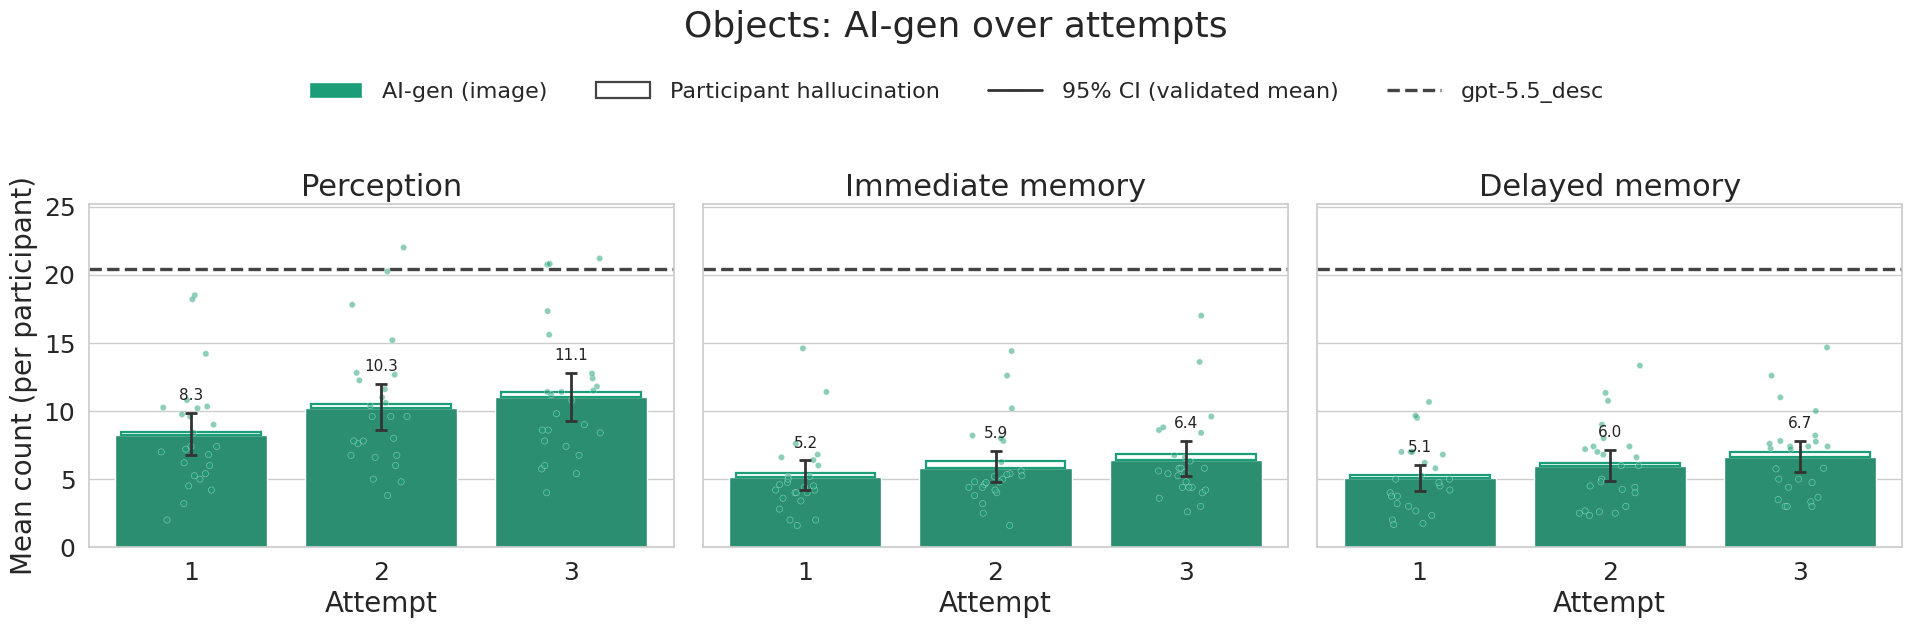

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q1_aigen_validated_stuff_over_attempts.png


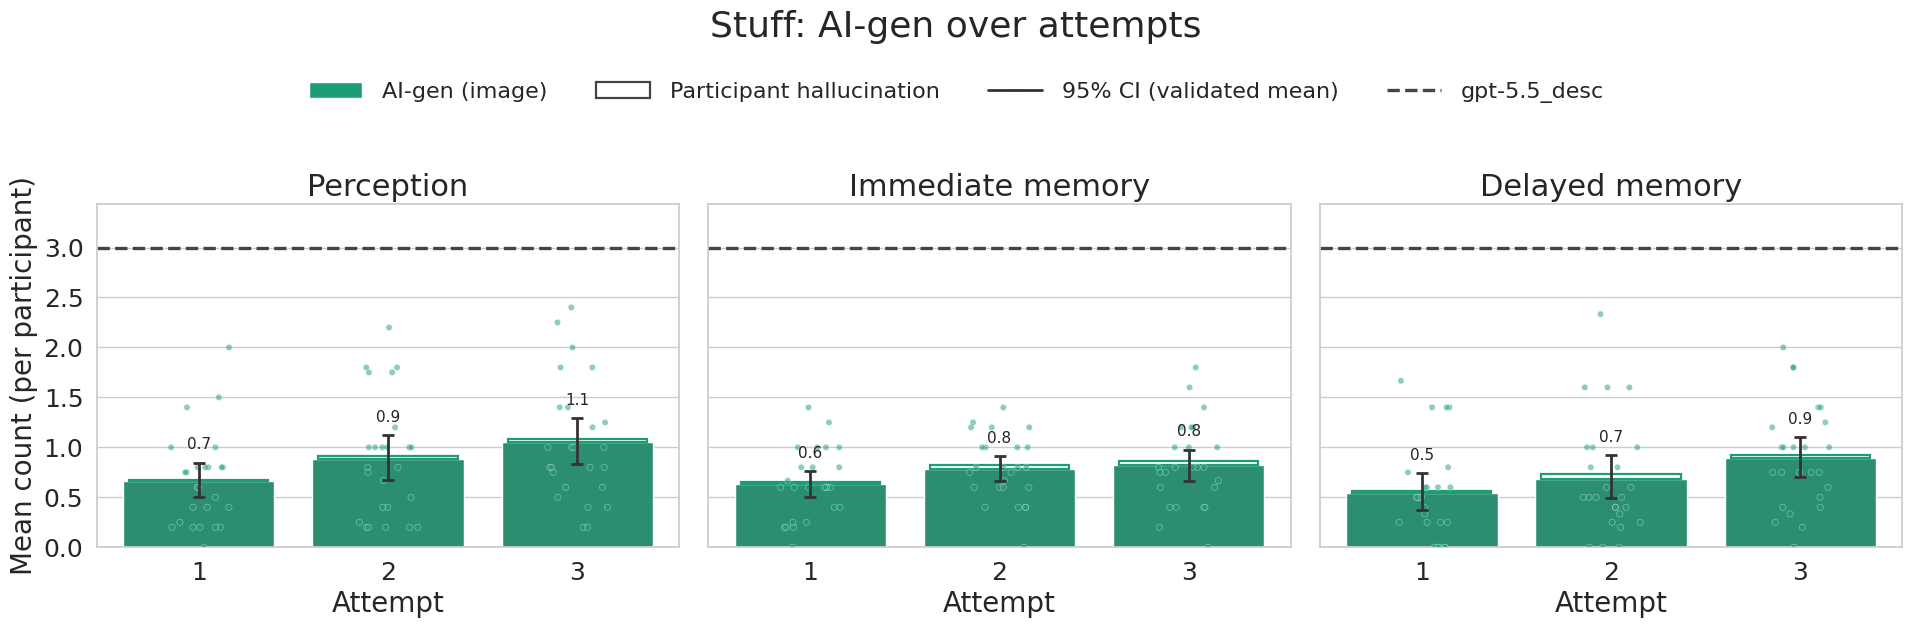

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q1_aigen_validated_scene_category_over_attempts.png


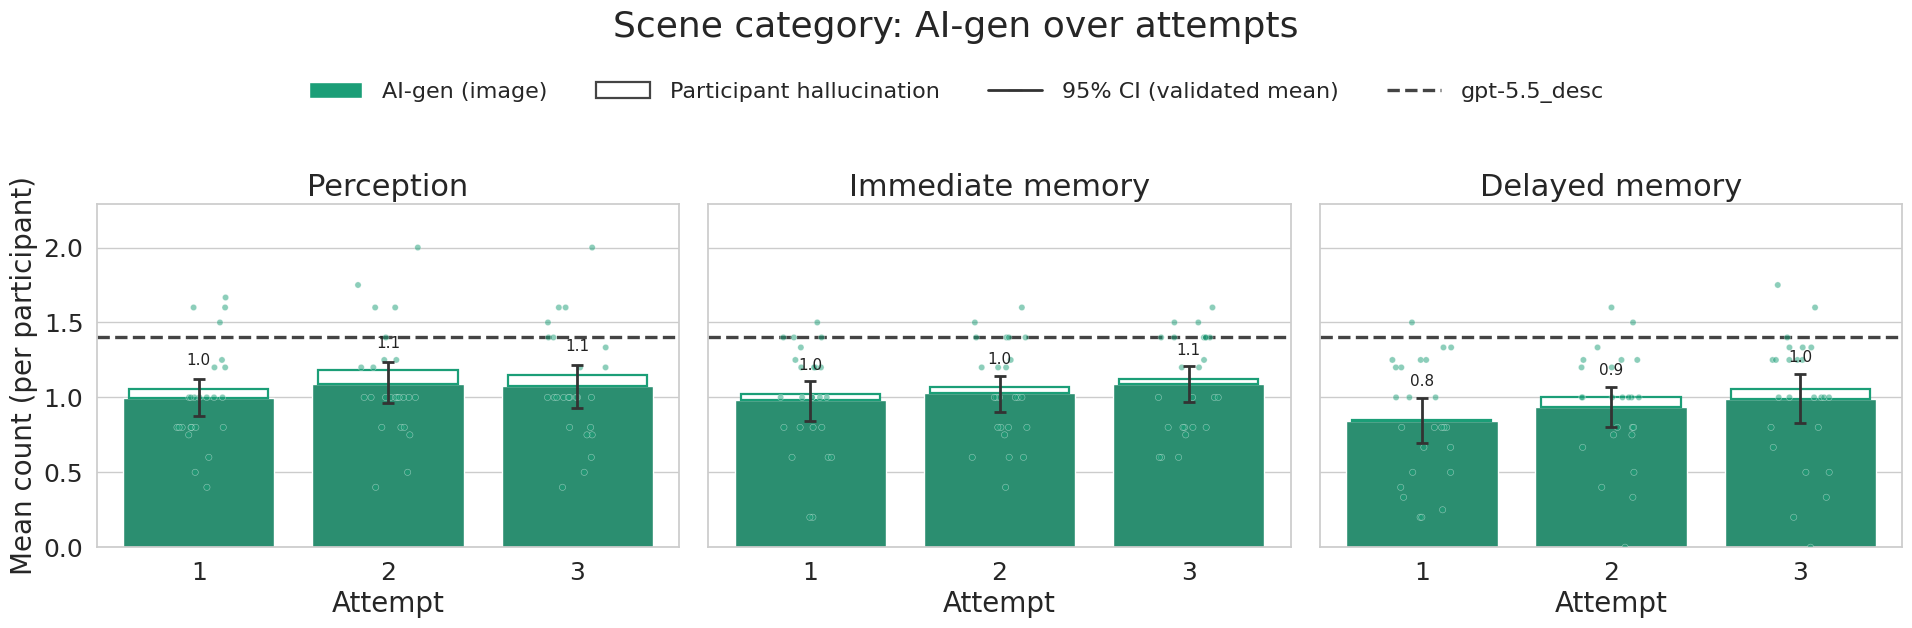

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q1_aigen_validated_spatial_relations_over_attempts.png


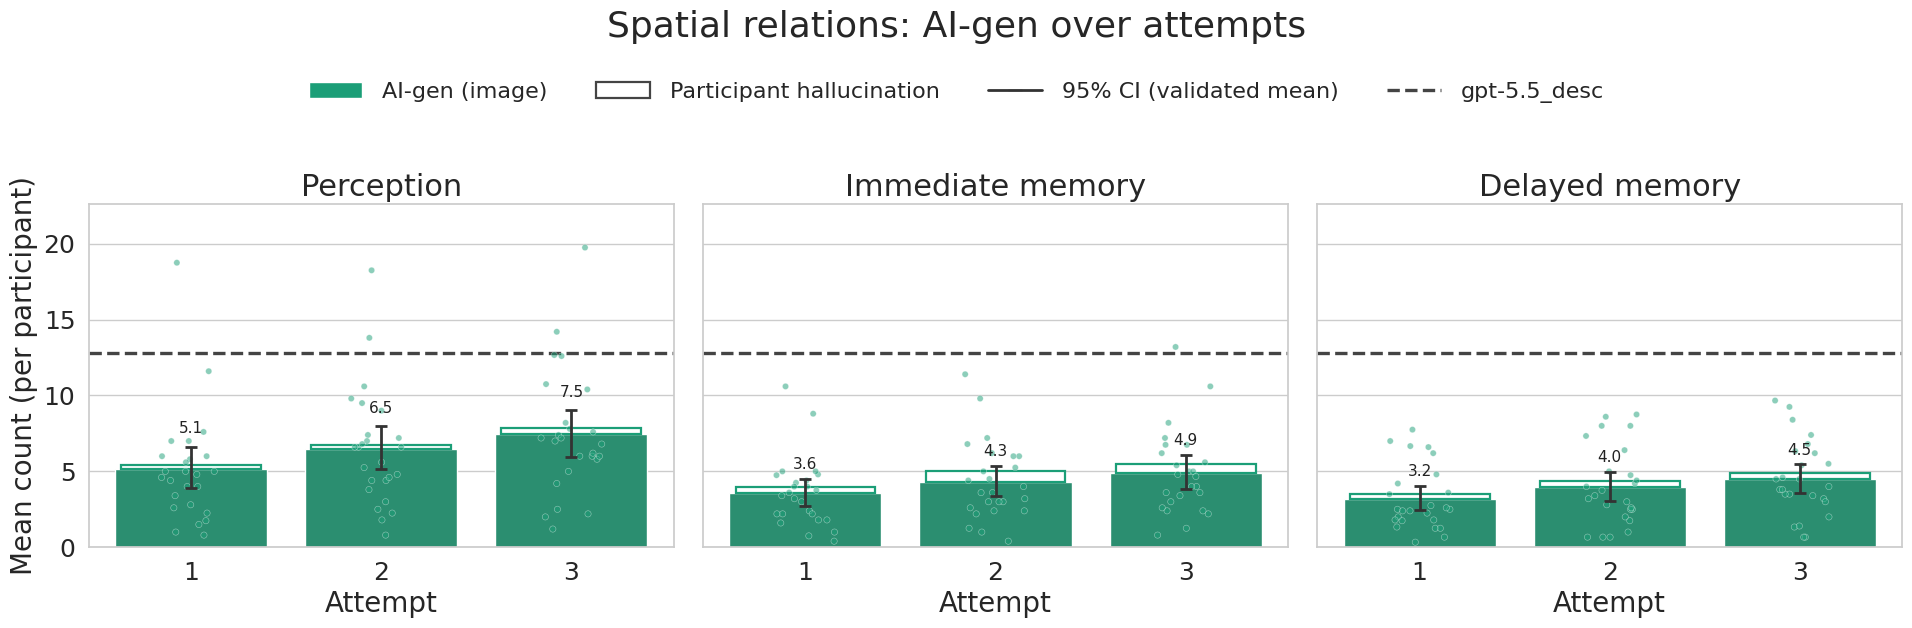

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q1_aigen_validated_attr_color_over_attempts.png


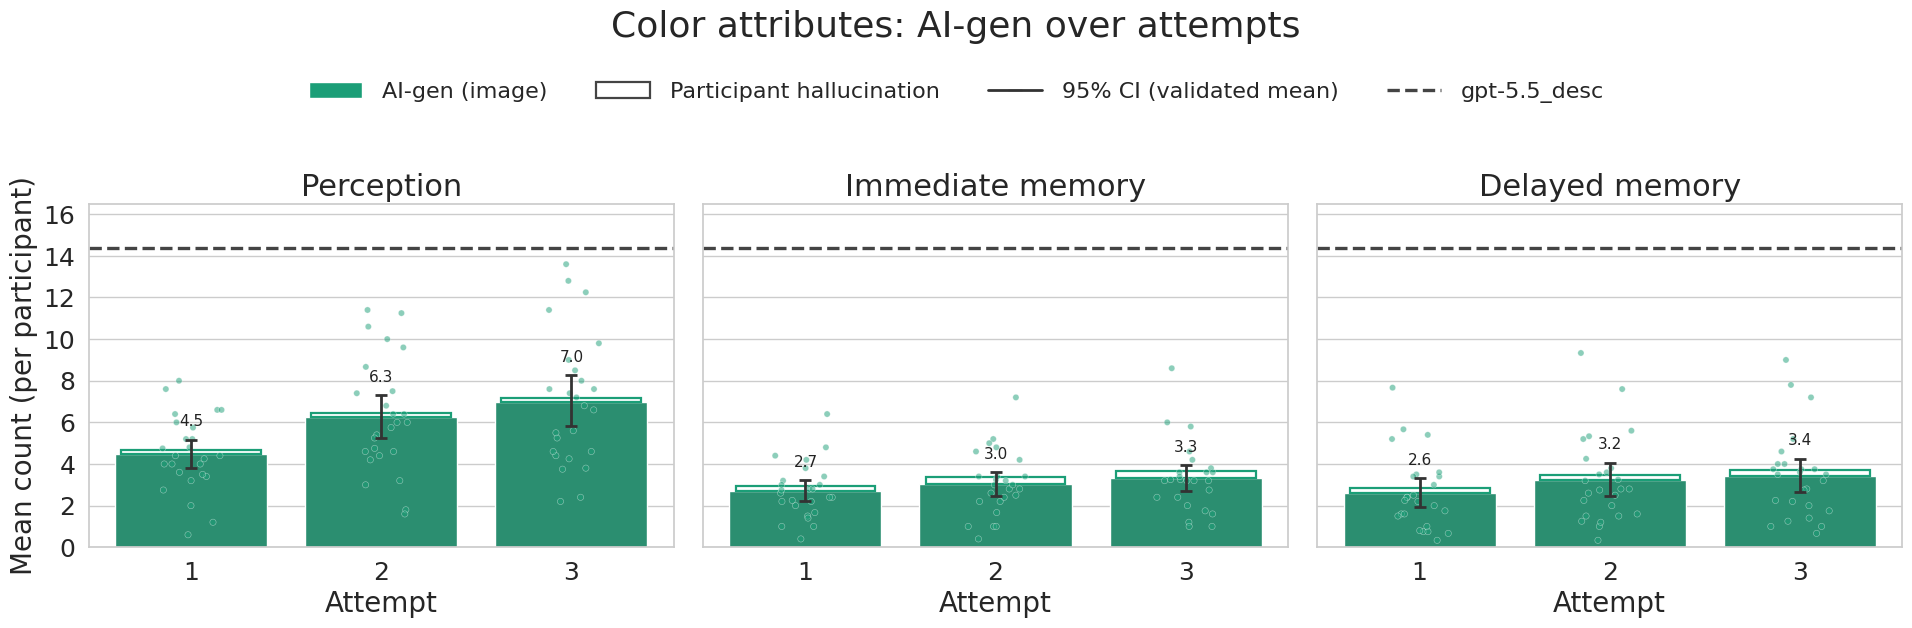

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q1_aigen_validated_adjectives_over_attempts.png


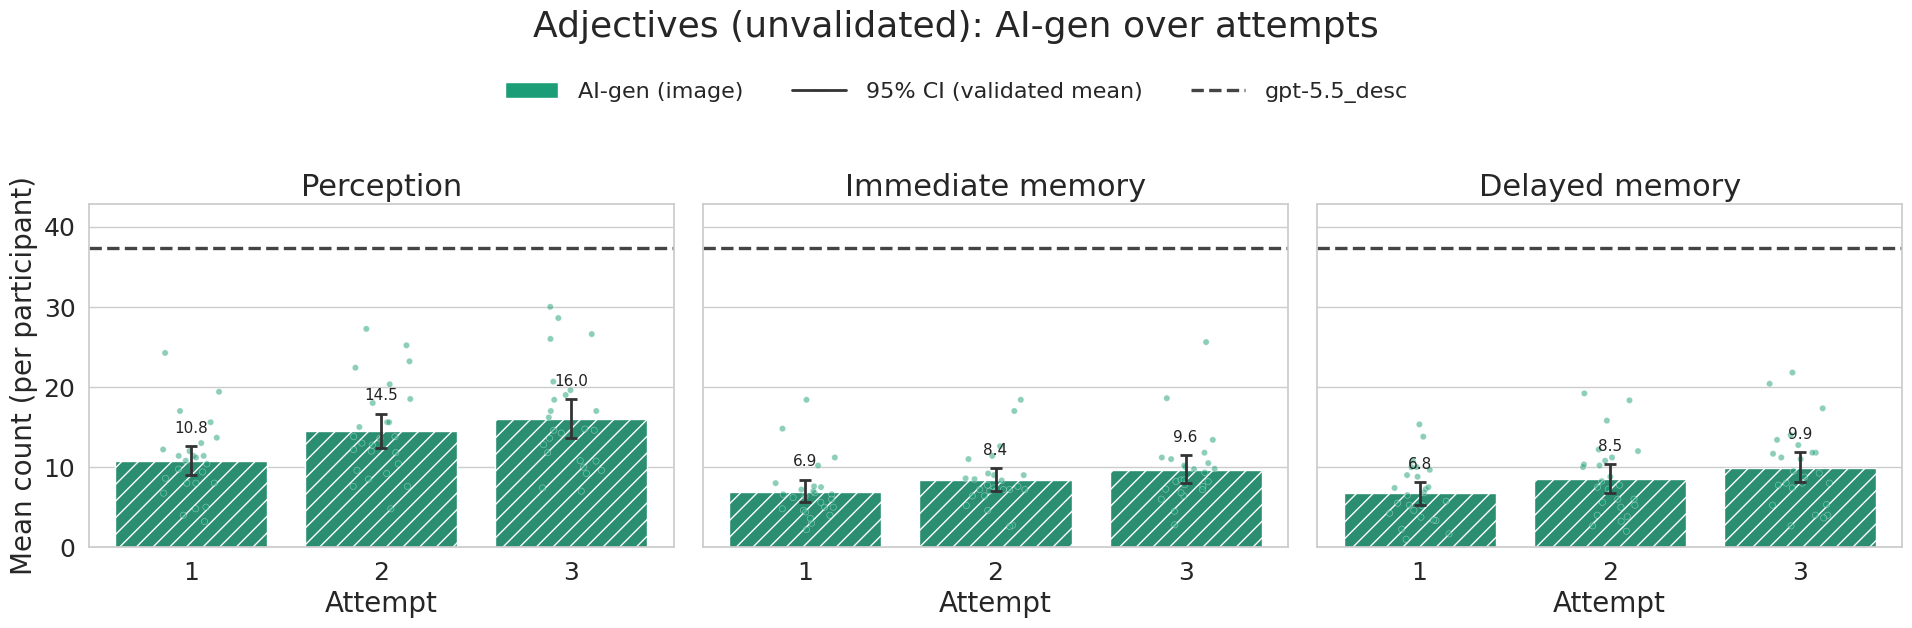

In [63]:
Q1 = {"aigen": None}
for category in CATEGORIES:
    plot_category_over_attempts(
        category, Q1,
        title=f"{cat_label(category)}: AI-gen over attempts",
        fname=f"q1_aigen_{COUNT_MODE}_{category}_over_attempts.png")

---
# 2a. aigen vs nogen — every semantic category over attempts
Same view, both feedback types side by side: does seeing the *generated image* change what
people write, compared with seeing only their own text? All tasks, all attempts.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q2a_aigen_vs_nogen_validated_objects_over_attempts.png


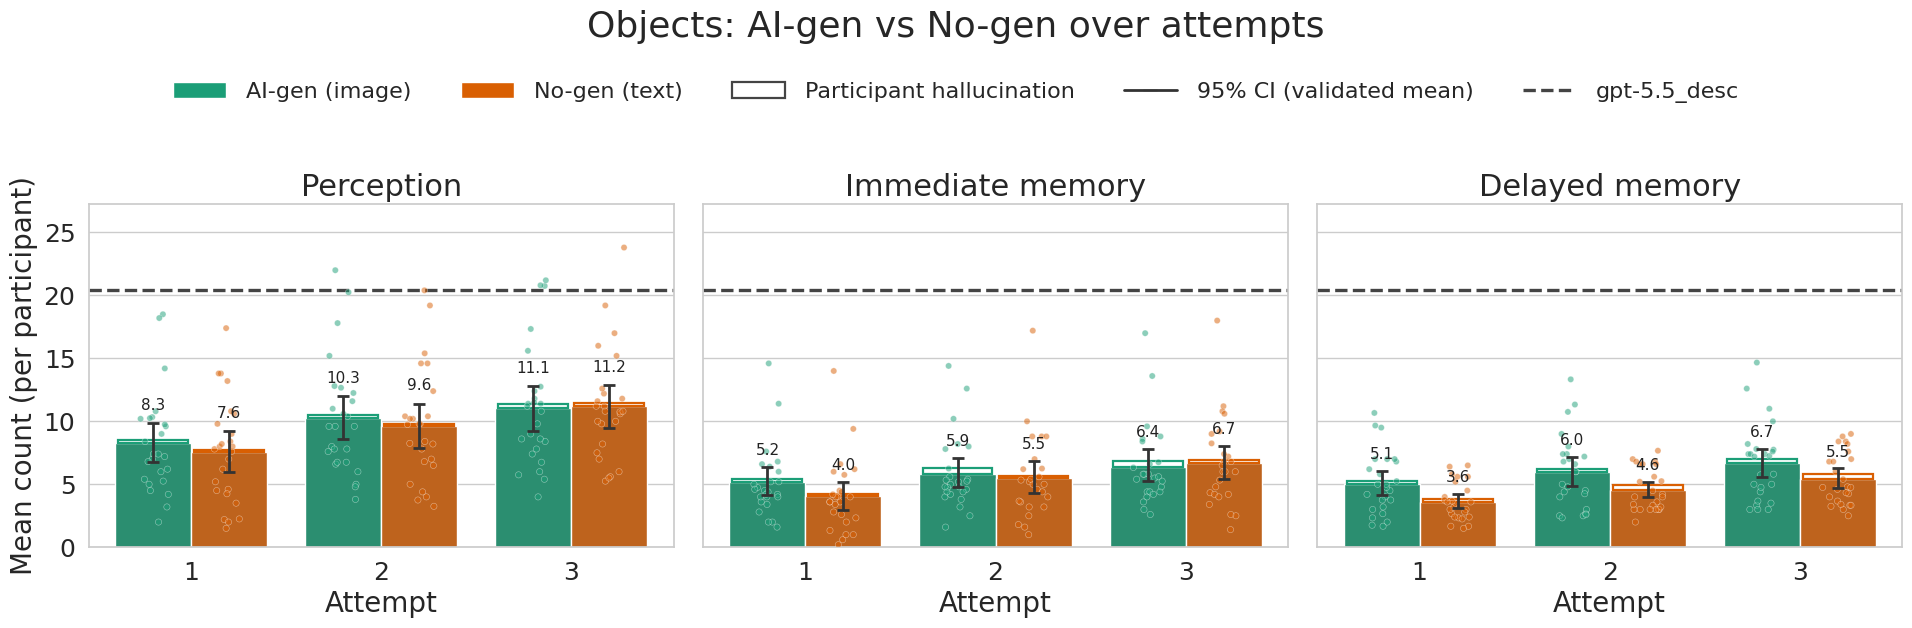

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q2a_aigen_vs_nogen_validated_stuff_over_attempts.png


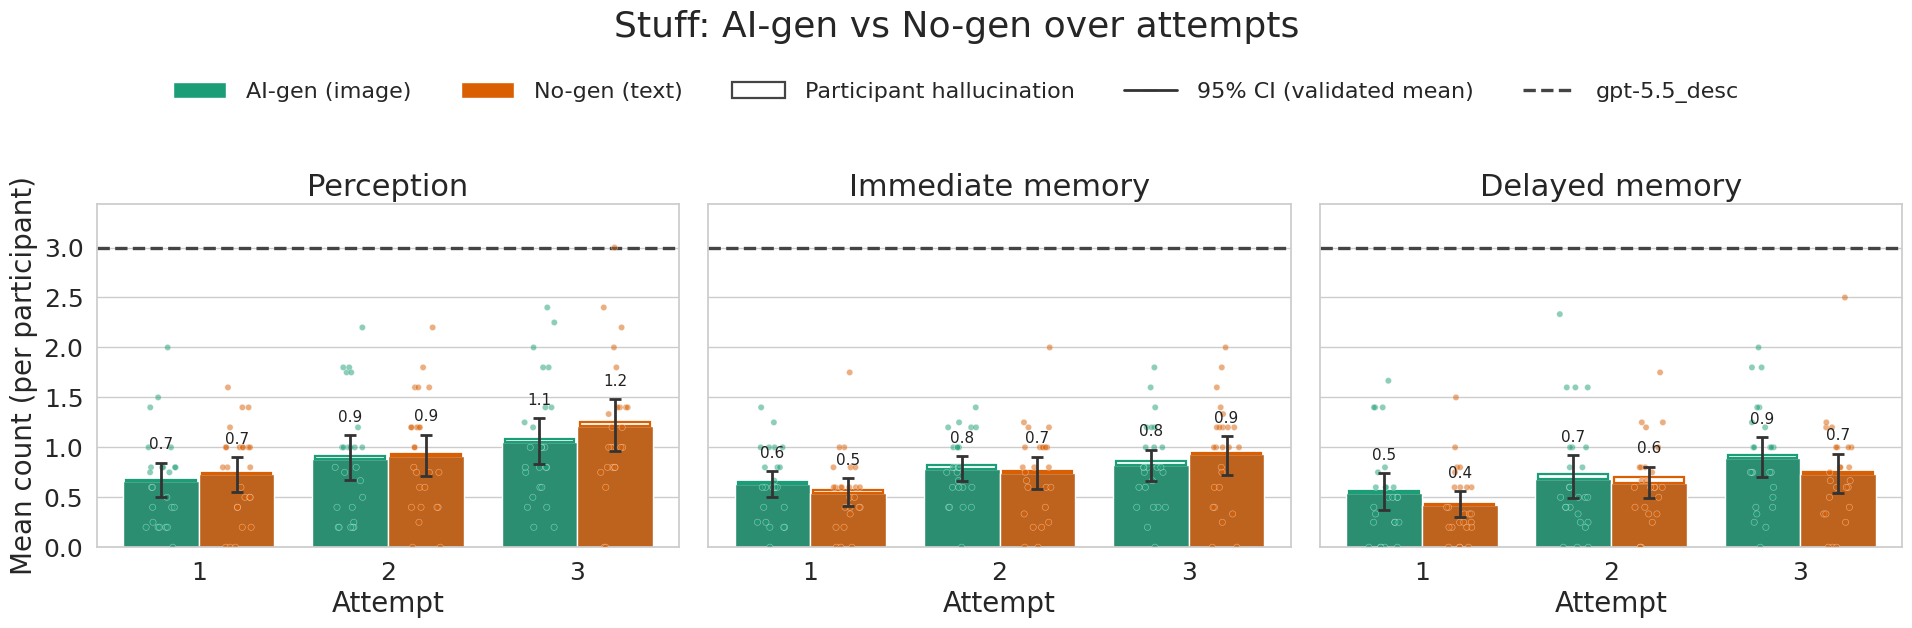

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q2a_aigen_vs_nogen_validated_scene_category_over_attempts.png


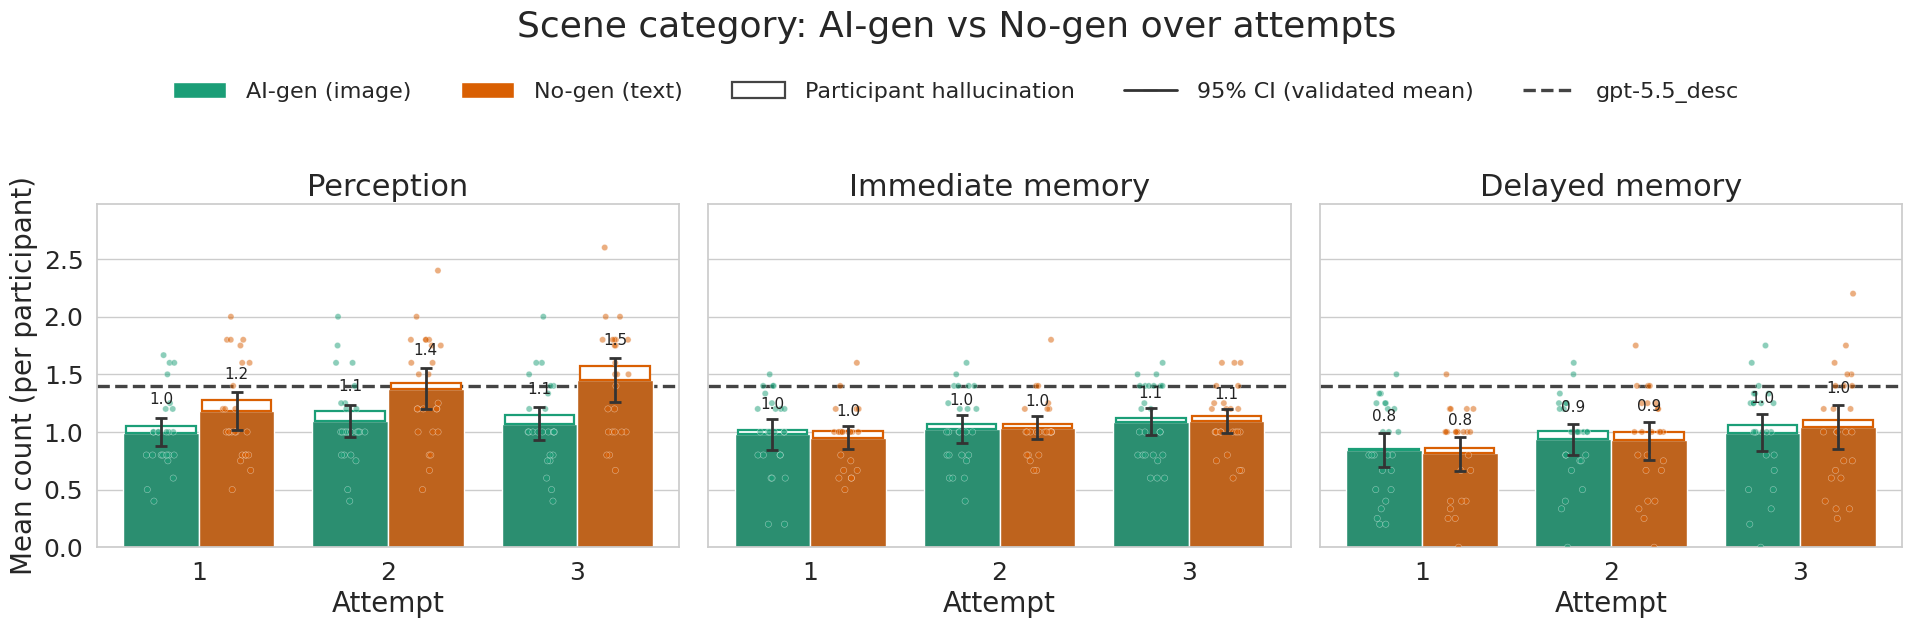

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q2a_aigen_vs_nogen_validated_spatial_relations_over_attempts.png


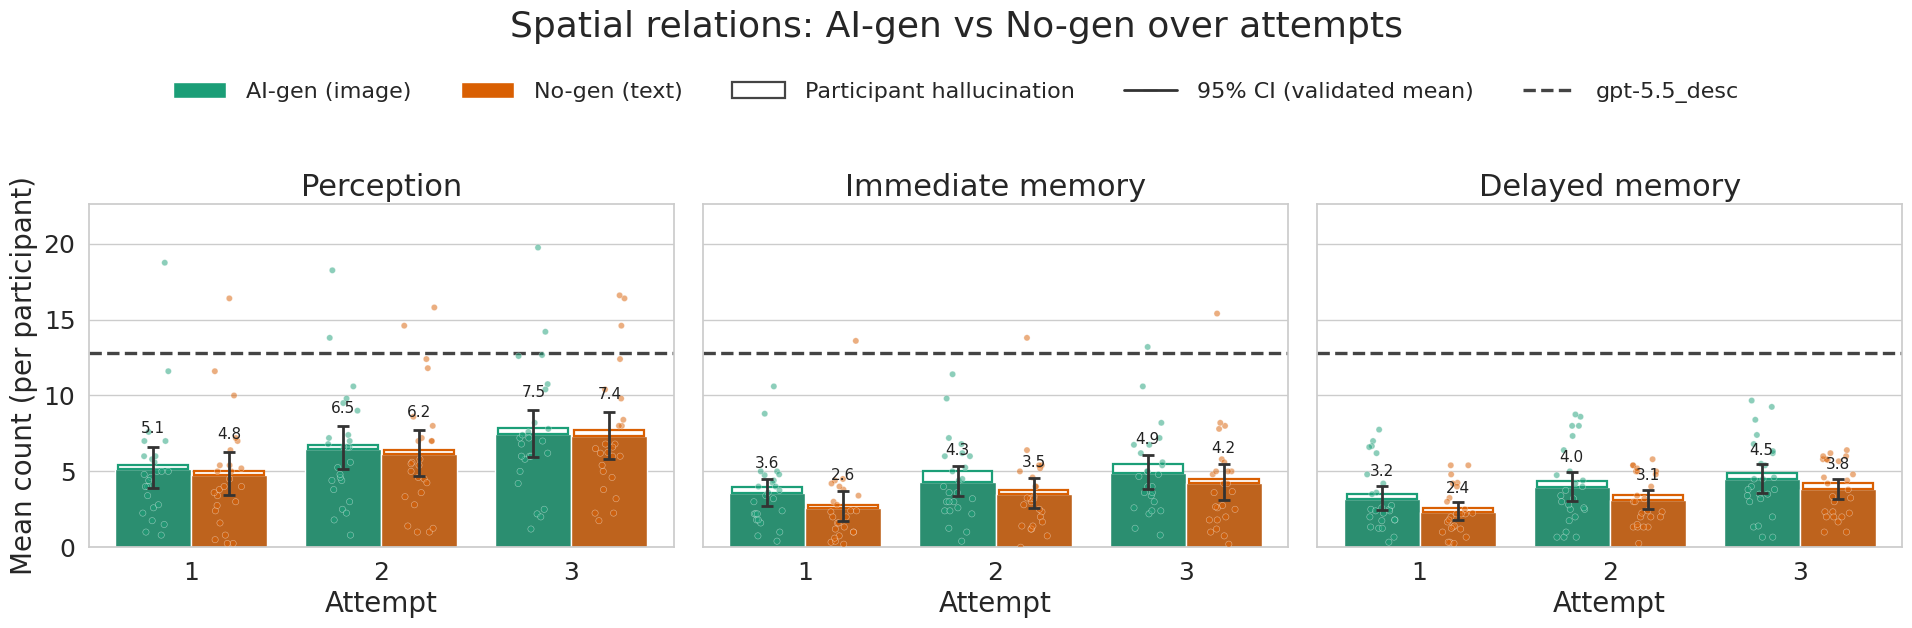

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q2a_aigen_vs_nogen_validated_attr_color_over_attempts.png


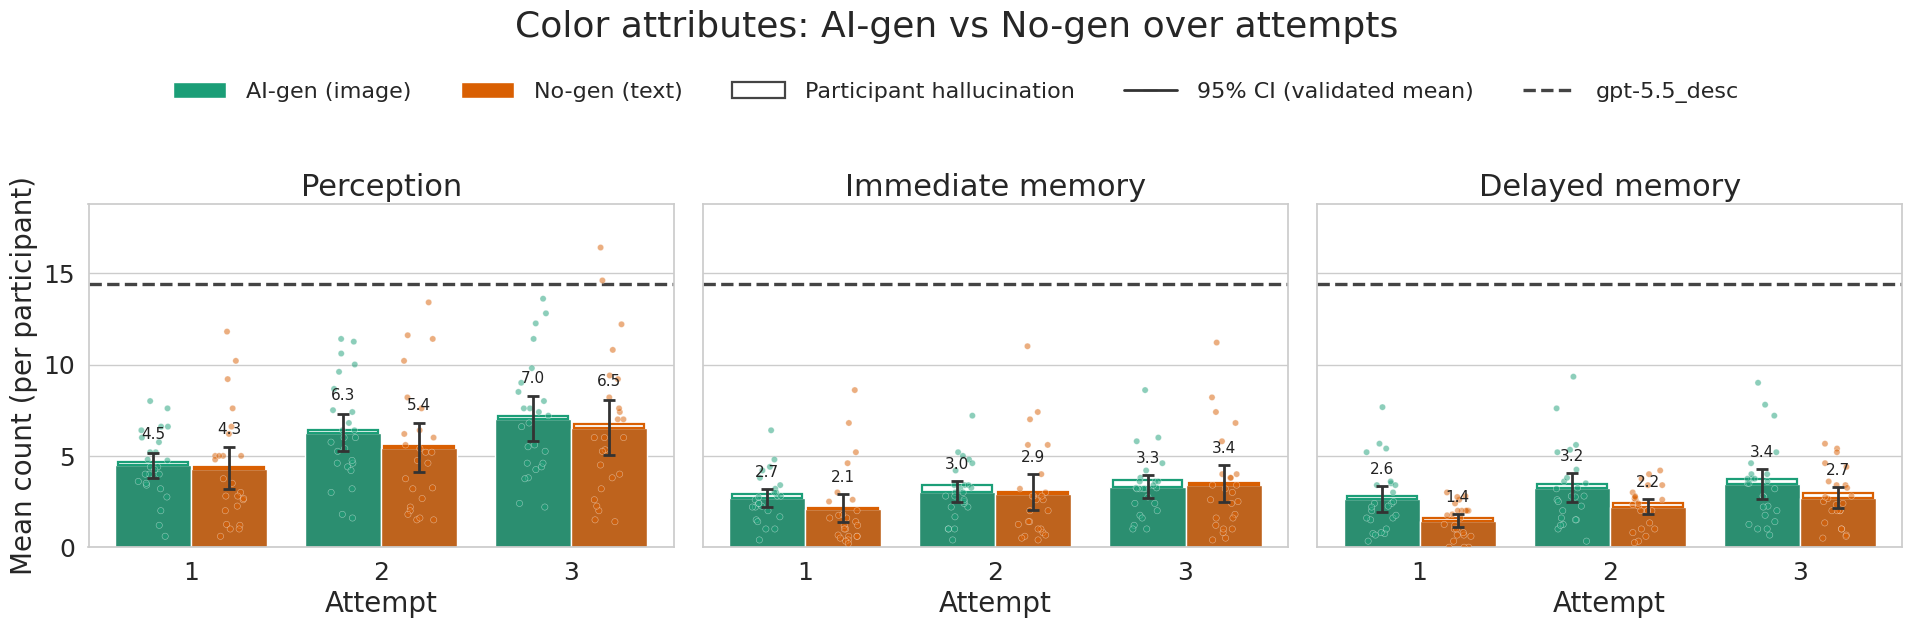

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q2a_aigen_vs_nogen_validated_adjectives_over_attempts.png


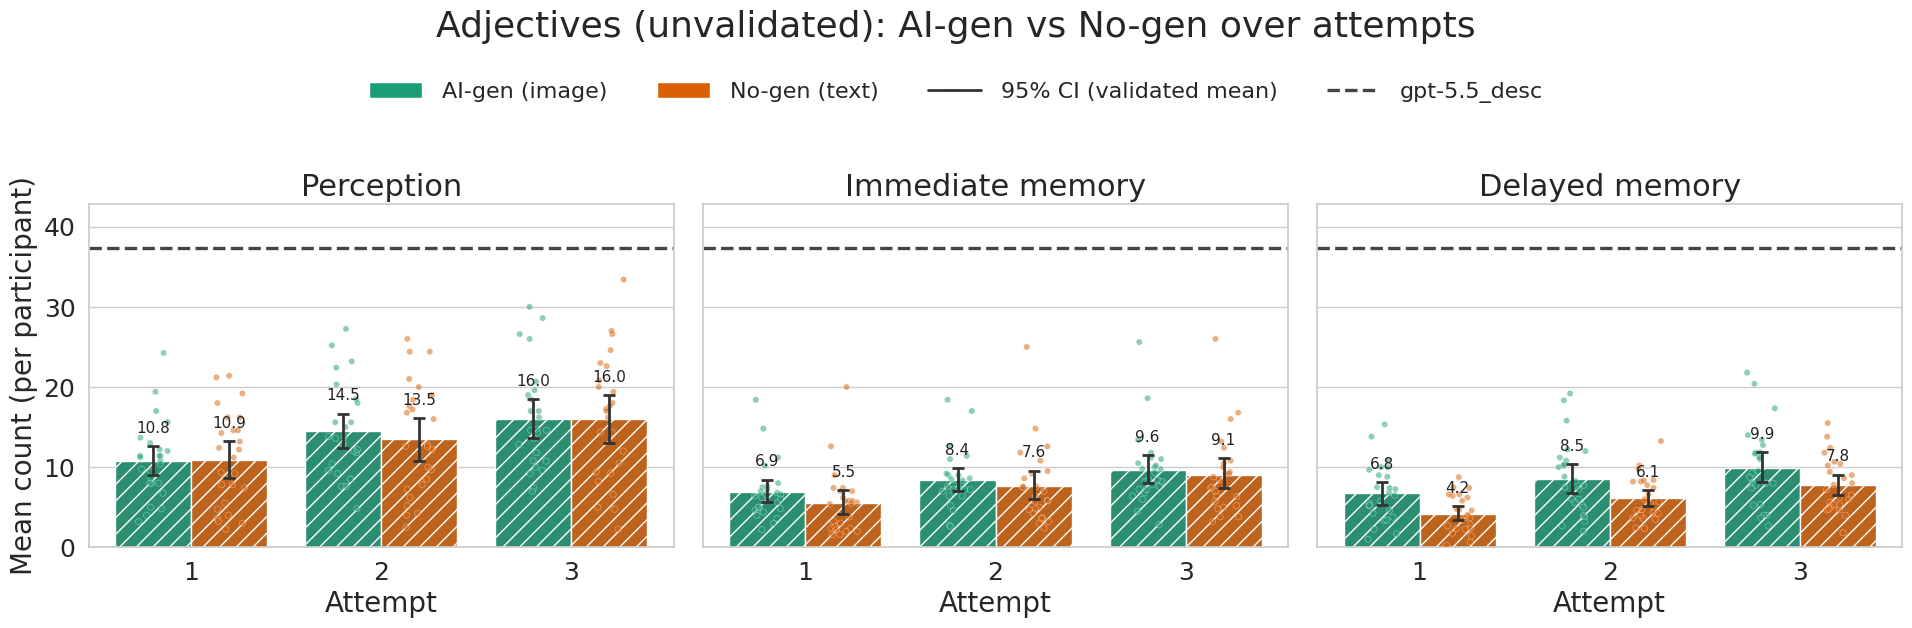

In [64]:
Q2 = {"aigen": None, "nogen": None}
for category in CATEGORIES:
    plot_category_over_attempts(
        category, Q2,
        title=f"{cat_label(category)}: AI-gen vs No-gen over attempts",
        fname=f"q2a_aigen_vs_nogen_{COUNT_MODE}_{category}_over_attempts.png")

# 2b. aigen vs nogen — image similarity of the generated image to the target
The same slice on the *pictures* rather than the words: CLIP and VGG fc7 similarity between the
image generated from a participant's prompt and the ground-truth image. Plotted as similarity
throughout (`1 - distance`), one line per generation with a 95% CI ribbon, faceted by task.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q2b_aigen_vs_nogen_clip_similarity_over_attempts.png


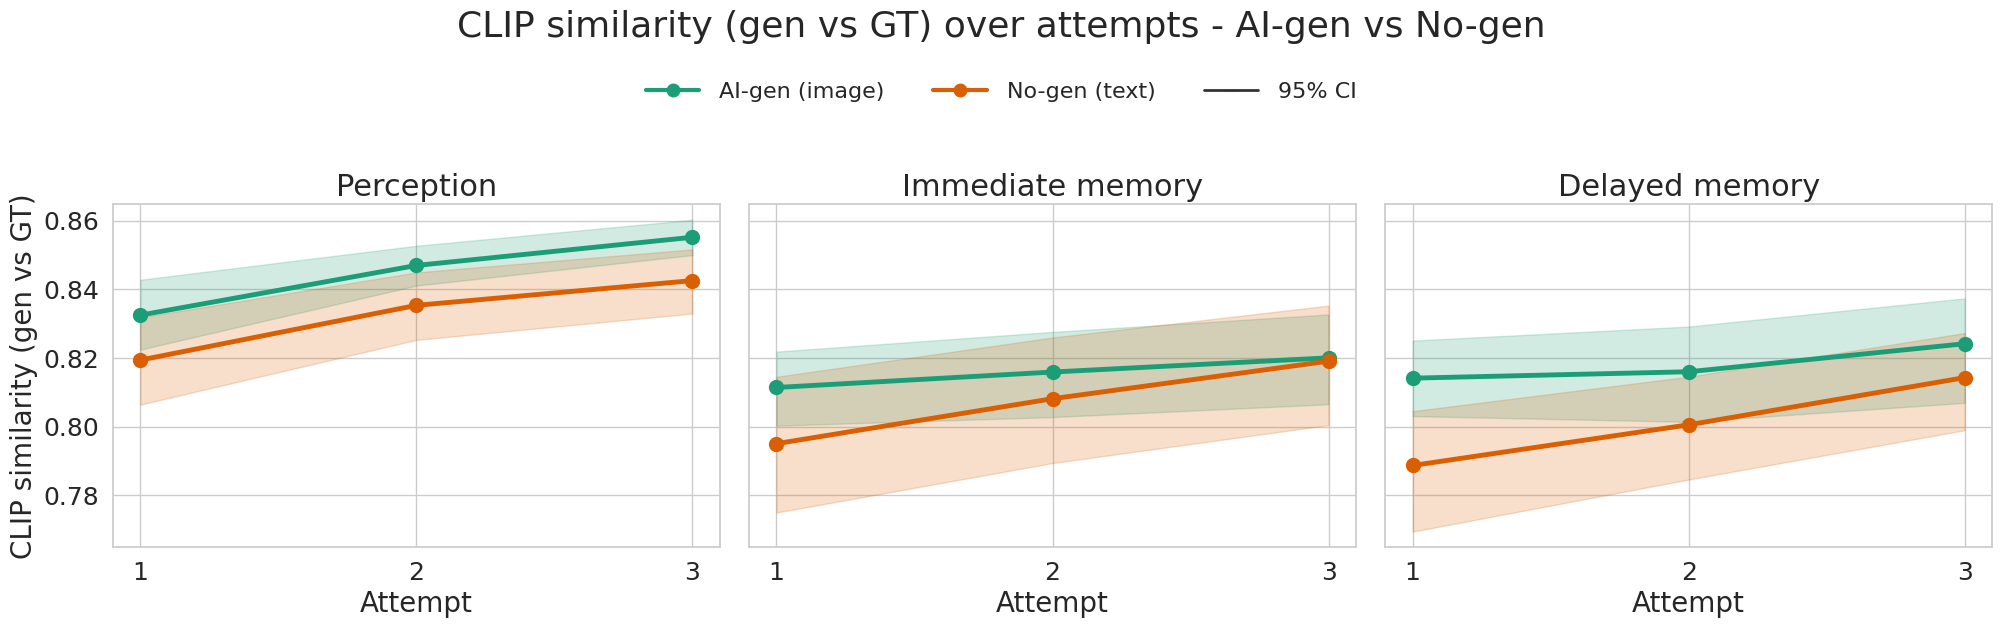

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q2b_aigen_vs_nogen_vgg_similarity_over_attempts.png


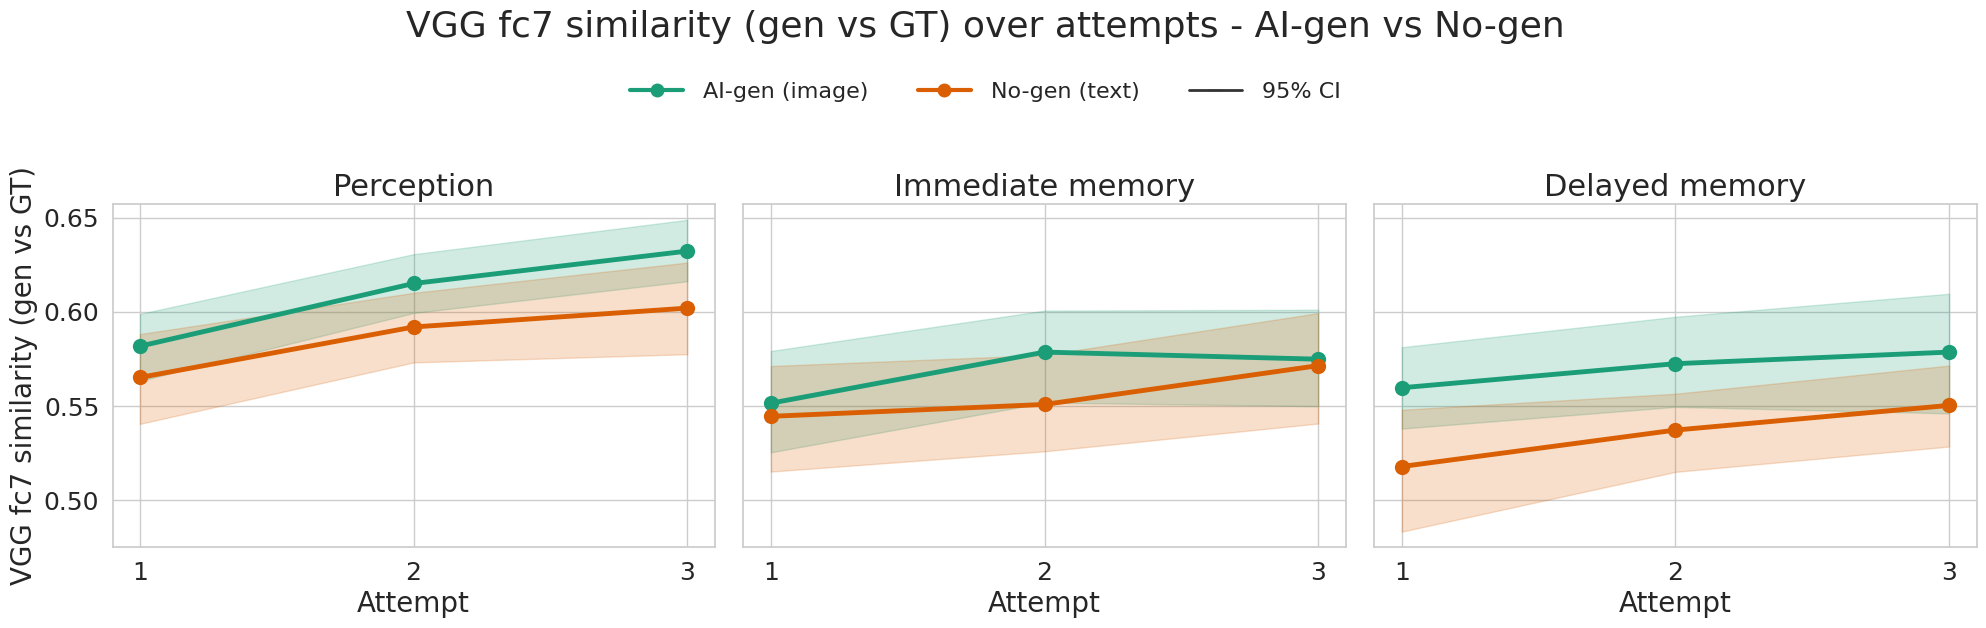

In [65]:
for metric in SIM_METRICS:
    plot_sim_over_attempts(
        metric, Q2,
        title=f"{SIM_METRICS[metric]} over attempts - AI-gen vs No-gen",
        fname=f"q2b_aigen_vs_nogen_{metric}_over_attempts.png")

---
# 3a. aigen vs plain — attempt 1 only
`plain` has no feedback loop: one description, one attempt. So the only fair comparison is
against the **first** attempt of the feedback conditions, before any feedback has been seen.
x = task, one bar per generation, one figure per category.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3a_aigen_vs_plain_validated_objects_attempt1.png


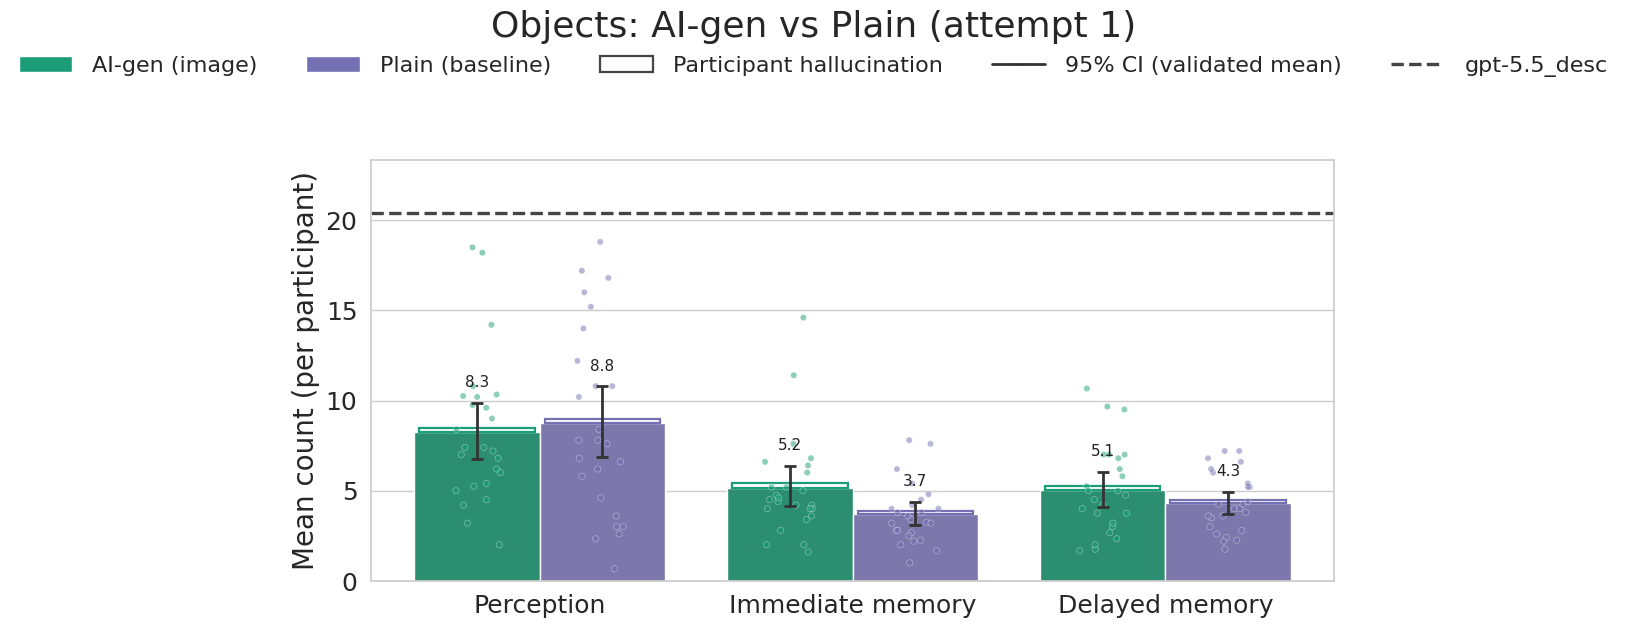

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3a_aigen_vs_plain_validated_stuff_attempt1.png


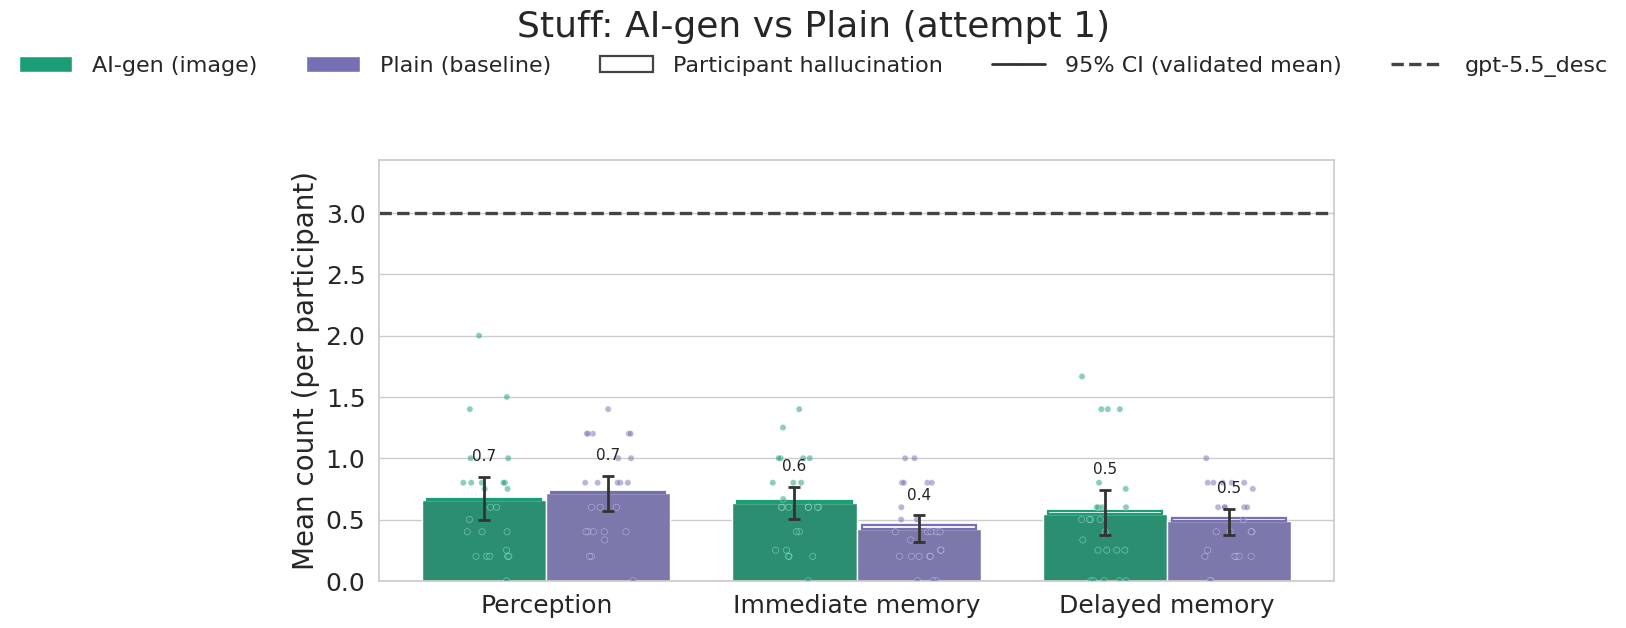

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3a_aigen_vs_plain_validated_scene_category_attempt1.png


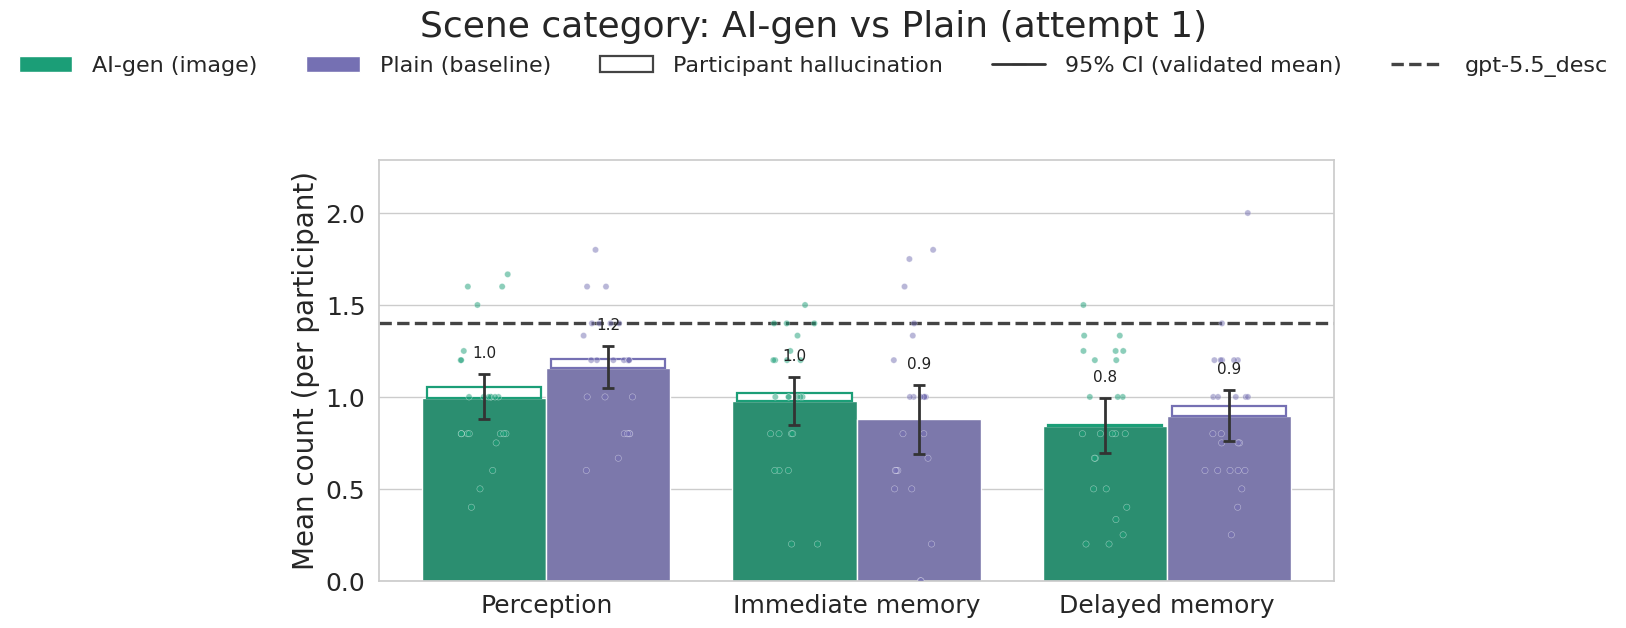

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3a_aigen_vs_plain_validated_spatial_relations_attempt1.png


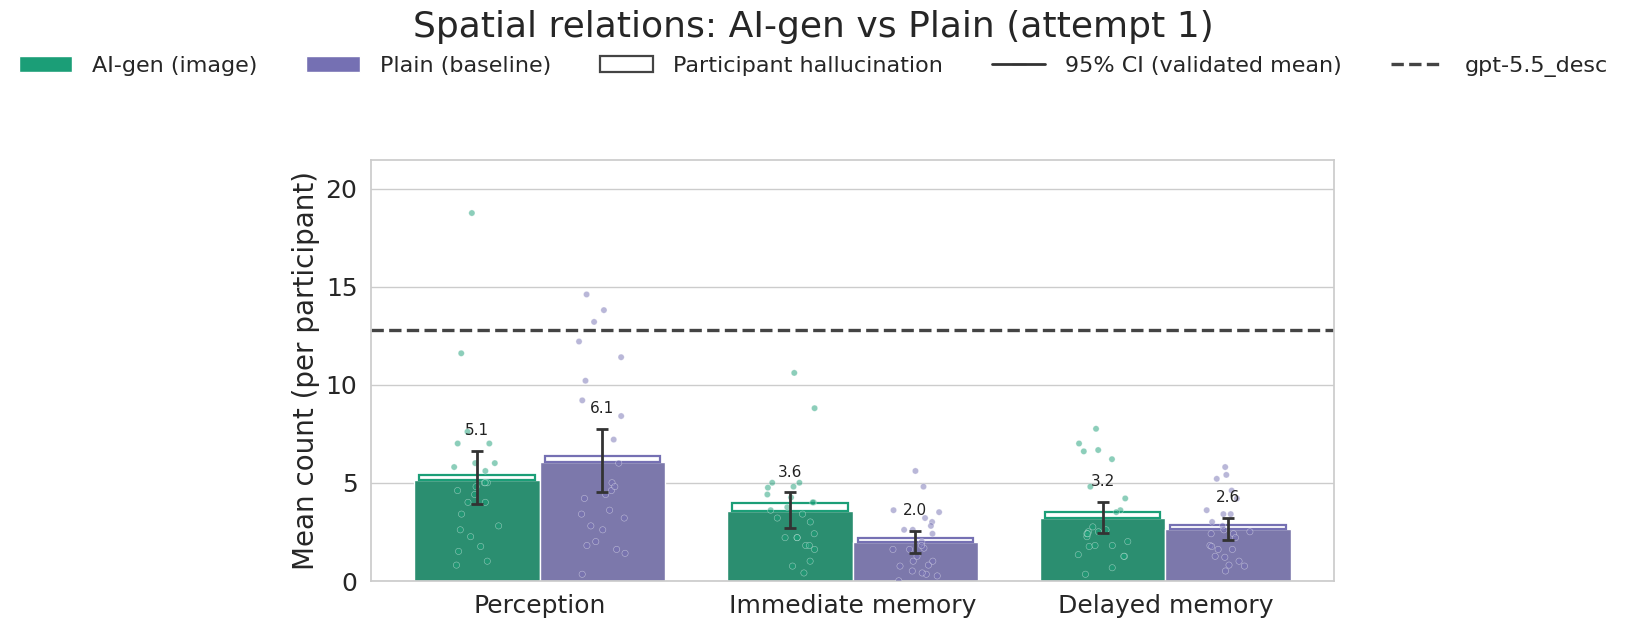

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3a_aigen_vs_plain_validated_attr_color_attempt1.png


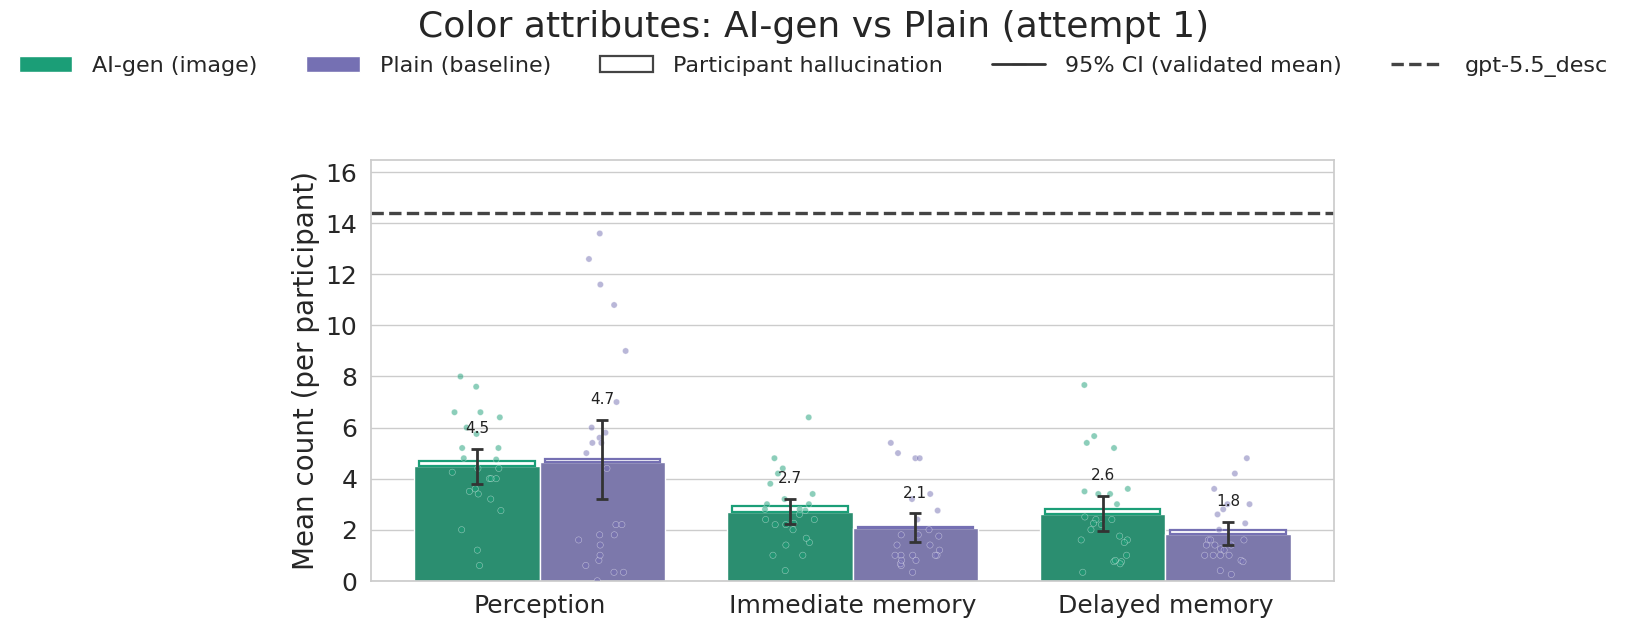

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3a_aigen_vs_plain_validated_adjectives_attempt1.png


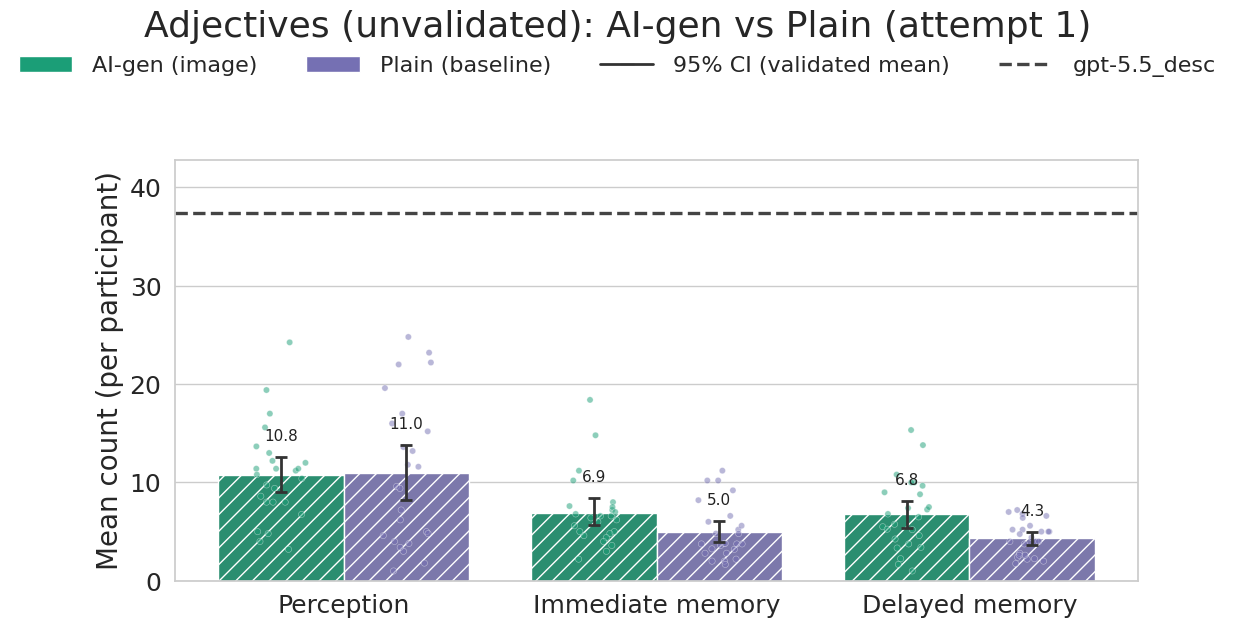

In [66]:
Q3A = {"aigen": 1, "plain": 1}
for category in CATEGORIES:
    plot_category_by_task(
        category, Q3A,
        title=f"{cat_label(category)}: AI-gen vs Plain (attempt 1)",
        fname=f"q3a_aigen_vs_plain_{COUNT_MODE}_{category}_attempt1.png")

# 3b. nogen vs plain — attempt 1 only
Same comparison for the text-only feedback condition.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3b_nogen_vs_plain_validated_objects_attempt1.png


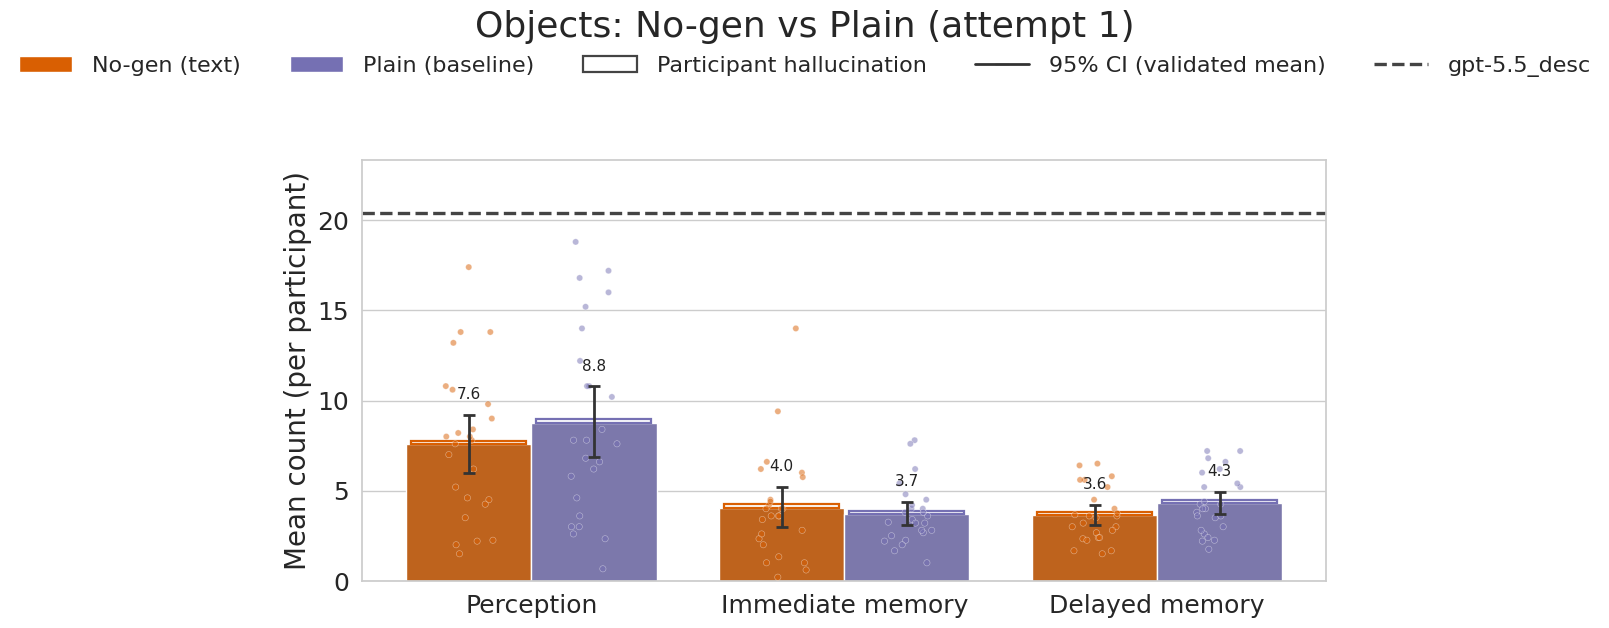

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3b_nogen_vs_plain_validated_stuff_attempt1.png


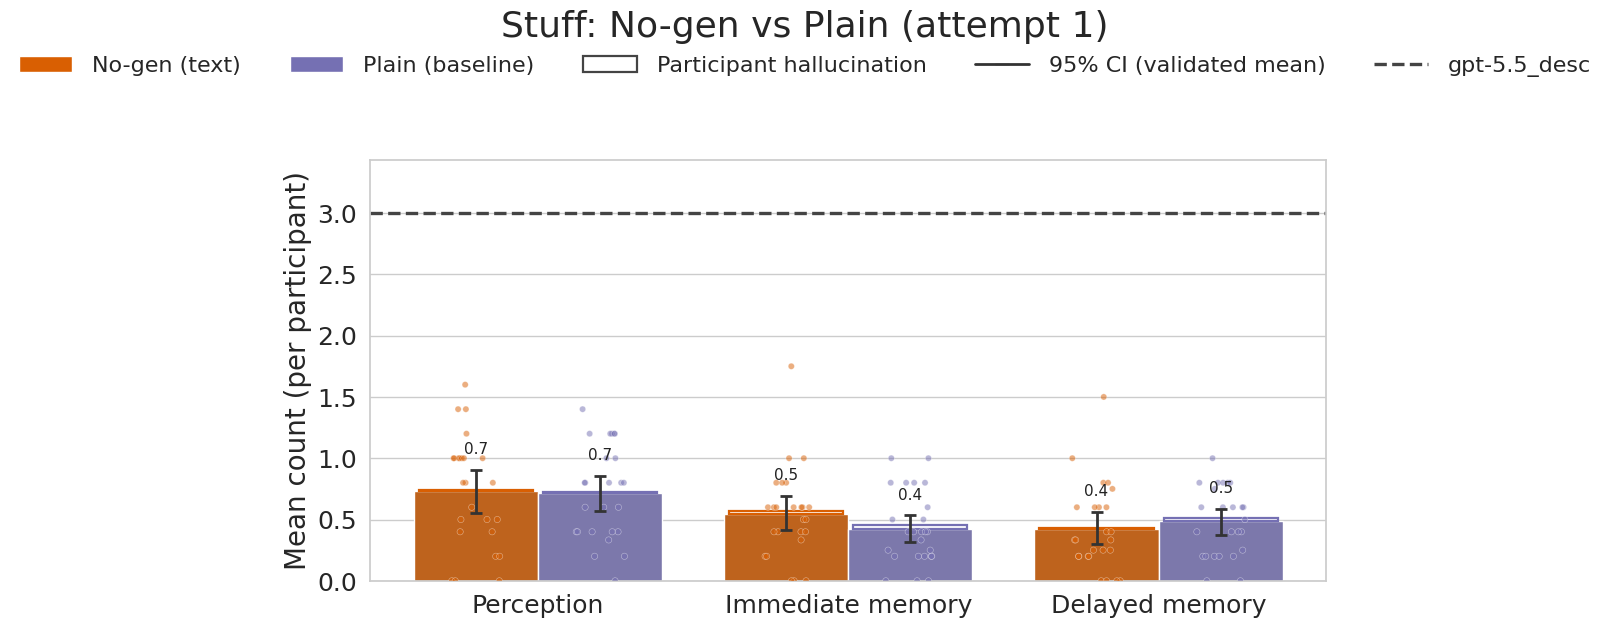

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3b_nogen_vs_plain_validated_scene_category_attempt1.png


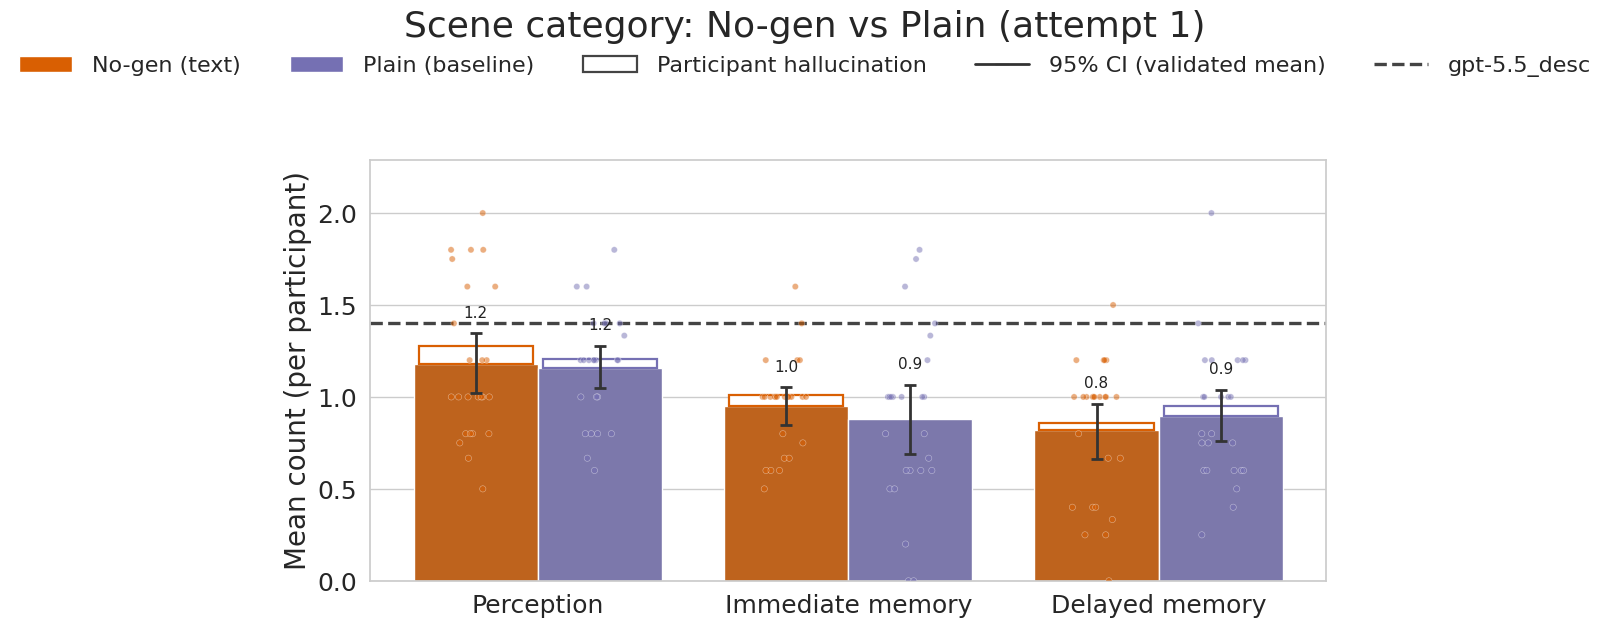

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3b_nogen_vs_plain_validated_spatial_relations_attempt1.png


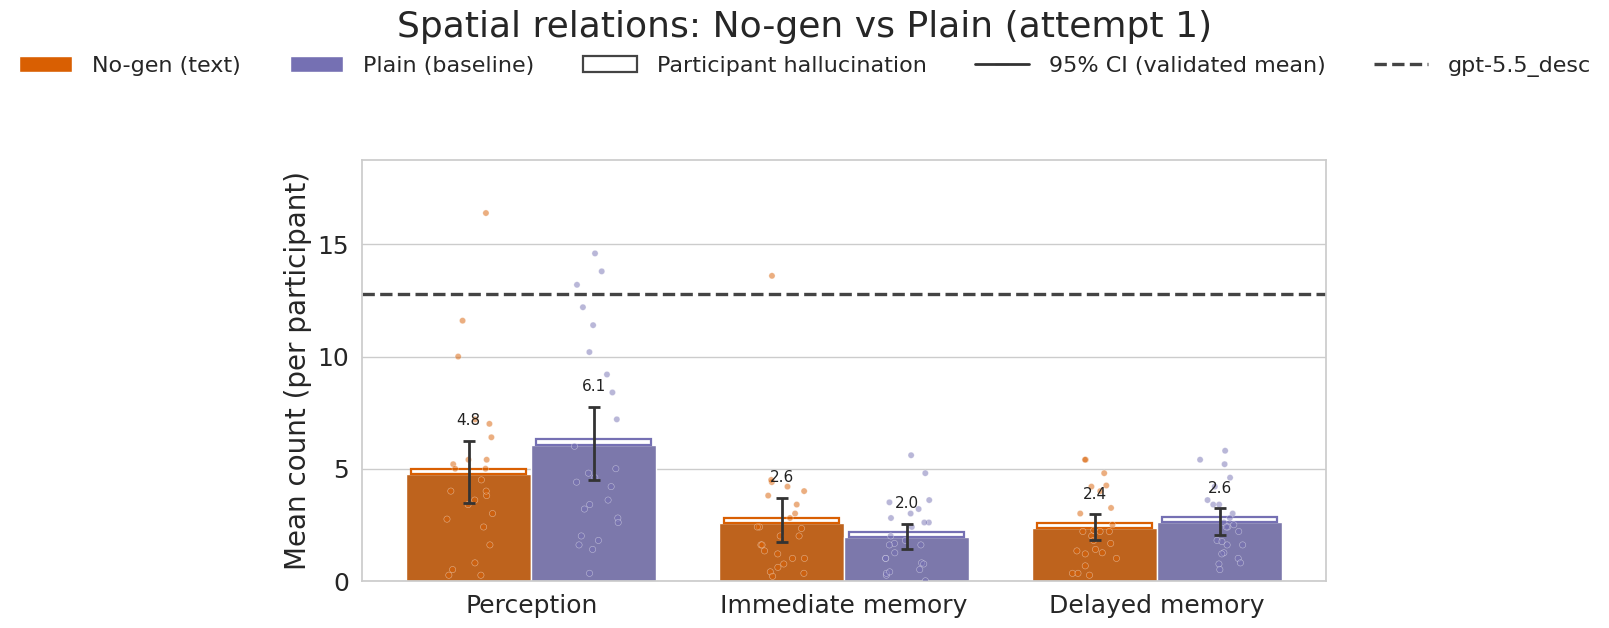

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3b_nogen_vs_plain_validated_attr_color_attempt1.png


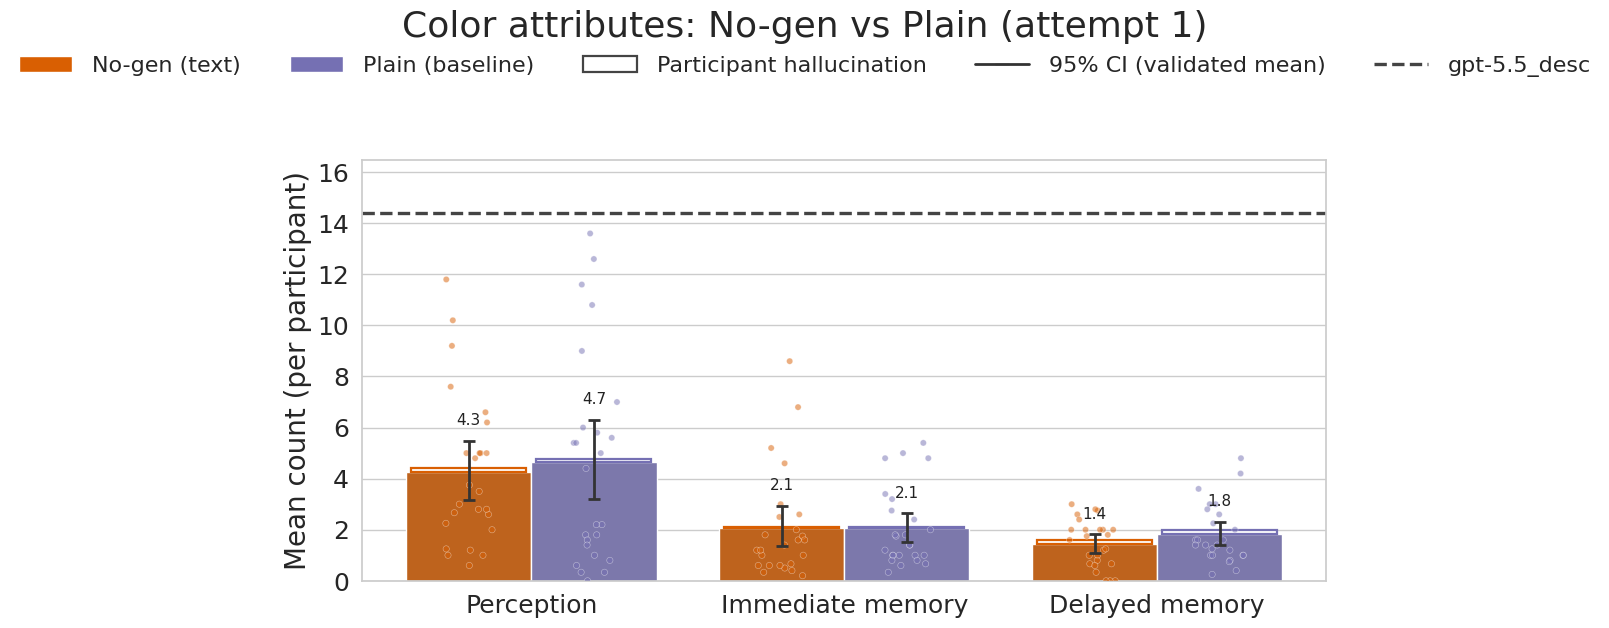

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3b_nogen_vs_plain_validated_adjectives_attempt1.png


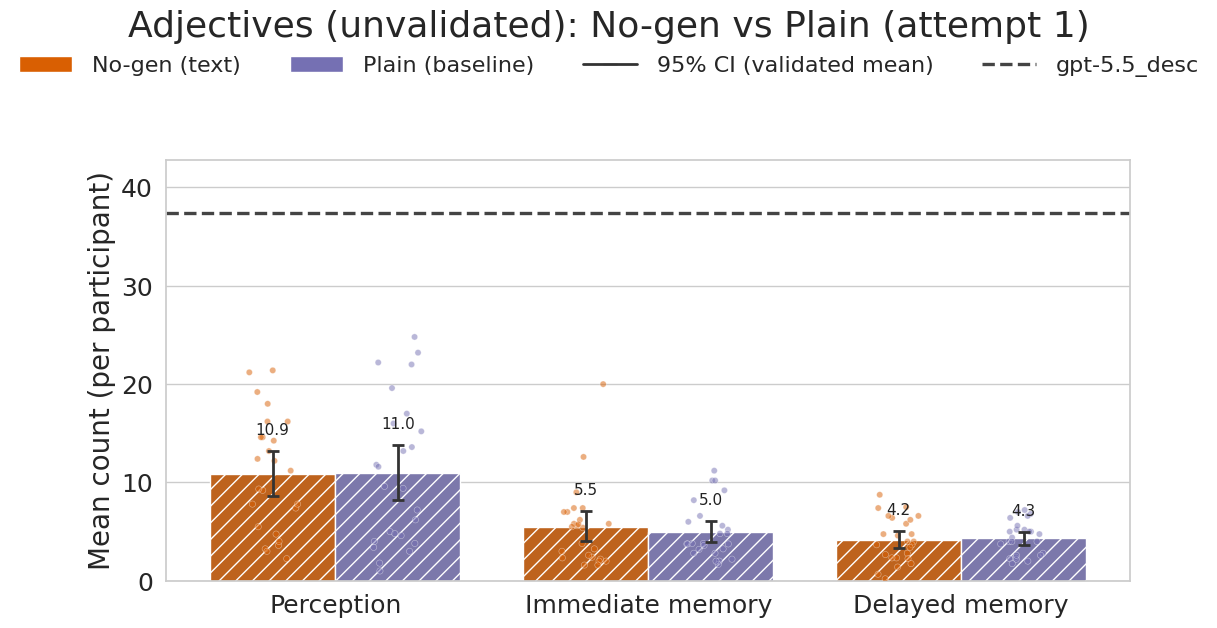

In [67]:
Q3B = {"nogen": 1, "plain": 1}
for category in CATEGORIES:
    plot_category_by_task(
        category, Q3B,
        title=f"{cat_label(category)}: No-gen vs Plain (attempt 1)",
        fname=f"q3b_nogen_vs_plain_{COUNT_MODE}_{category}_attempt1.png")

---
# 3c. aigen vs nogen vs plain — similarity of the *first* image
All three feedback types on the first generated image only, so every condition contributes the
same thing: one image per participant per target, produced before any feedback.

**One panel per task, one column per condition**, each column showing the per-participant means
(faded dots) with the group mean and its 95% bootstrap CI on top. Drawn as points rather than
bars because the differences between feedback types are a couple of hundredths of a similarity
point: a bar encodes its value by length from zero, so a truncated bar axis exaggerates ratios,
while a point only encodes position and lets the axis start at the data.

The y window fits the CIs and the inner 96% of the dots — the spread across participants is much
wider than the gap between the means, so the extreme tails are cut and counted in the corner of
the panel rather than allowed to flatten the picture. Overlapping CIs are the honest read here;
the zoom makes the differences legible, it does not make them significant.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3c_all_gens_clip_similarity_attempt1.png


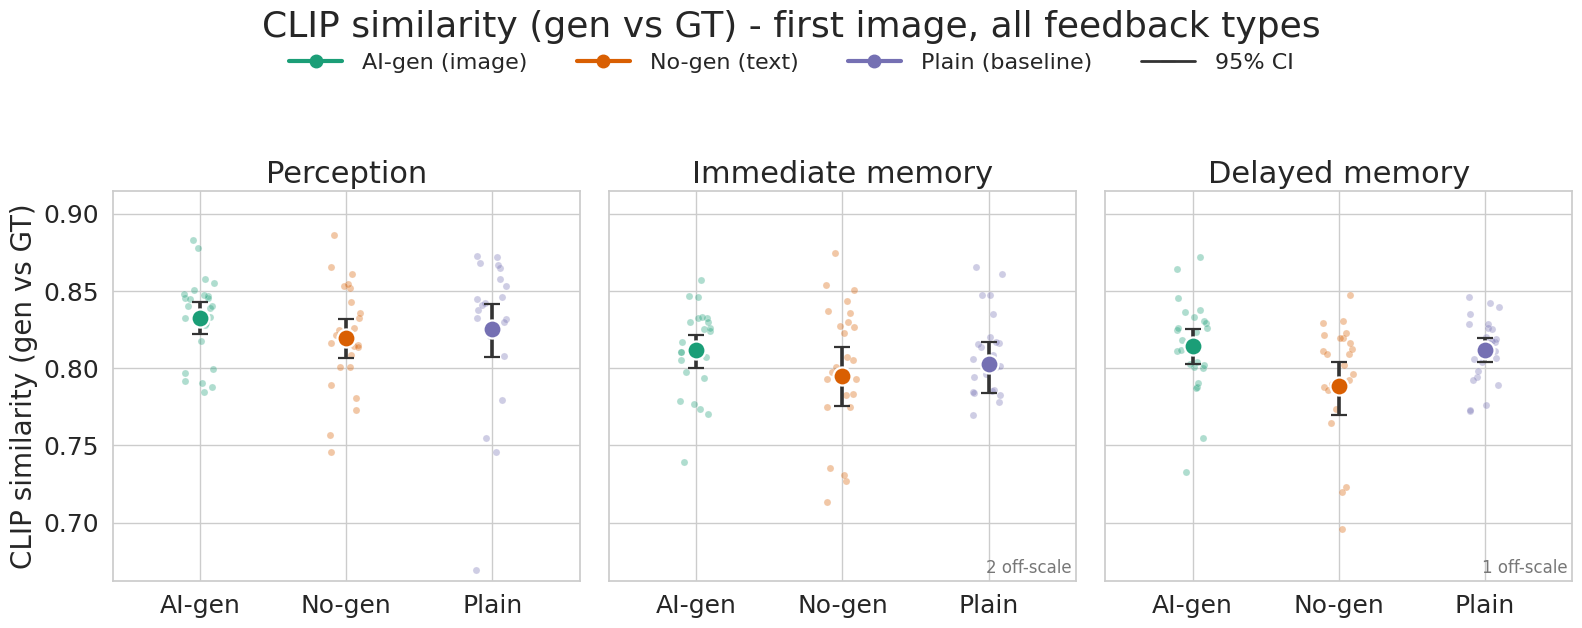

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q3c_all_gens_vgg_similarity_attempt1.png


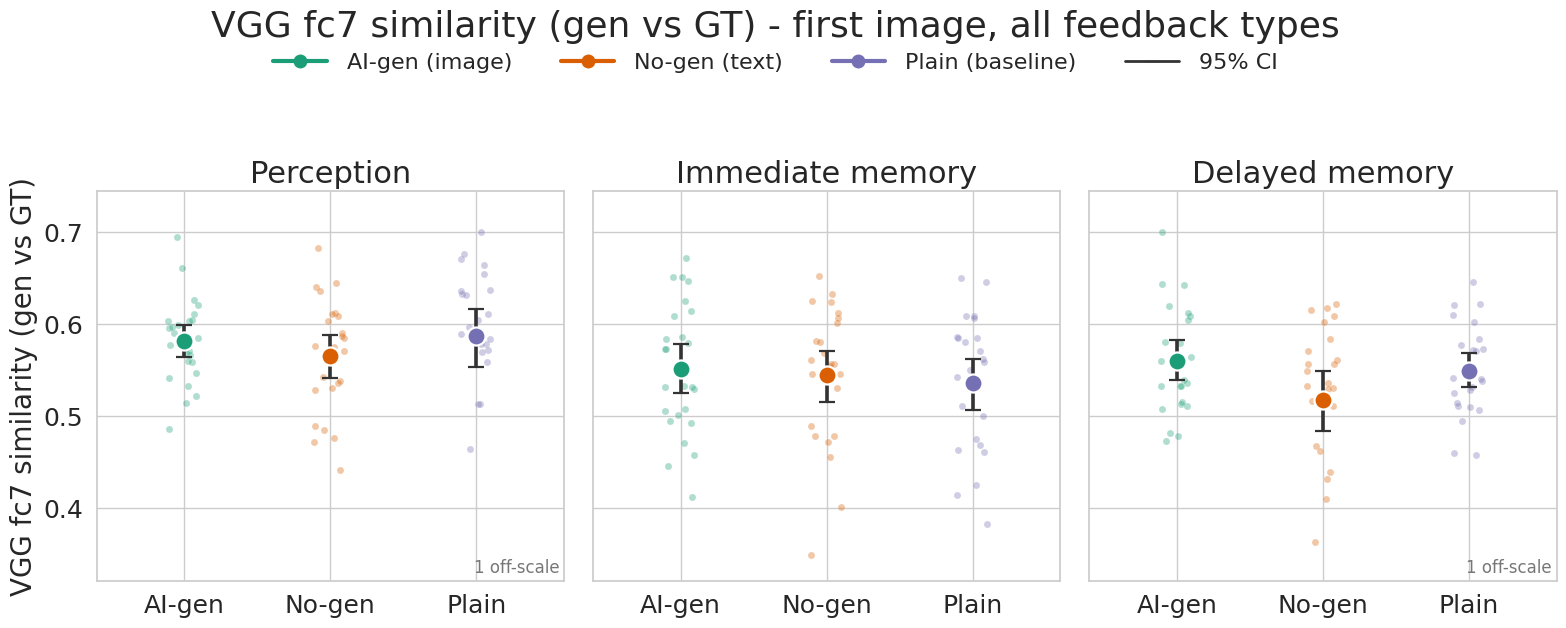

In [68]:
Q3C = {"aigen": 1, "nogen": 1, "plain": 1}
# One panel per task, one column per condition, participant dots behind the mean + 95% CI,
# y zoomed to the data. dots=False zooms tighter (CIs only); panels=False falls back to the
# single axis with the conditions dodged inside each task; ylim=(lo, hi) pins the window.
for metric in SIM_METRICS:
    plot_sim_by_task_points(
        metric, Q3C,
        title=f"{SIM_METRICS[metric]} - first image, all feedback types",
        fname=f"q3c_all_gens_{metric}_attempt1.png")


---
# 4. aigen, nogen, plain — every category at once, one figure per task
The panel-grid view from `cross_gen_in_image_semantic_counts.ipynb` (its View 3), run on the
combined full data: one figure for perception, immediate and delay, each holding all six
categories over attempts.

`plain` contributes a single attempt-1 bar by design, so its slot is empty at attempts 2-3.
Each panel has its own y scale, so the hallucination caps are not comparable in height *across*
panels — only within one.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q4_all_gens_validated_all_categories_perception.png


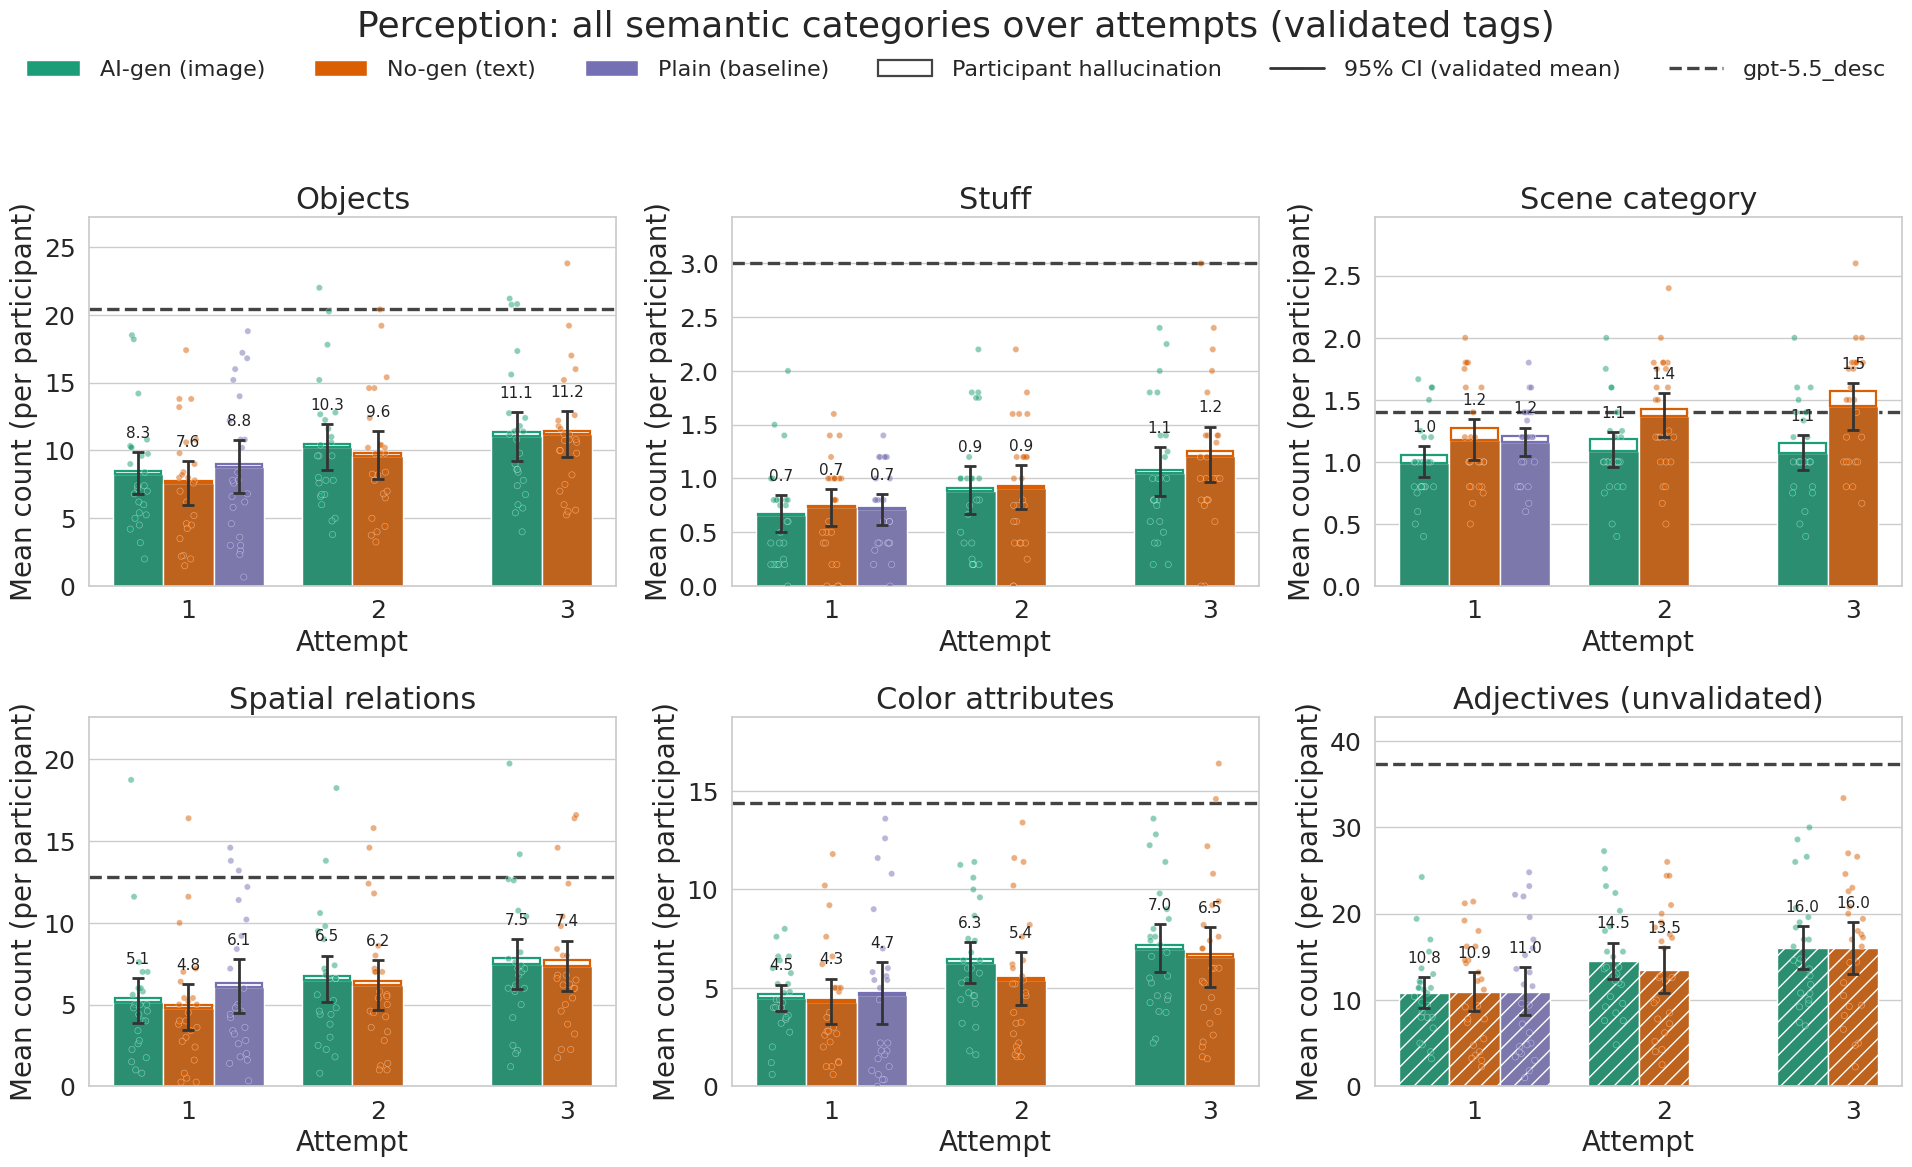

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q4_all_gens_validated_all_categories_immediate.png


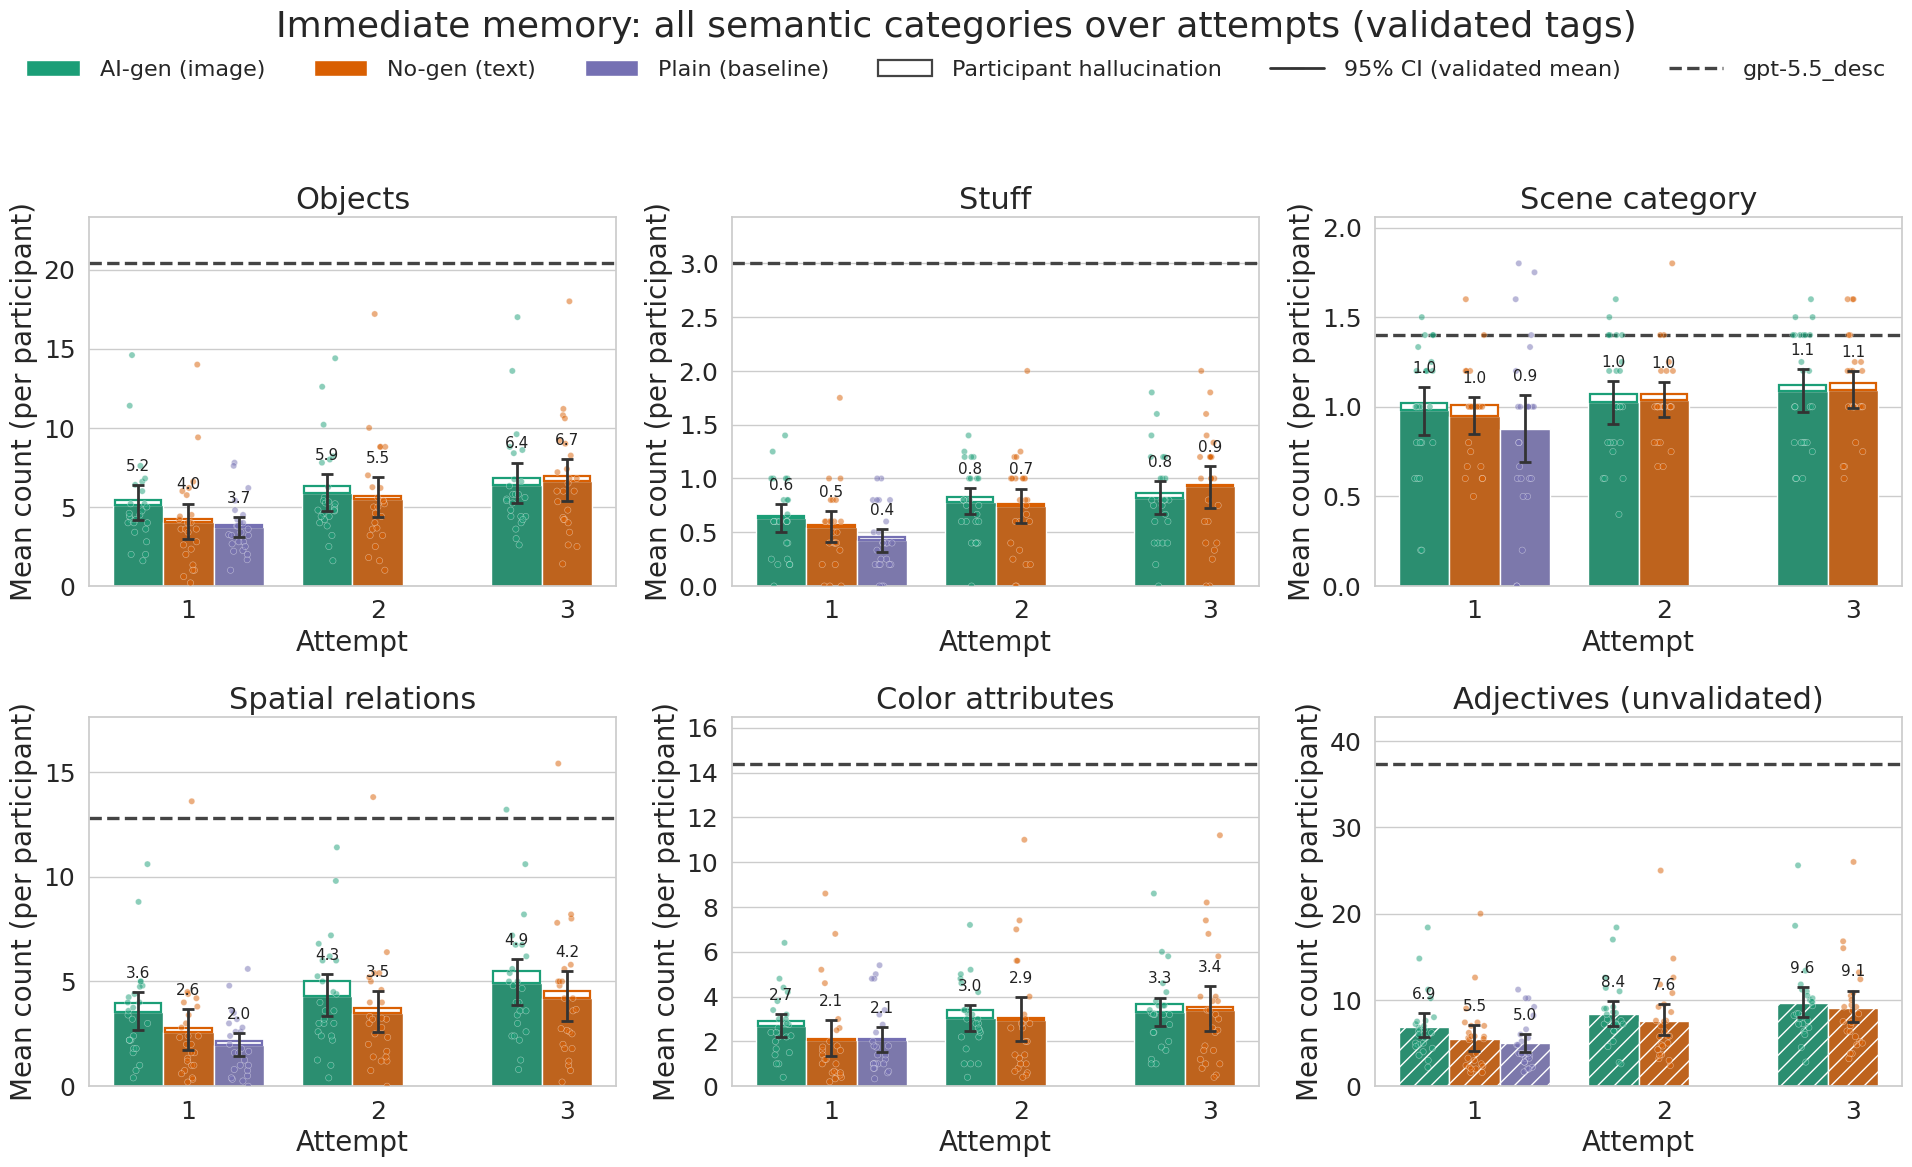

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q4_all_gens_validated_all_categories_delay.png


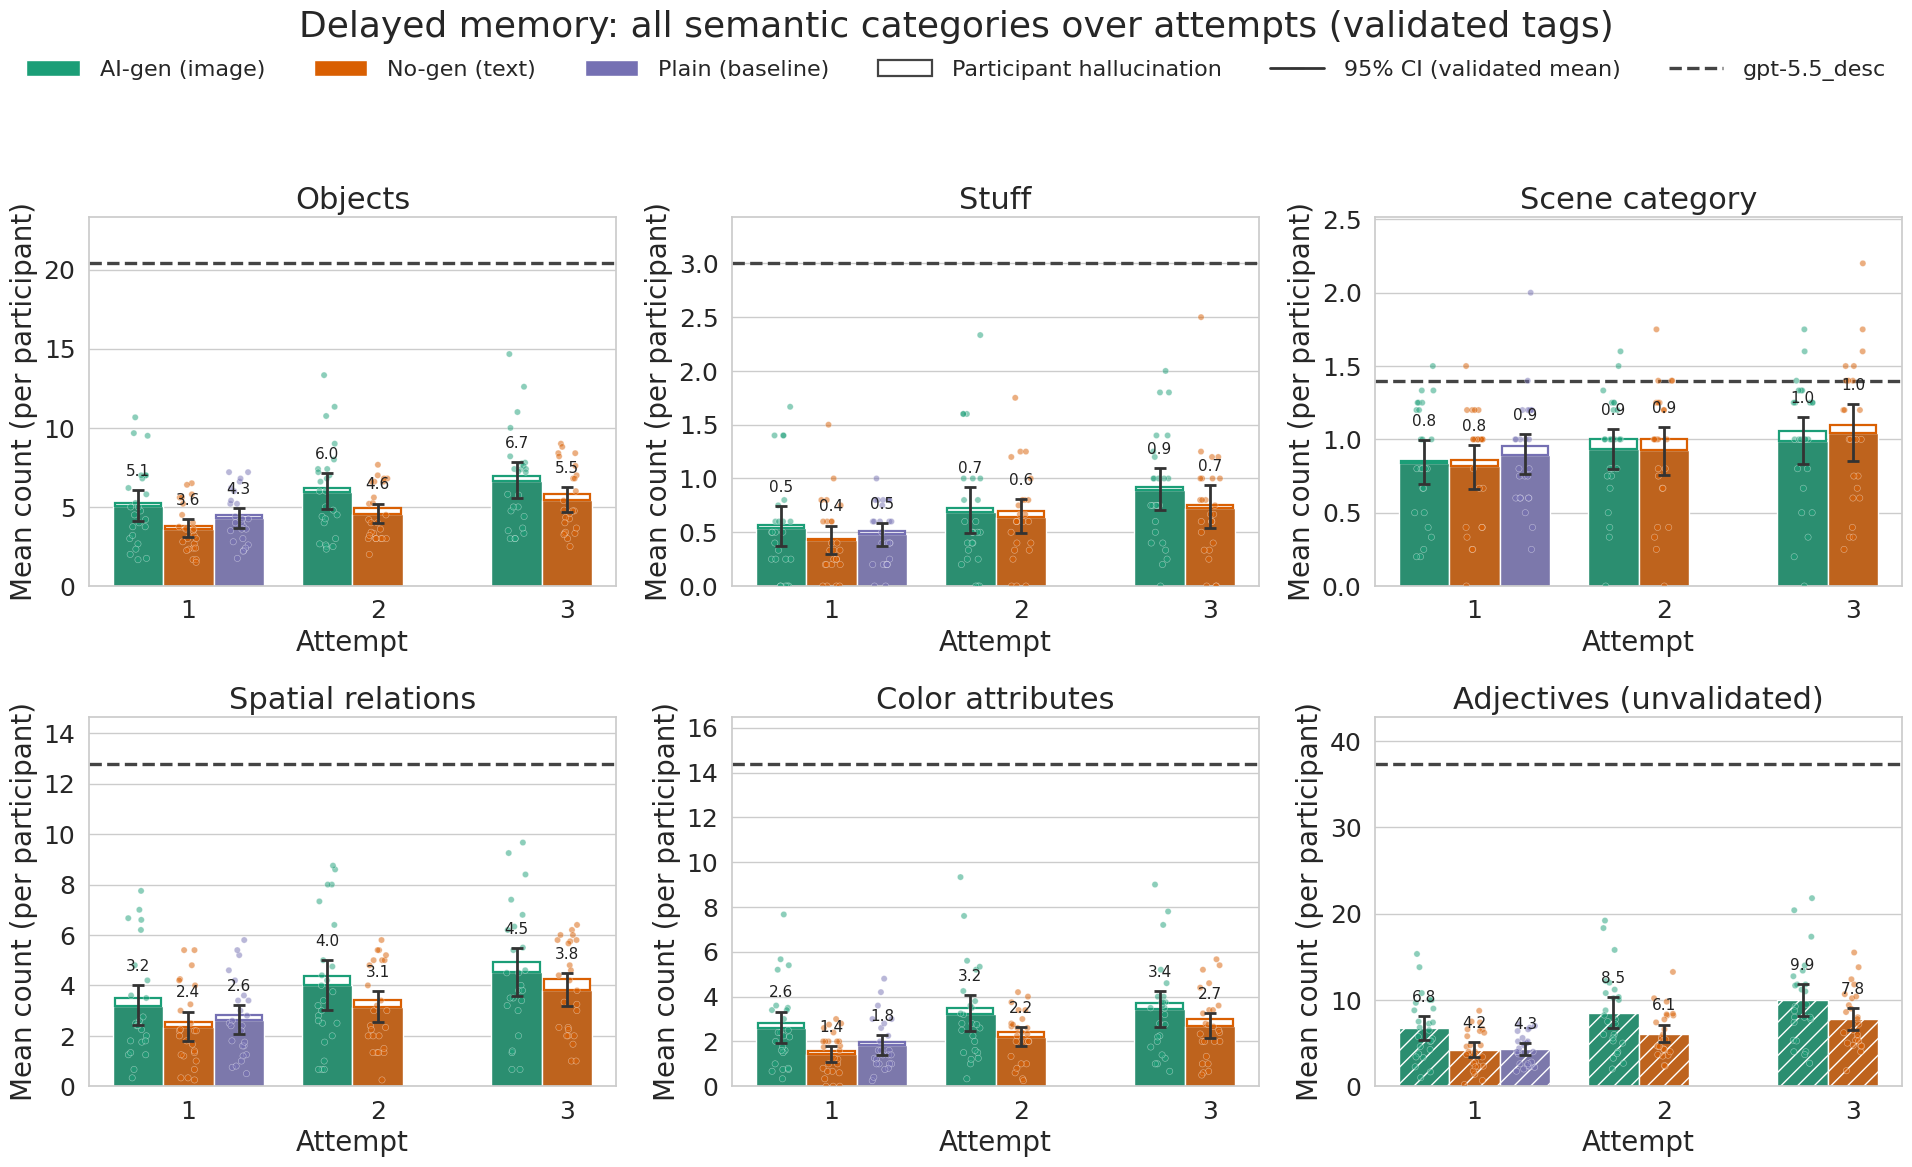

In [69]:
Q4 = {"aigen": None, "nogen": None, "plain": None}
for task in TASK_ORDER:
    plot_all_categories_grid(
        task, Q4,
        fname=f"q4_all_gens_{COUNT_MODE}_all_categories_{task}.png")

---
# 5. aigen vs drawings — all three attempts against the one drawing
Wilma's 2019 drawings, described by GPT **with the category hint** and validated by the same
judge, against the AI-gen descriptions. A drawing is a single production with no feedback loop,
so it is **one bar**, placed to the right of AI-gen's three attempts on the same axis: the
question is where in the loop (if anywhere) a written description catches up with what a drawn
one conveys.

x = attempt slot (AI-gen 1, 2, 3, then the drawing), one panel per task, one figure per category.
The drawing bar repeats nothing — it is the same set of drawings read against each attempt.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q5_aigen_attempts_vs_drawings_validated_objects.png


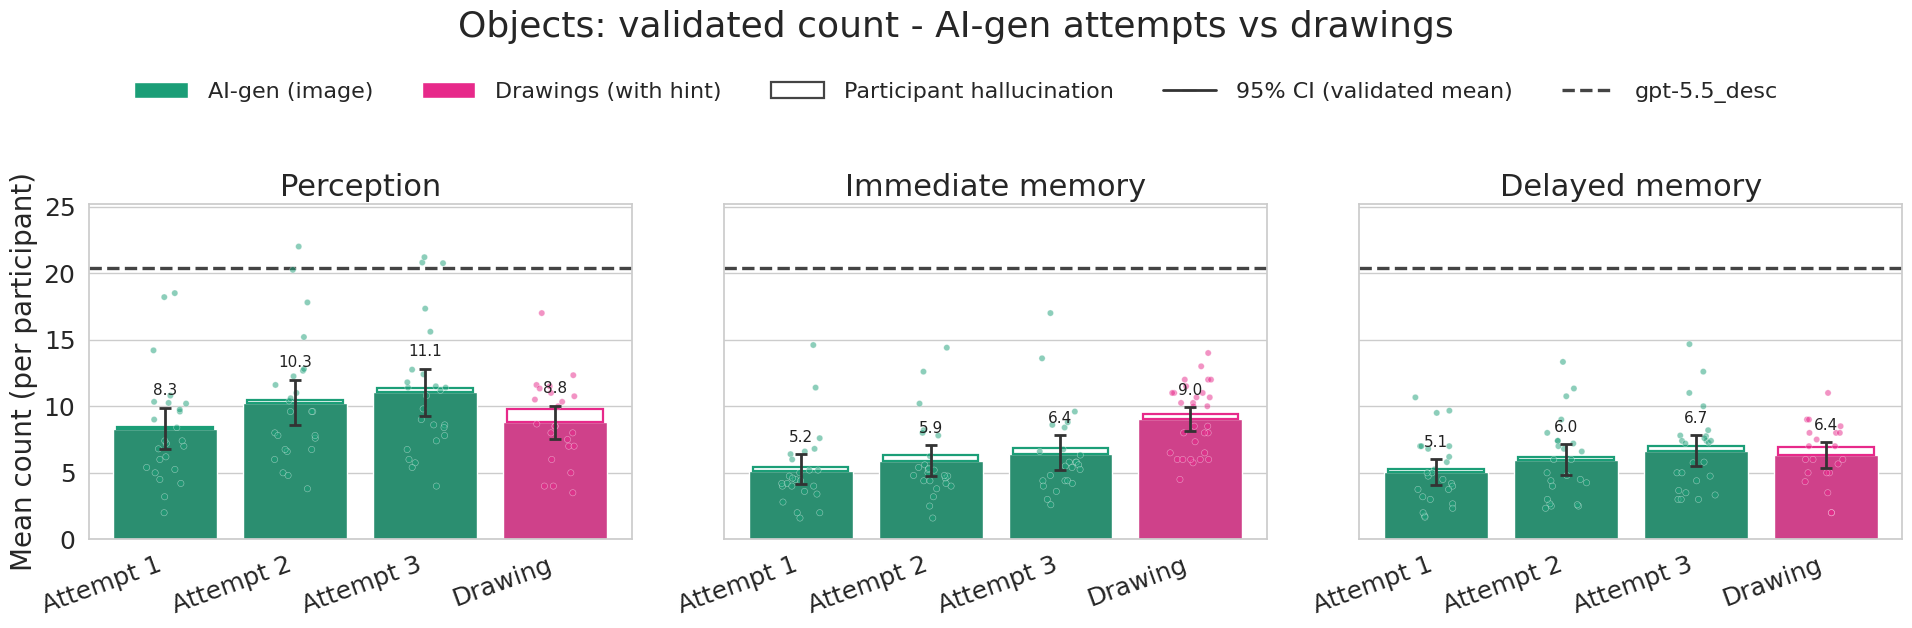

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q5_aigen_attempts_vs_drawings_validated_stuff.png


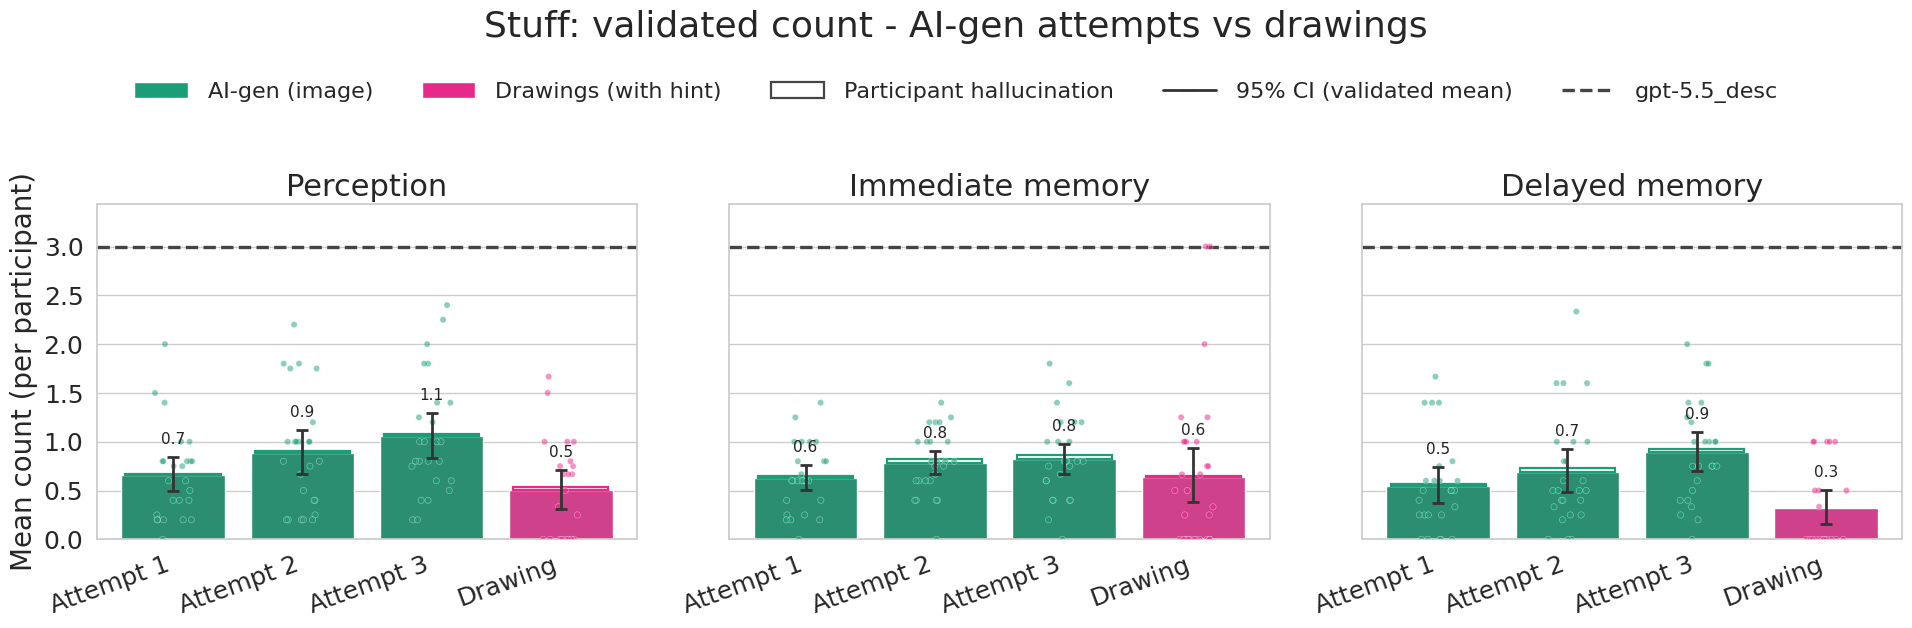

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q5_aigen_attempts_vs_drawings_validated_scene_category.png


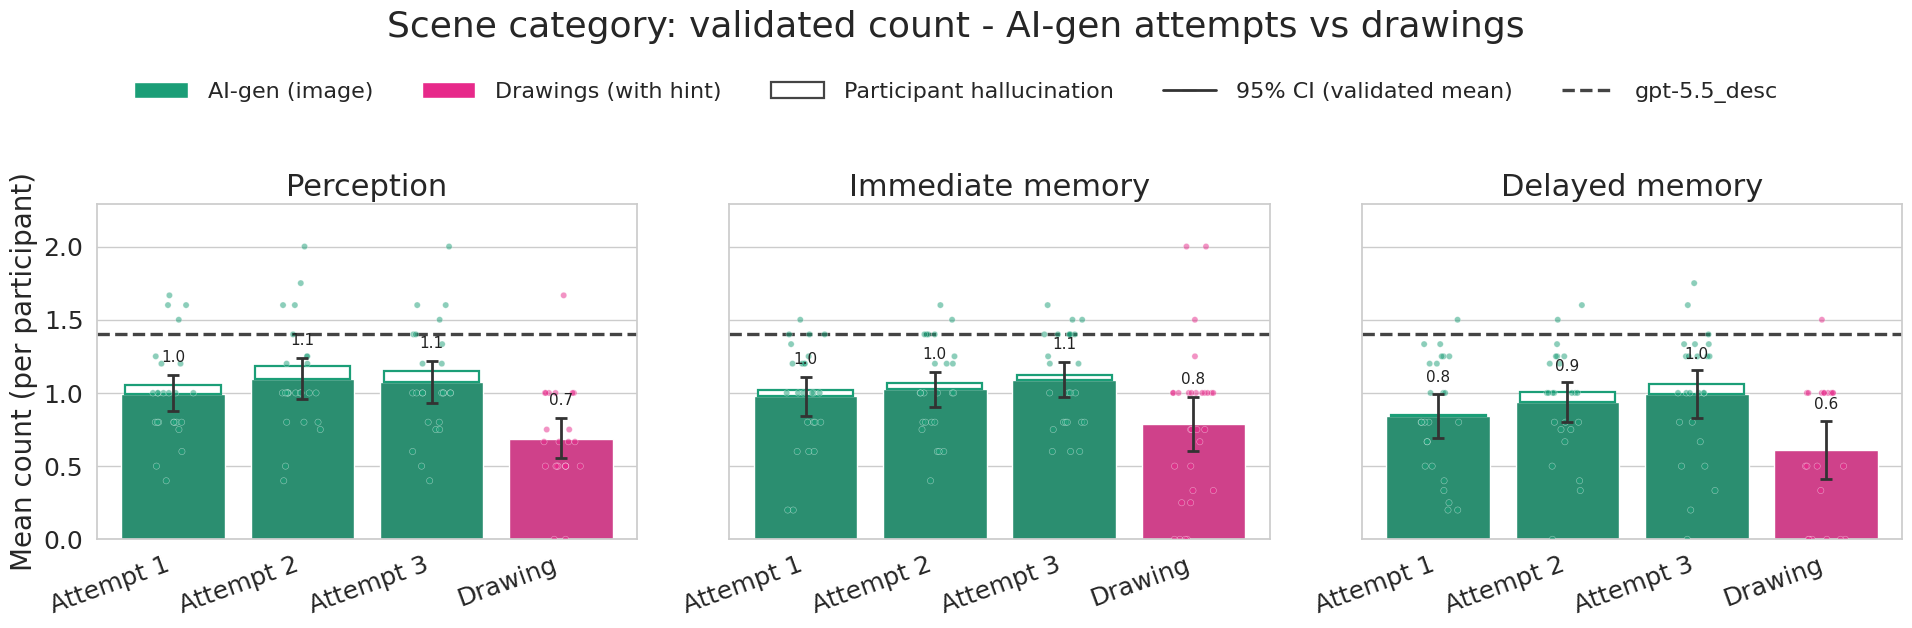

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q5_aigen_attempts_vs_drawings_validated_spatial_relations.png


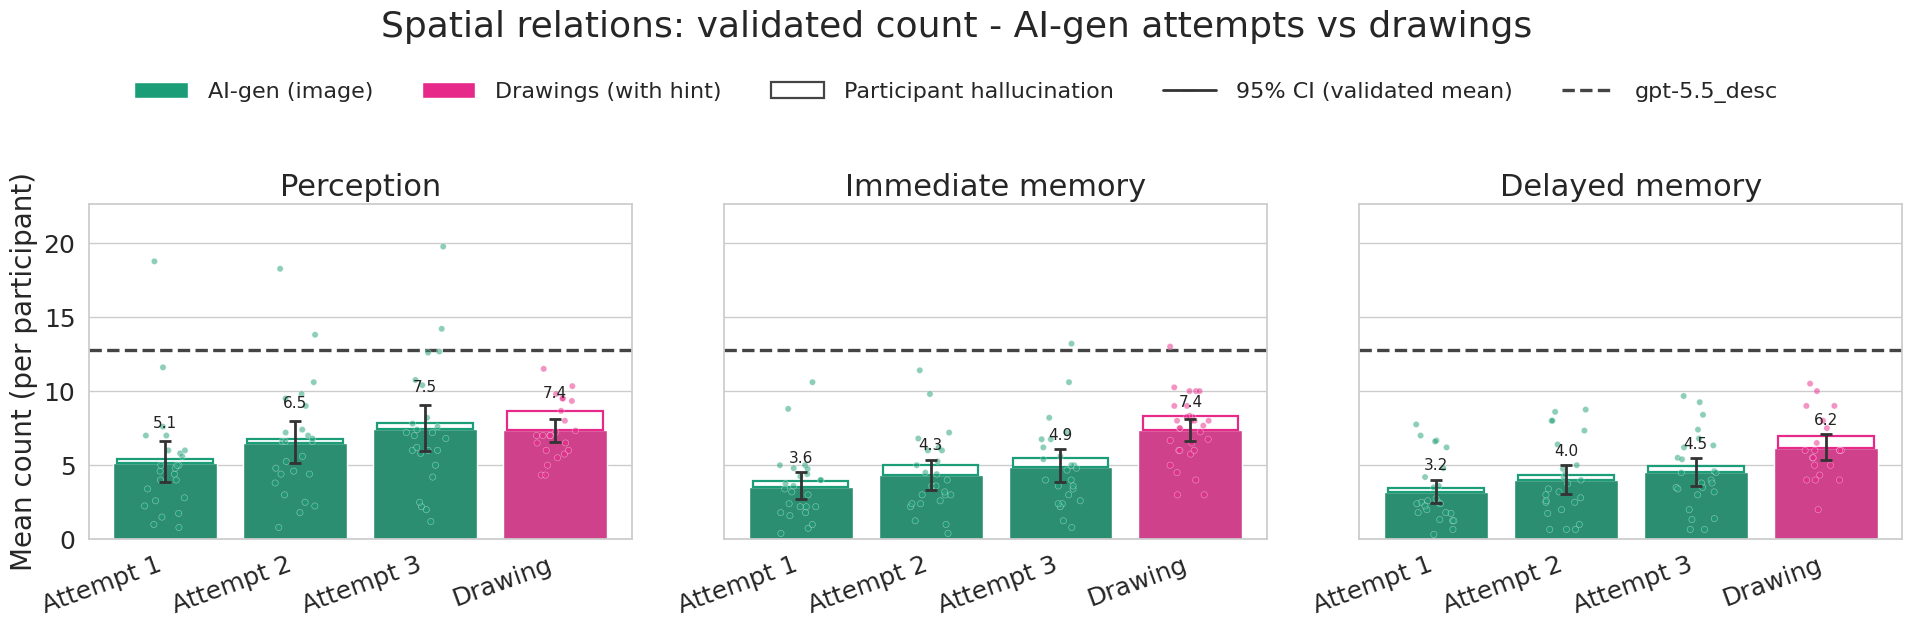

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q5_aigen_attempts_vs_drawings_validated_attr_color.png


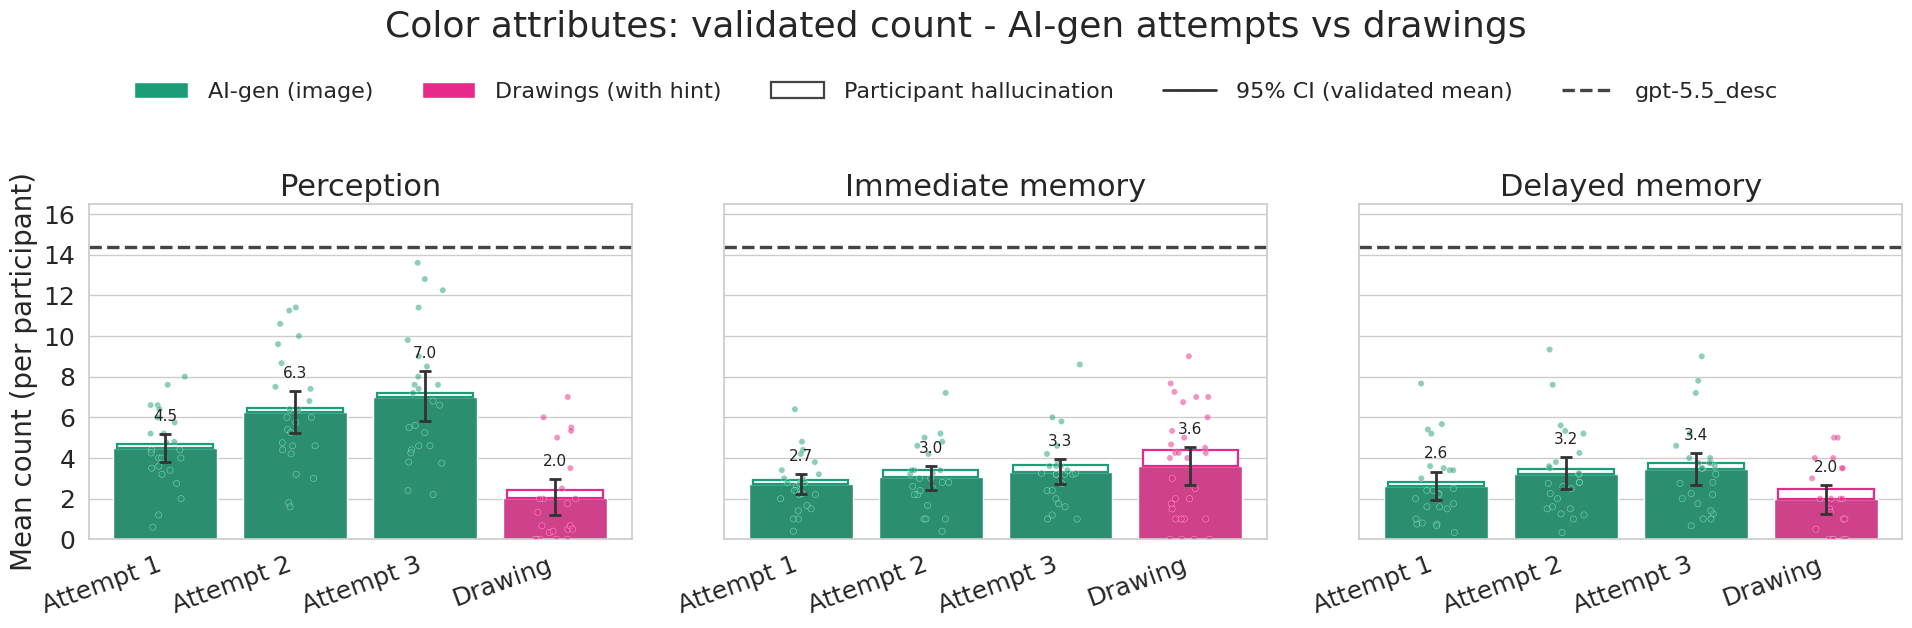

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q5_aigen_attempts_vs_drawings_validated_adjectives.png


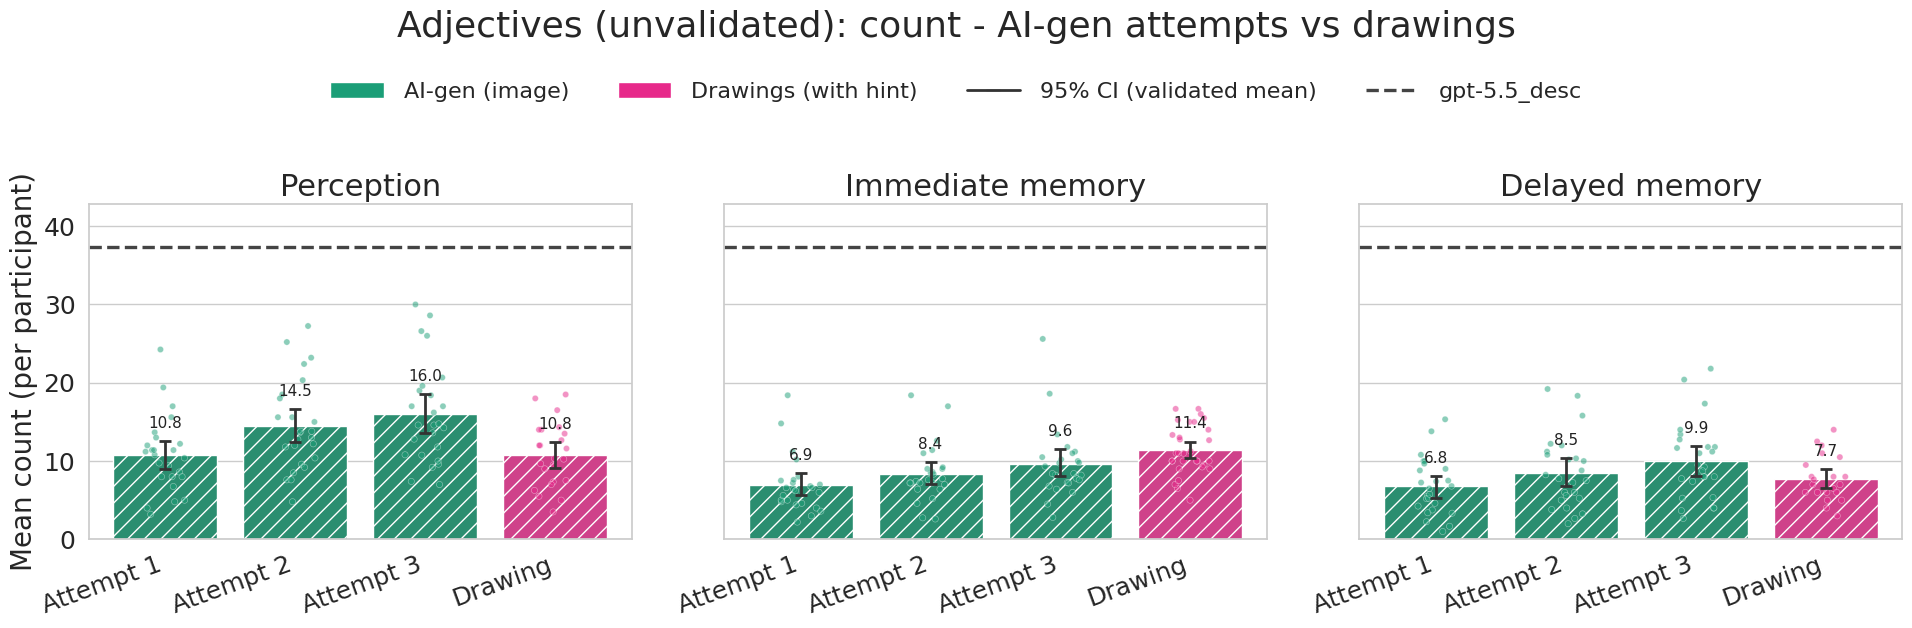

In [70]:
# --- Section 5 layout: attempts and the drawing share ONE x axis -------------
DRAW_SLOT = "Drawing"
SLOTS = [f"Attempt {a}" for a in ATTEMPTS] + [DRAW_SLOT]
# Hue is the x variable here (one bar per slot), so the palette is keyed by slot: AI-gen's
# green for the three attempts, the drawings' pink for the single drawing bar.
SLOT_COLORS = {**{f"Attempt {a}": GEN_COLORS["aigen"] for a in ATTEMPTS},
               DRAW_SLOT: GEN_COLORS["drawing"]}


def _slot_frame():
    """aigen (all attempts) + the drawings, with a `slot` column that mixes them on one axis."""
    data, gens = sel({"aigen": None, "drawing": 1})
    data = data.copy()
    data["slot"] = np.where(data["generation"] == "drawing", DRAW_SLOT,
                            "Attempt " + data["attempt"].astype(str))
    return data, gens


def plot_drawings_vs_attempts(category, save=True):
    """One panel per task; x = AI-gen attempt 1/2/3 then the drawing, colored by source."""
    data, gens = _slot_frame()
    g = _ppt_means(data, ["slot", "task", "uid"], category)
    label = cat_label(category)

    fig, axes = plt.subplots(1, len(TASK_ORDER), figsize=(6.5 * len(TASK_ORDER), 6.5), sharey=True)
    axes = np.atleast_1d(axes)
    vmax = 0
    for i, (ax, task) in enumerate(zip(axes, TASK_ORDER)):
        sub = g[g["task"] == task]
        if not sub.empty:
            vmax = max(vmax, _draw_bars(ax, sub, "slot", SLOTS, SLOTS, category,
                                        hue_col="slot", palette=SLOT_COLORS,
                                        color_of=lambda xv, s: SLOT_COLORS[s]))
        _add_gpt_desc(ax, category)
        ax.set_title(TASK_LABELS[task])
        ax.set_xlabel("")
        ax.set_xticks(range(len(SLOTS)))
        ax.set_xticklabels(SLOTS, rotation=20, ha="right")
        ax.set_ylabel("Mean count (per participant)" if i == 0 else "")
    for ax in axes:
        _style_count_axis(ax, vmax=vmax)
    kind = "validated " if is_validated(category) else ""
    fig.suptitle(f"{label}: {kind}count - AI-gen attempts vs drawings")
    _figure_legend(fig, ["aigen", "drawing"], marker="bar", caps=is_validated(category), ci=True)
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    if save:
        _save(fig, GRAPHS / f"q5_aigen_attempts_vs_drawings_{COUNT_MODE}_{category}.png")
    plt.show()


for category in CATEGORIES:
    plot_drawings_vs_attempts(category)

## 5b. aigen vs drawings — every category in one figure
The same comparison as a compact per-task overview: one panel per category, each holding the
three AI-gen attempts and the drawing bar. Per-panel y scale, so read every panel against its
own dashed `gpt-5.5_desc` line rather than against its neighbours.

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q5b_aigen_attempts_vs_drawings_validated_all_categories_perception.png


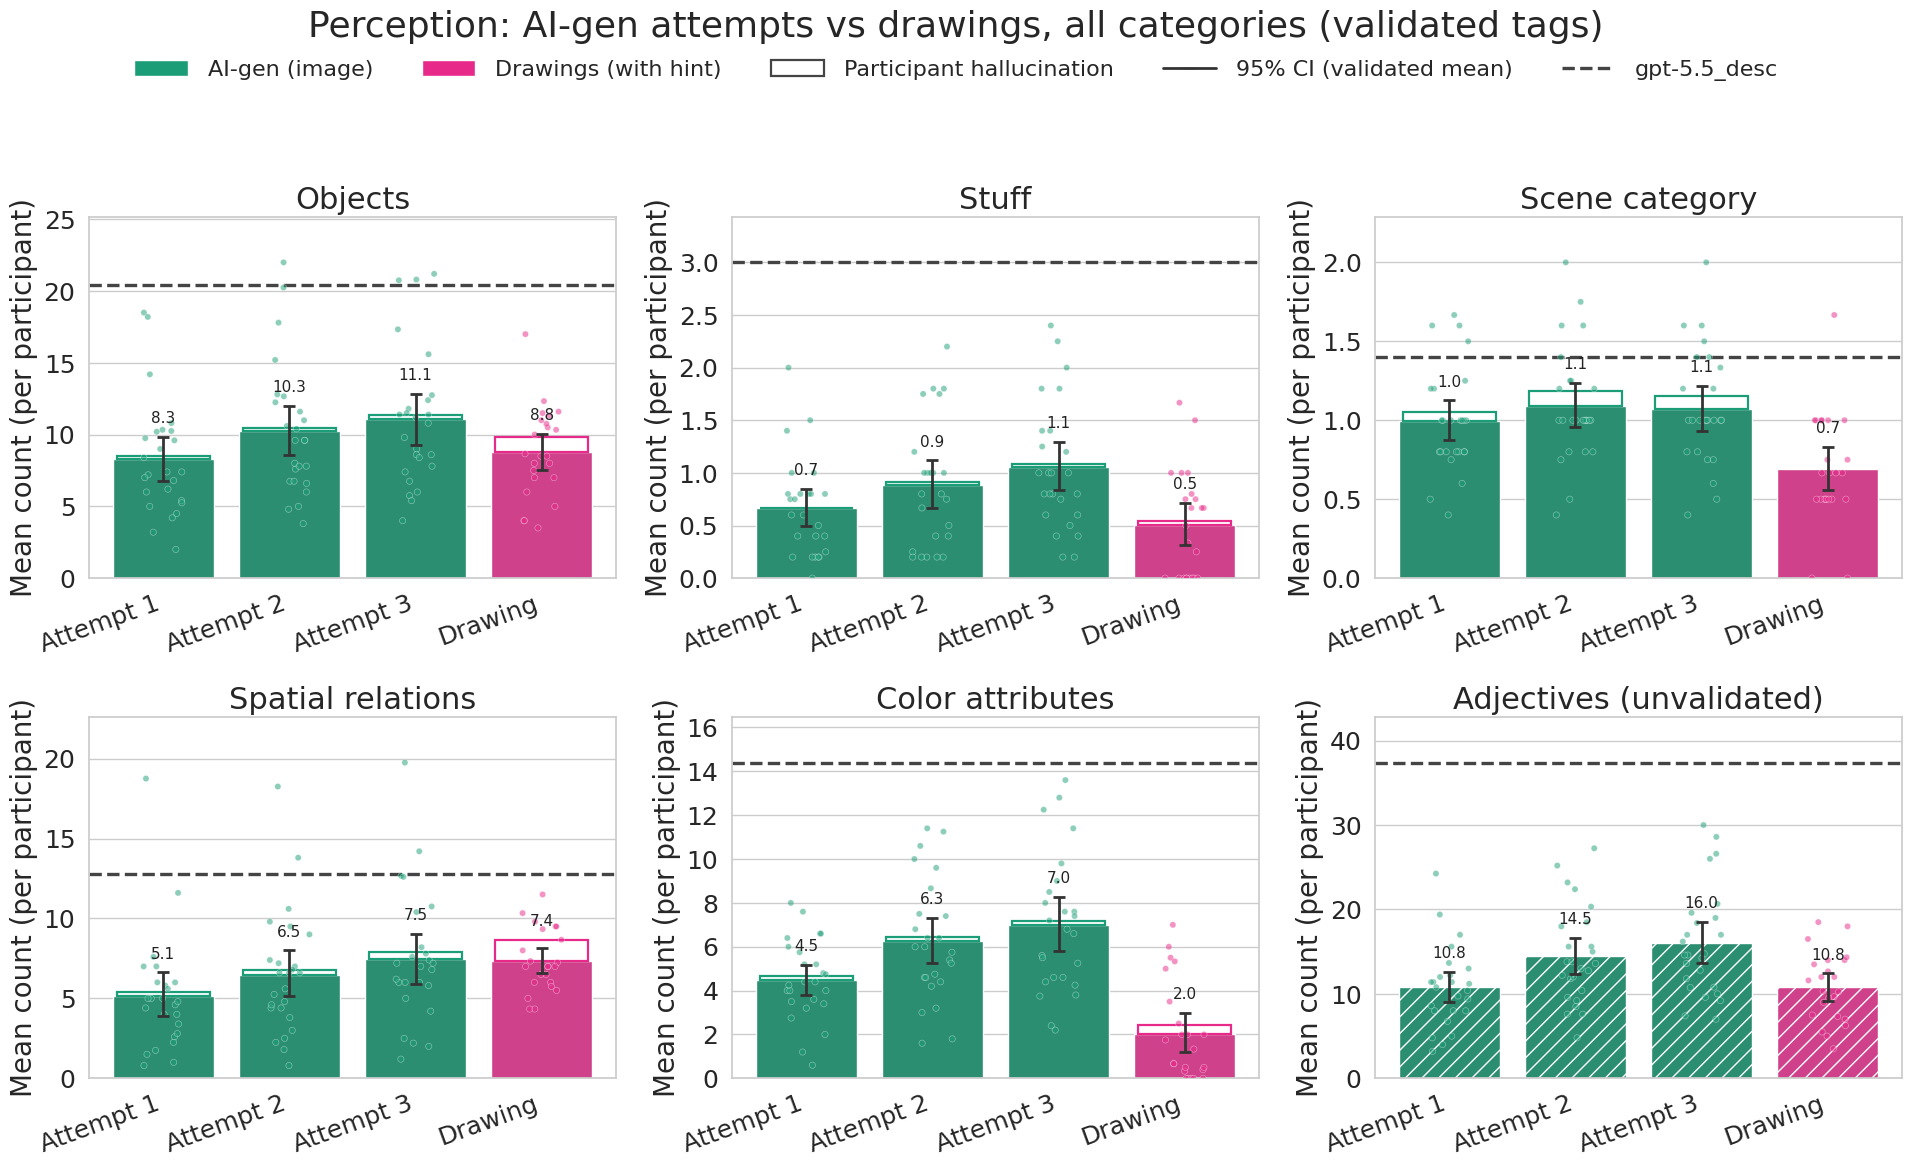

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q5b_aigen_attempts_vs_drawings_validated_all_categories_immediate.png


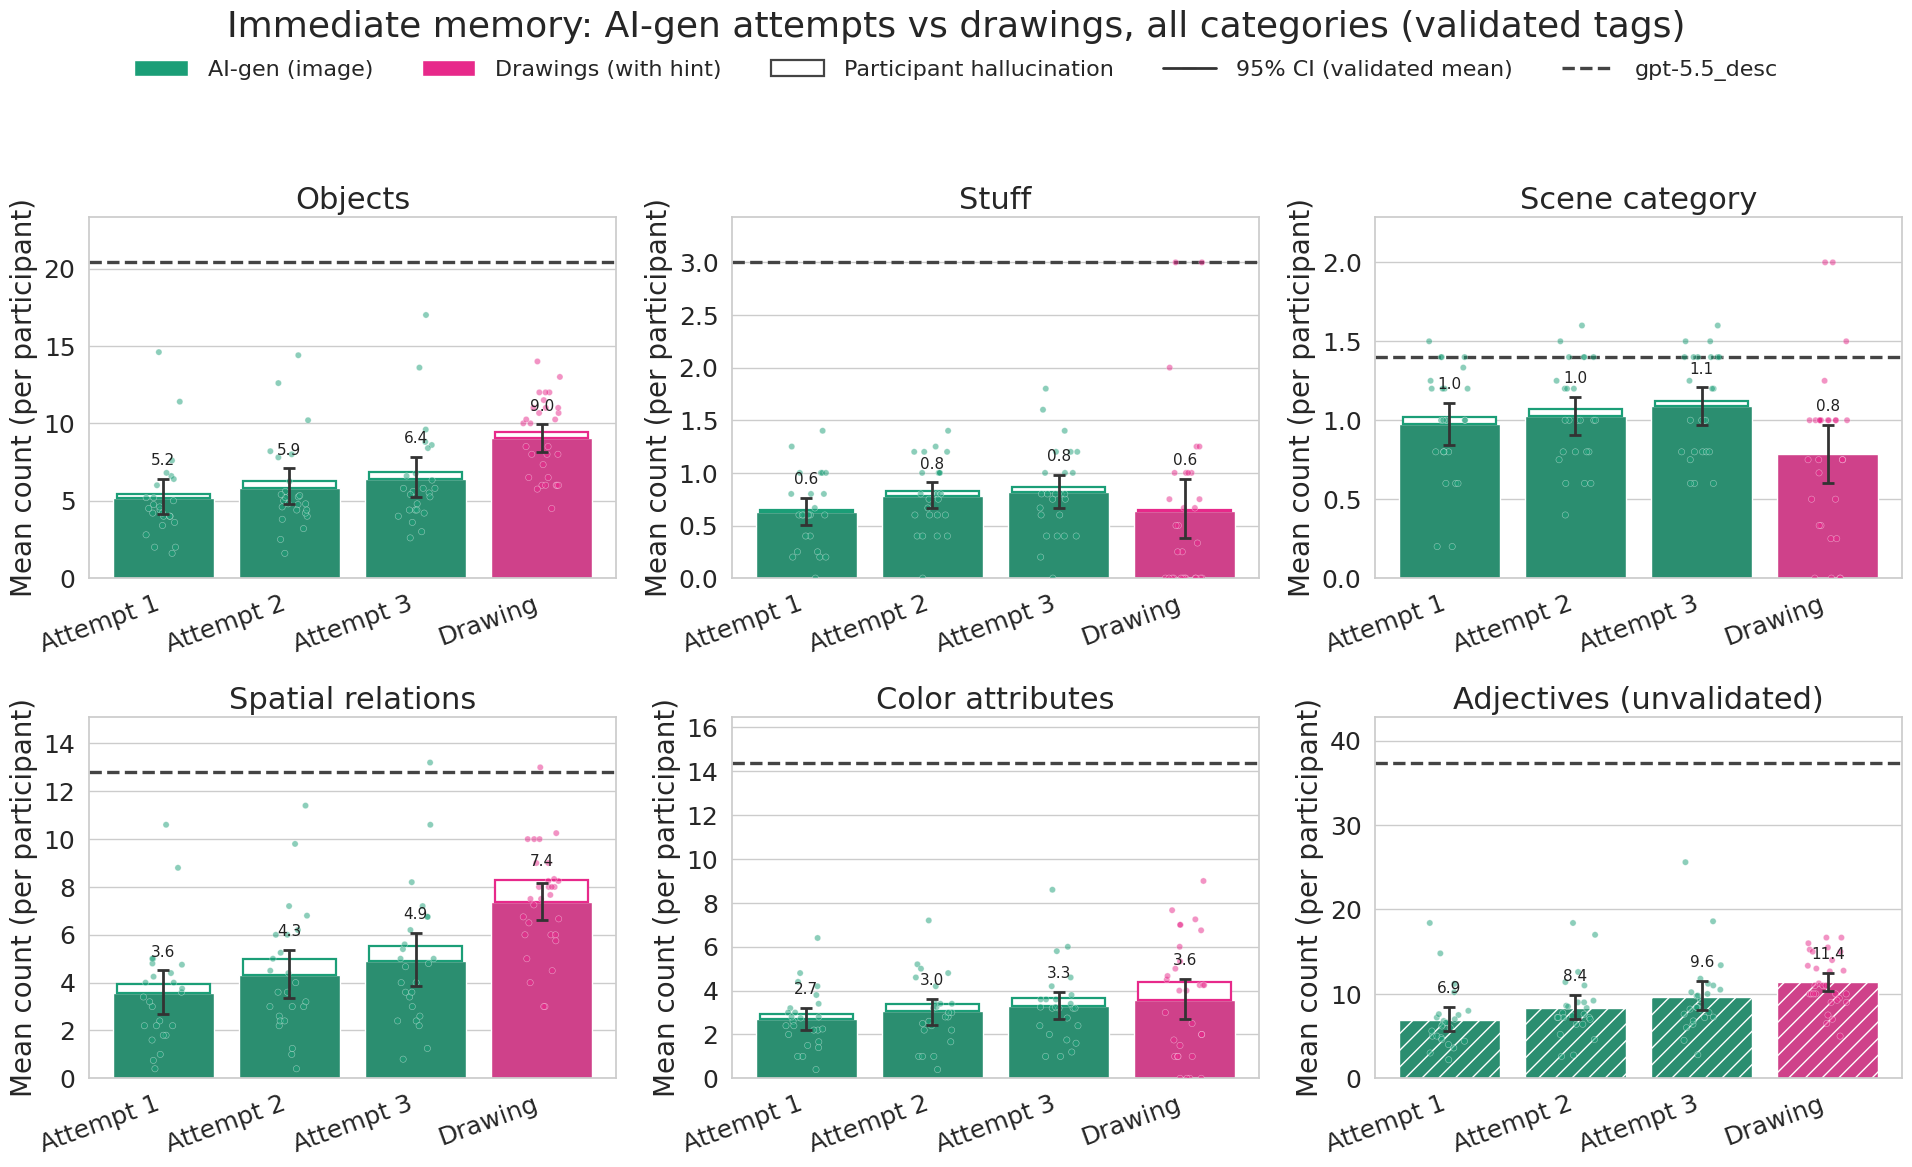

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q5b_aigen_attempts_vs_drawings_validated_all_categories_delay.png


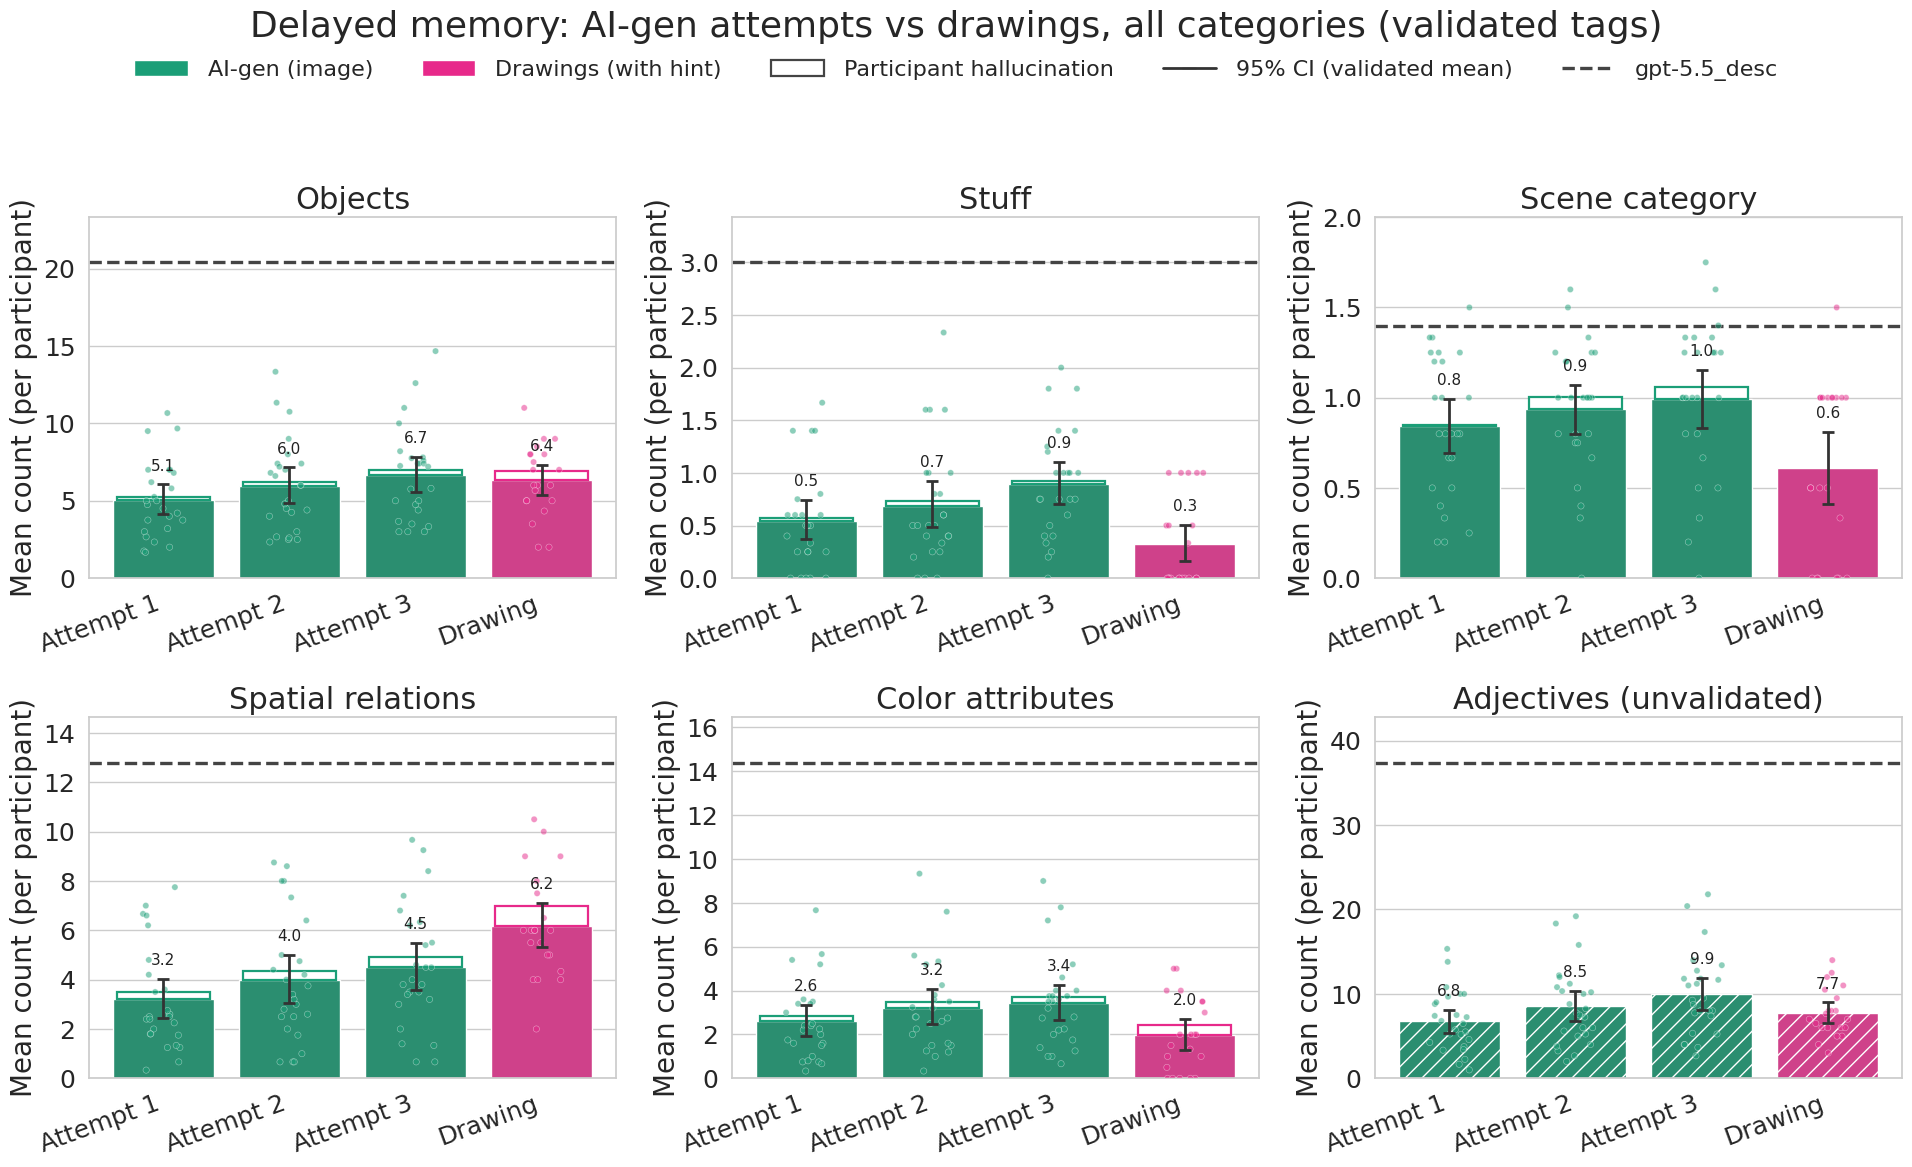

In [71]:
def plot_drawings_vs_attempts_grid(task, save=True):
    """VIEW 5b: all six categories for one task, x = AI-gen attempt 1/2/3 then the drawing."""
    data, gens = _slot_frame()
    data = data[data["task"] == task]
    if data.empty:
        print(f"{task}: no rows - skipping")
        return
    cats = list(CATEGORIES)
    nrow = int(np.ceil(len(cats) / PANEL_COLS))
    fig, axes = plt.subplots(nrow, PANEL_COLS, figsize=(6.5 * PANEL_COLS, 6.0 * nrow))
    axes = np.atleast_1d(axes).ravel()

    for ax, category in zip(axes, cats):
        g = _ppt_means(data, ["slot", "uid"], category)
        vmax = _draw_bars(ax, g, "slot", SLOTS, SLOTS, category, hue_col="slot",
                          palette=SLOT_COLORS, color_of=lambda xv, s: SLOT_COLORS[s])
        _add_gpt_desc(ax, category)
        ax.set_title(cat_label(category))
        ax.set_xlabel("")
        ax.set_xticks(range(len(SLOTS)))
        ax.set_xticklabels(SLOTS, rotation=20, ha="right")
        ax.set_ylabel("Mean count (per participant)")
        _style_count_axis(ax, vmax=vmax)
    for ax in axes[len(cats):]:
        ax.set_visible(False)

    kind = "validated tags" if COUNT_MODE == "validated" else "raw tags"
    fig.suptitle(f"{TASK_LABELS[task]}: AI-gen attempts vs drawings, all categories ({kind})")
    _figure_legend(fig, ["aigen", "drawing"], marker="bar", y=0.955, caps=True, ci=True)
    fig.tight_layout(rect=(0, 0, 1, 0.91))
    if save:
        _save(fig, GRAPHS / f"q5b_aigen_attempts_vs_drawings_{COUNT_MODE}_all_categories_{task}.png")
    plt.show()


for task in TASK_ORDER:
    plot_drawings_vs_attempts_grid(task)

---
# 6. aigen — the same view as §1, with the bar split four ways

Identical layout to view 1: one figure per category, one panel per task, x = attempt,
participant-averaged. The only difference is what the bar contains.

View 1 draws `n_<cat>` solid with a hollow `h_<cat>` cap — valid tags and participant
hallucinations, the two that say something about the participant. This view adds the two
that do not, so the bar is the whole of `n_extracted_<cat>`:

| segment | whose error |
|---|---|
| **valid** | nobody's — visible, right category, actually said |
| **participant hallucination** | the participant's |
| **category misplacement** | the extractor's |
| **model hallucination** | the extractor's |

The bottom two segments are exactly view 1's bar and cap, so the two figures line up and
the extra height is the correction the other views remove.


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q6_aigen_tag_budget_objects_over_attempts.png


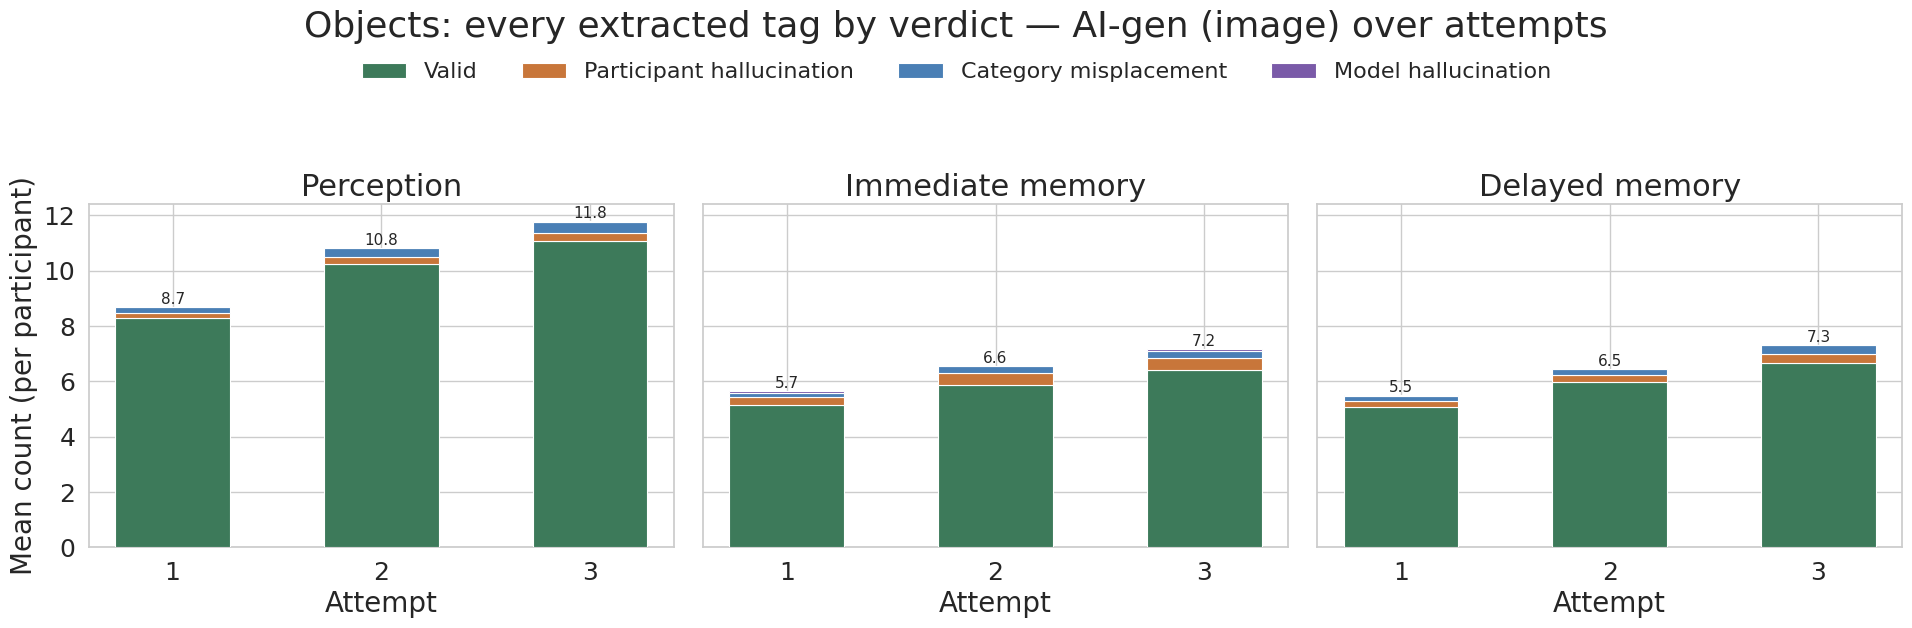


Objects — mean tags per trial (aigen)


Valid  Participant hallucination  Category misplacement  \
task       attempt                                                            
perception 1         8.27                       0.21                   0.20   
           2        10.25                       0.23                   0.32   
           3        11.06                       0.31                   0.39   
immediate  1         5.15                       0.29                   0.14   
           2         5.85                       0.45                   0.24   
           3         6.41                       0.44                   0.25   
delay      1         5.06                       0.21                   0.19   
           2         5.97                       0.24                   0.24   
           3         6.66                       0.33                   0.32   

                    Model hallucination   _all  
task       attempt                              
perception 1                       0.00   8.68  
           2                       0.03  10.83  
           3                       0.05  11.81  
immediate  1                       0.07   5.65  
           2                       0.02   6.56  
           3                       0.07   7.17  
delay      1                       0.03   5.50  
           2                       0.01   6.46  
           3                       0.01   7.31

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q6_aigen_tag_budget_stuff_over_attempts.png


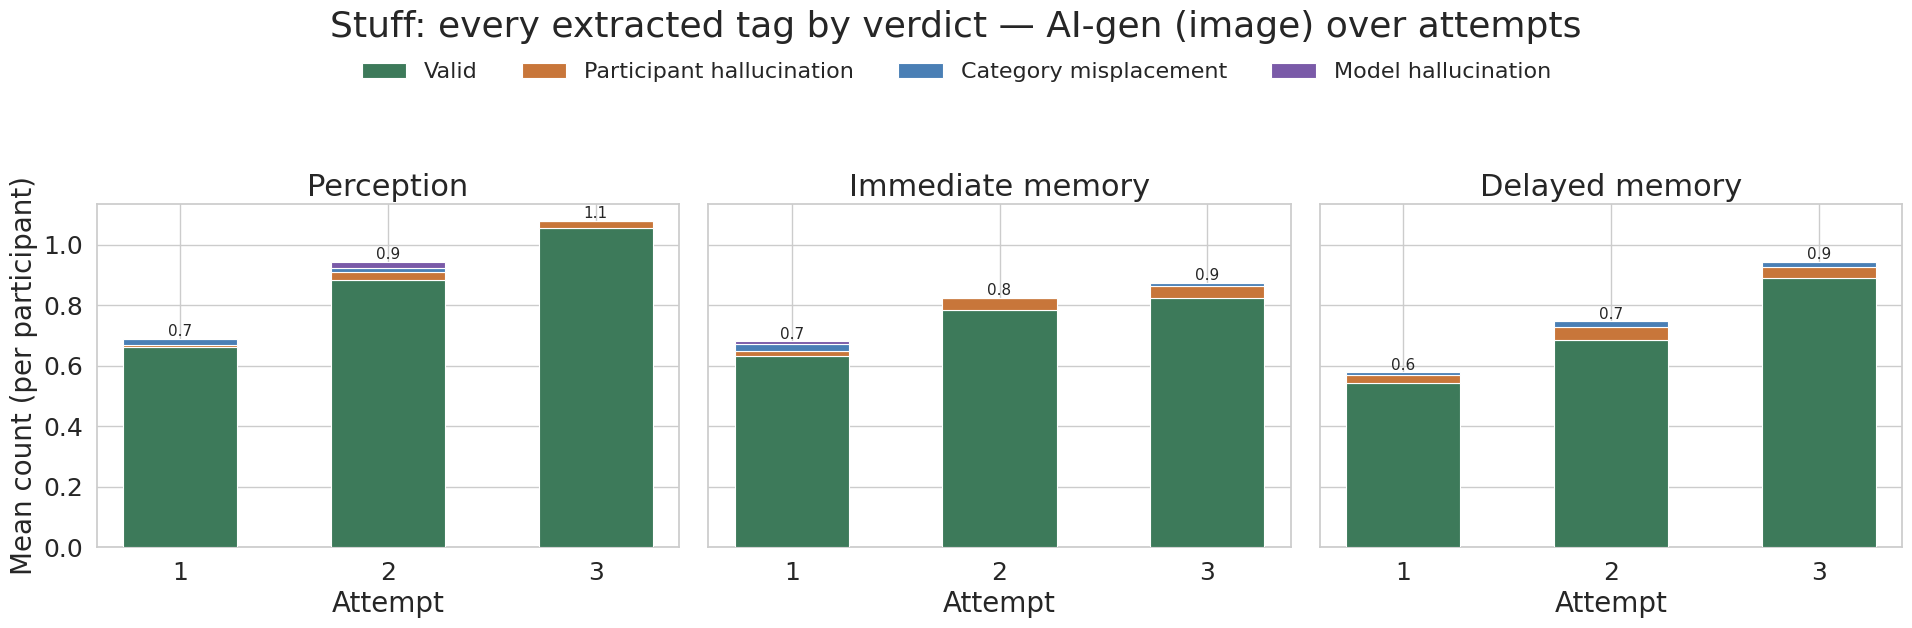


Stuff — mean tags per trial (aigen)


Valid  Participant hallucination  Category misplacement  \
task       attempt                                                            
perception 1         0.66                       0.01                   0.02   
           2         0.88                       0.03                   0.02   
           3         1.05                       0.03                   0.00   
immediate  1         0.63                       0.02                   0.02   
           2         0.78                       0.04                   0.00   
           3         0.82                       0.04                   0.01   
delay      1         0.54                       0.03                   0.01   
           2         0.69                       0.04                   0.02   
           3         0.89                       0.03                   0.02   

                    Model hallucination  _all  
task       attempt                             
perception 1                       0.00  0.69  
           2                       0.02  0.94  
           3                       0.00  1.08  
immediate  1                       0.01  0.68  
           2                       0.00  0.82  
           3                       0.00  0.87  
delay      1                       0.00  0.58  
           2                       0.00  0.75  
           3                       0.00  0.94

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q6_aigen_tag_budget_scene_category_over_attempts.png


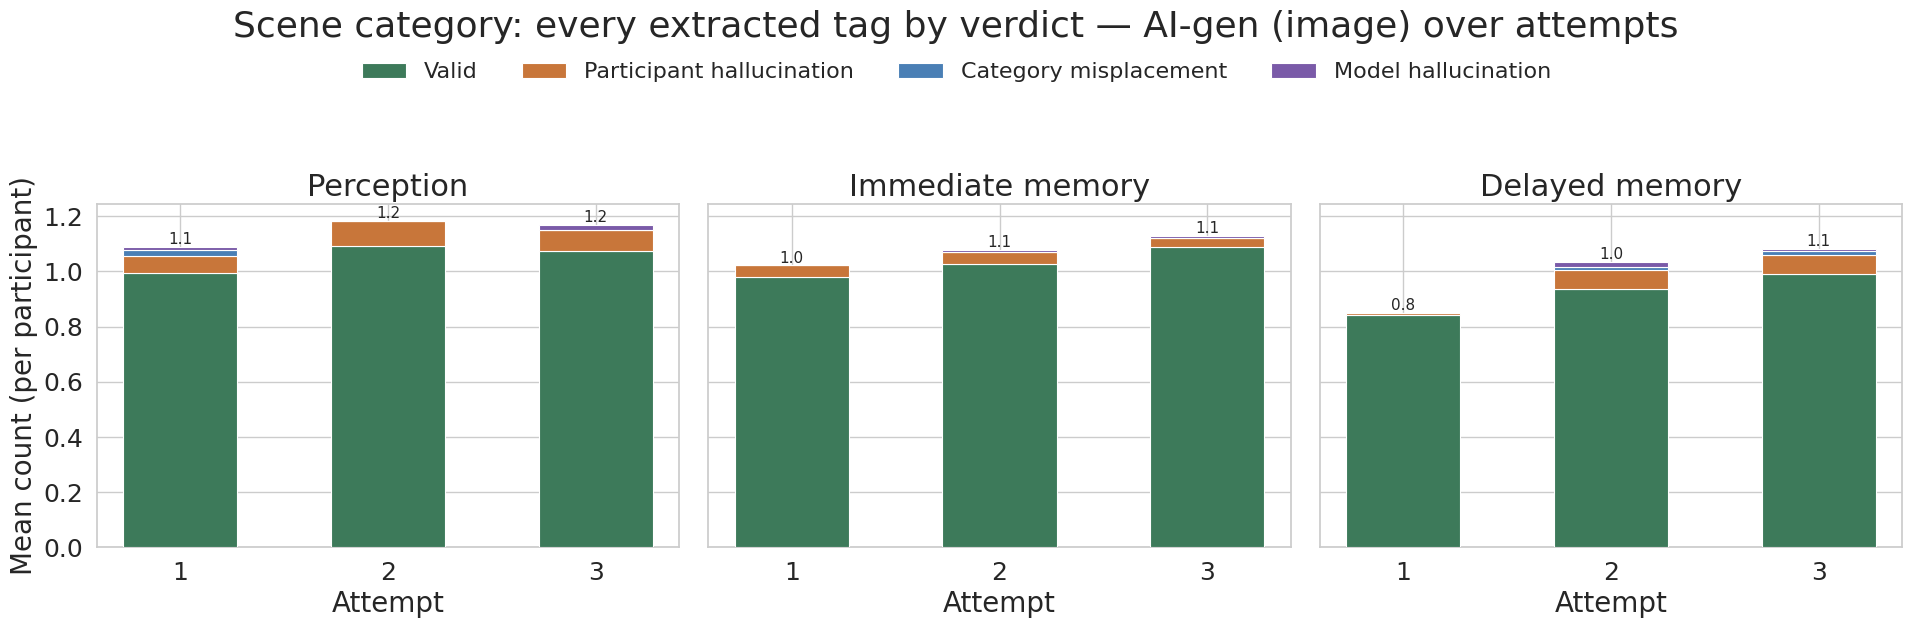


Scene category — mean tags per trial (aigen)


Valid  Participant hallucination  Category misplacement  \
task       attempt                                                            
perception 1         0.99                       0.06                   0.02   
           2         1.09                       0.09                   0.00   
           3         1.07                       0.08                   0.00   
immediate  1         0.98                       0.04                   0.00   
           2         1.03                       0.04                   0.00   
           3         1.09                       0.03                   0.00   
delay      1         0.84                       0.01                   0.00   
           2         0.94                       0.07                   0.01   
           3         0.99                       0.07                   0.02   

                    Model hallucination  _all  
task       attempt                             
perception 1                       0.01  1.09  
           2                       0.00  1.18  
           3                       0.02  1.17  
immediate  1                       0.00  1.02  
           2                       0.01  1.08  
           3                       0.01  1.13  
delay      1                       0.00  0.85  
           2                       0.02  1.03  
           3                       0.01  1.08

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q6_aigen_tag_budget_spatial_relations_over_attempts.png


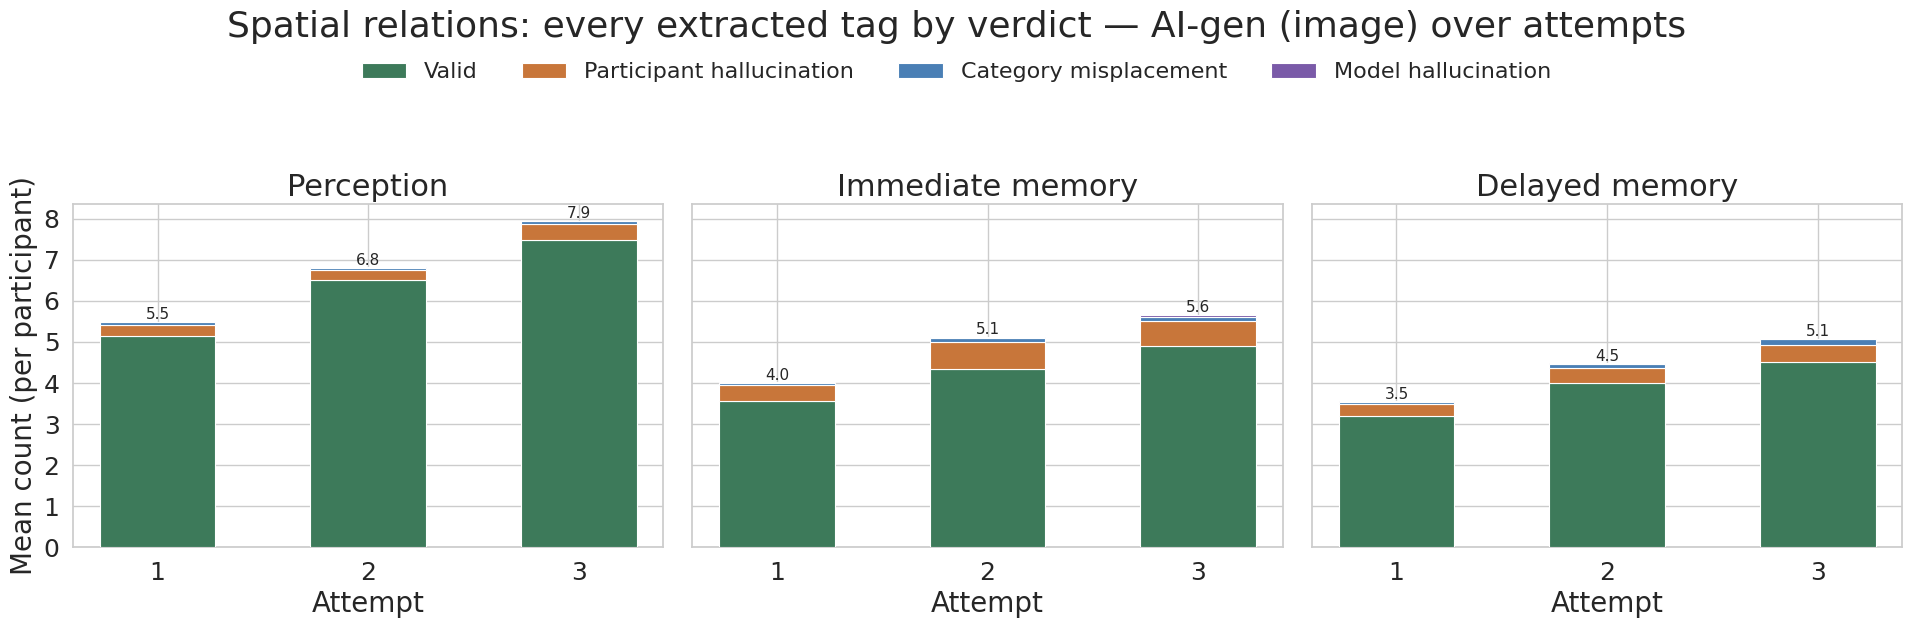


Spatial relations — mean tags per trial (aigen)


Valid  Participant hallucination  Category misplacement  \
task       attempt                                                            
perception 1         5.13                       0.29                   0.07   
           2         6.49                       0.25                   0.06   
           3         7.47                       0.41                   0.07   
immediate  1         3.56                       0.40                   0.05   
           2         4.33                       0.68                   0.08   
           3         4.90                       0.61                   0.09   
delay      1         3.20                       0.30                   0.04   
           2         4.00                       0.36                   0.09   
           3         4.51                       0.41                   0.16   

                    Model hallucination  _all  
task       attempt                             
perception 1                       0.01  5.49  
           2                       0.01  6.81  
           3                       0.01  7.95  
immediate  1                       0.01  4.01  
           2                       0.02  5.11  
           3                       0.04  5.65  
delay      1                       0.02  3.55  
           2                       0.02  4.47  
           3                       0.00  5.08

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q6_aigen_tag_budget_attr_color_over_attempts.png


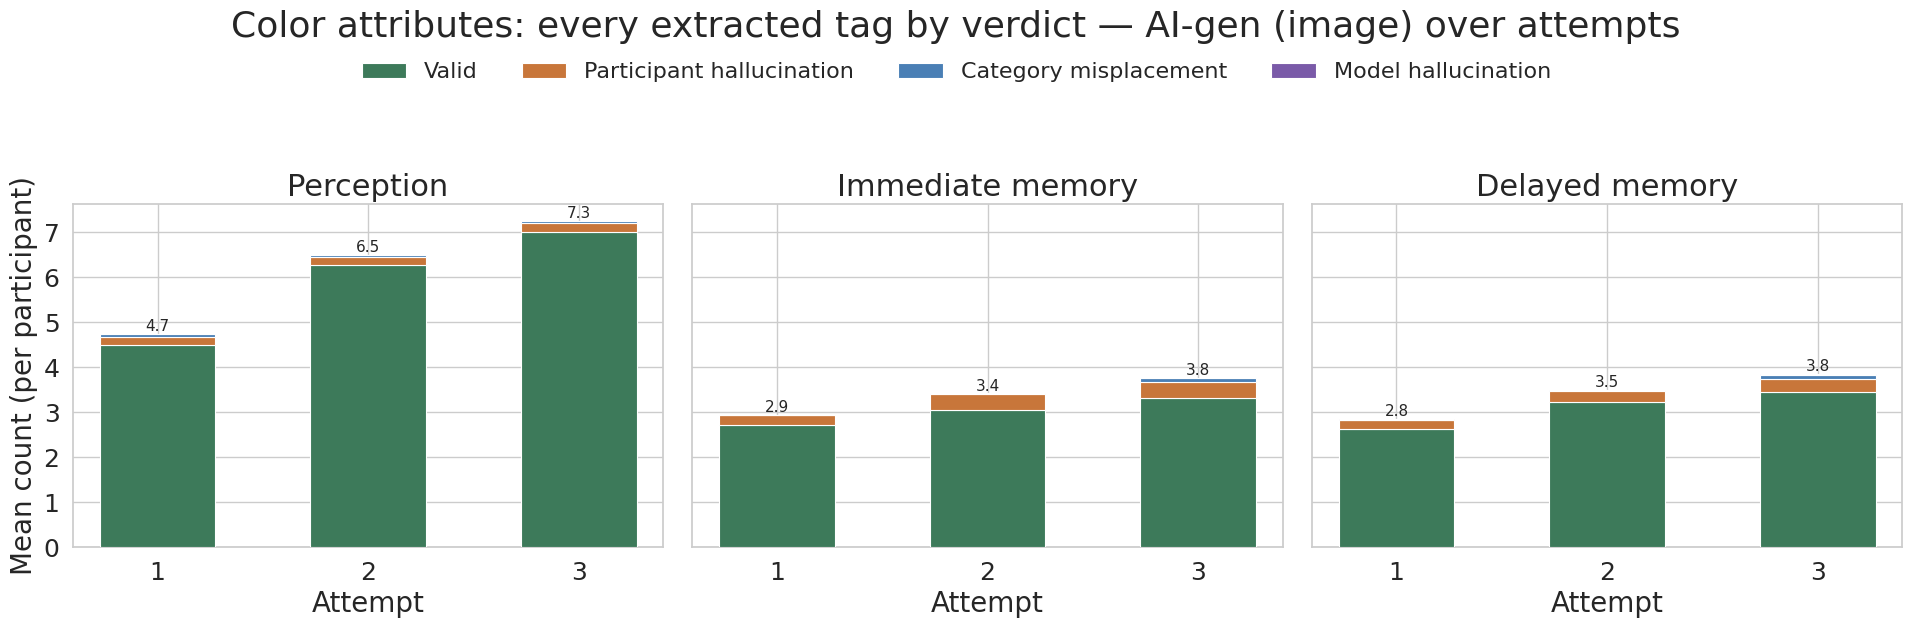


Color attributes — mean tags per trial (aigen)


Valid  Participant hallucination  Category misplacement  \
task       attempt                                                            
perception 1         4.49                       0.19                   0.06   
           2         6.26                       0.18                   0.03   
           3         7.00                       0.19                   0.06   
immediate  1         2.70                       0.23                   0.01   
           2         3.05                       0.34                   0.02   
           3         3.30                       0.37                   0.08   
delay      1         2.61                       0.21                   0.01   
           2         3.23                       0.25                   0.01   
           3         3.44                       0.29                   0.09   

                    Model hallucination  _all  
task       attempt                             
perception 1                       0.00  4.74  
           2                       0.01  6.48  
           3                       0.00  7.25  
immediate  1                       0.00  2.94  
           2                       0.00  3.41  
           3                       0.01  3.76  
delay      1                       0.01  2.84  
           2                       0.01  3.49  
           3                       0.03  3.85

In [72]:
# Same geometry as plot_category_over_attempts, stacked four ways instead of bar+cap.
BUDGET_SEG = [
    ("n_valid_{c}",                     "Valid",                     "#3d7a5a"),
    ("n_participant_hallucination_{c}", "Participant hallucination", "#c8763a"),
    ("n_category_misplacement_{c}",     "Category misplacement",     "#4a7fb5"),
    ("n_model_hallucination_{c}",       "Model hallucination",       "#7a5aa8"),
]


def budget_means(category, gen="aigen", data=None):
    """Participant-averaged mean per segment for one category: uid first, then across uids."""
    d = (df if data is None else data)
    d = d[d["generation"] == gen].copy()
    d = d[d["error"].isna()] if "error" in d.columns else d
    d["attempt"] = d["attempt"].astype(int)
    keys = []
    for tmpl, label, _ in BUDGET_SEG:
        col = tmpl.format(c=category)
        d[label] = pd.to_numeric(d[col], errors="coerce").fillna(0)
        keys.append(label)
    d["_all"] = pd.to_numeric(d[f"n_extracted_{category}"], errors="coerce").fillna(0)
    per_uid = d.groupby(["task", "attempt", "uid"])[keys + ["_all"]].mean().reset_index()
    out = per_uid.groupby(["task", "attempt"])[keys + ["_all"]].mean()
    assert (out[keys].sum(axis=1) - out["_all"]).abs().max() < 0.01, \
        f"{category}: segments must sum to n_extracted_{category}"
    return out


def plot_budget_over_attempts(category, gen="aigen", attempts=ATTEMPTS, save=True):
    m = budget_means(category, gen=gen)
    labels = [lab for _, lab, _ in BUDGET_SEG]
    fig, axes = plt.subplots(1, len(TASK_ORDER), figsize=(6.5 * len(TASK_ORDER), 6.5),
                             sharey=True)
    axes = np.atleast_1d(axes)
    vmax = 0
    for i, (ax, task) in enumerate(zip(axes, TASK_ORDER)):
        sub = m.loc[task].reindex(attempts)
        x = np.arange(len(sub))
        bottom = np.zeros(len(sub))
        for (_tmpl, label, colour) in BUDGET_SEG:
            vals = sub[label].fillna(0).to_numpy(dtype=float)
            ax.bar(x, vals, 0.55, bottom=bottom, label=label, color=colour,
                   edgecolor="white", linewidth=0.8, zorder=3)
            bottom += vals
        for xi, total in zip(x, bottom):
            if total > 0:
                ax.text(xi, total, f"{total:.1f}", ha="center", va="bottom",
                        fontsize=11, zorder=4)
        vmax = max(vmax, float(bottom.max()) if len(bottom) else 0)
        ax.set_xticks(x)
        ax.set_xticklabels([str(int(a)) for a in sub.index])
        ax.set_title(TASK_LABELS[task])
        ax.set_xlabel("Attempt")
        ax.set_ylabel("Mean count (per participant)" if i == 0 else "")
    for ax in axes:
        _style_count_axis(ax, vmax=vmax)
    fig.suptitle(f"{cat_label(category)}: every extracted tag by verdict "
                 f"— {GEN_LABELS.get(gen, gen)} over attempts")
    handles, lab = axes[0].get_legend_handles_labels()
    fig.legend(handles, lab, loc="upper center", ncol=4, frameon=False,
               bbox_to_anchor=(0.5, 0.93))
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    if save:
        _save(fig, GRAPHS / f"q6_{gen}_tag_budget_{category}_over_attempts.png")
    plt.show()
    return m


for category in VALIDATED_CATEGORIES:
    m = plot_budget_over_attempts(category)
    print(f"\n{cat_label(category)} — mean tags per trial (aigen)")
    display(m.reindex(TASK_ORDER, level=0).round(2))


---
# 7. Objects — the errors on their own

View 6 with the valid segment removed. Valid tags dominate the bar (roughly 90% of every
cell), so the three error types are slivers there and unreadable. Dropping them rescales the
axis to the errors themselves.

Read the two extractor rows as a baseline rather than a result: **category misplacement** and
**model hallucination** are properties of the tagger, not of the participant, so they should
be roughly flat across conditions. Where a condition departs from that, suspect the
instrument before the participant.

**7a** — the nine description conditions, per attempt.
**7b** — the GPT ceiling and Wilma's 2019 drawings, which have no attempt dimension.


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7a_errors_count_objects_grid.png


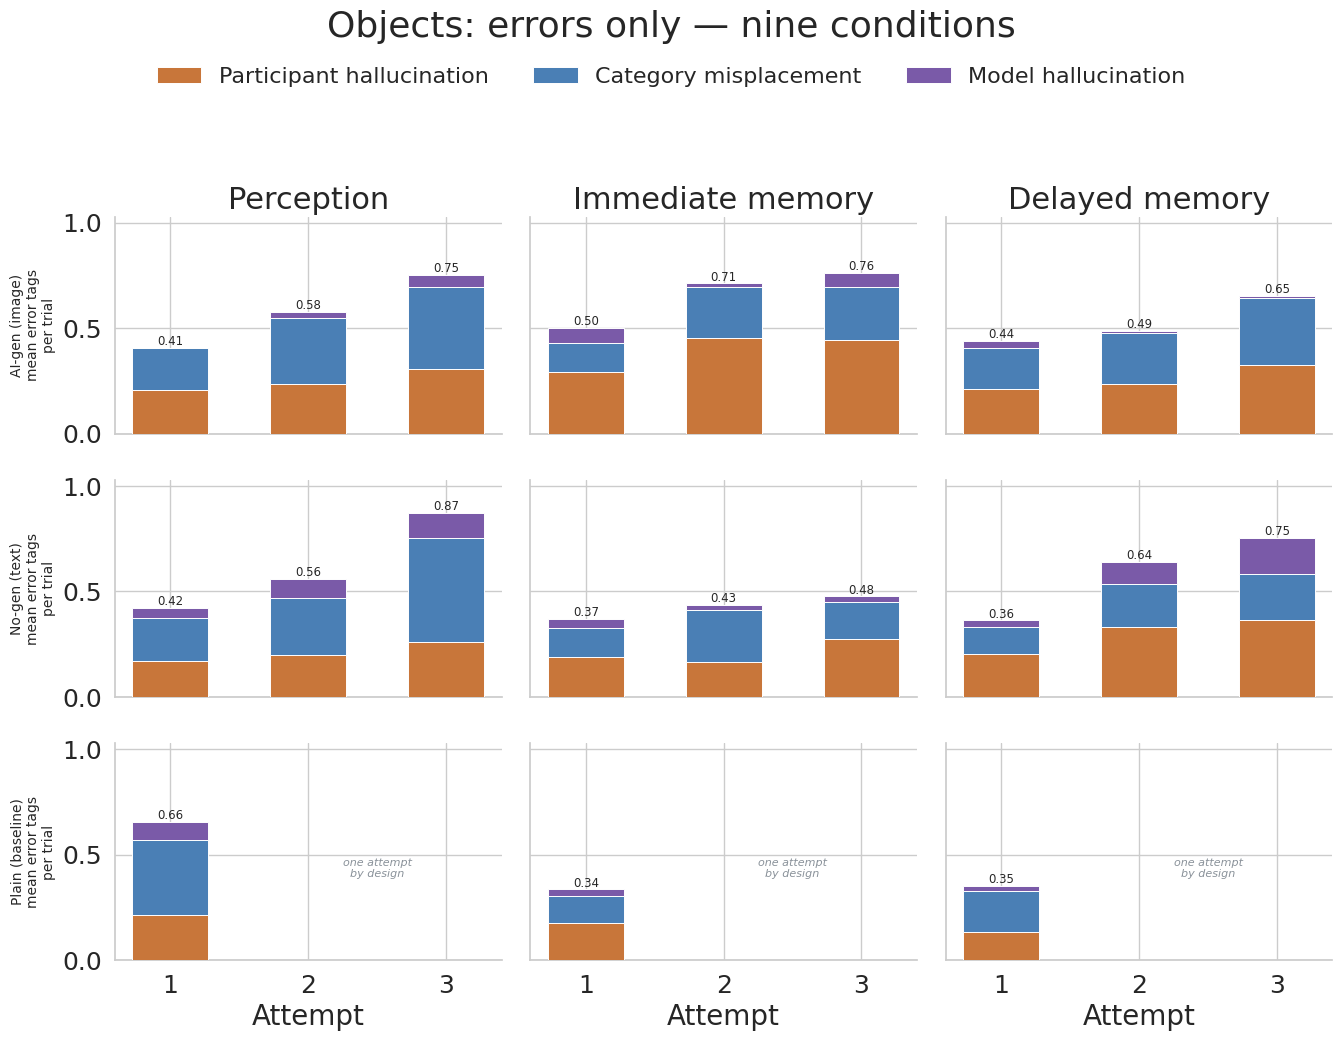


Objects — errors only (count)


Participant hallucination  \
generation task       attempt                              
aigen      perception 1                            0.206   
                      2                            0.233   
                      3                            0.307   
           immediate  1                            0.290   
                      2                            0.454   
                      3                            0.444   
           delay      1                            0.213   
                      2                            0.237   
                      3                            0.327   
nogen      perception 1                            0.169   
                      2                            0.200   
                      3                            0.260   
           immediate  1                            0.189   
                      2                            0.167   
                      3                            0.274   
           delay      1                            0.203   
                      2                            0.333   
                      3                            0.367   
plain      perception 1                            0.216   
           immediate  1                            0.176   
           delay      1                            0.136   

                               Category misplacement  Model hallucination  
generation task       attempt                                              
aigen      perception 1                        0.199                0.000  
                      2                        0.316                0.026  
                      3                        0.389                0.054  
           immediate  1                        0.141                0.069  
                      2                        0.242                0.016  
                      3                        0.250                0.066  
           delay      1                        0.193                0.034  
                      2                        0.241                0.008  
                      3                        0.316                0.008  
nogen      perception 1                        0.204                0.048  
                      2                        0.270                0.090  
                      3                        0.491                0.120  
           immediate  1                        0.140                0.040  
                      2                        0.243                0.024  
                      3                        0.178                0.024  
           delay      1                        0.127                0.032  
                      2                        0.203                0.104  
                      3                        0.215                0.170  
plain      perception 1                        0.352                0.088  
           immediate  1                        0.128                0.032  
           delay      1                        0.190                0.026

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7a_errors_count_stuff_grid.png


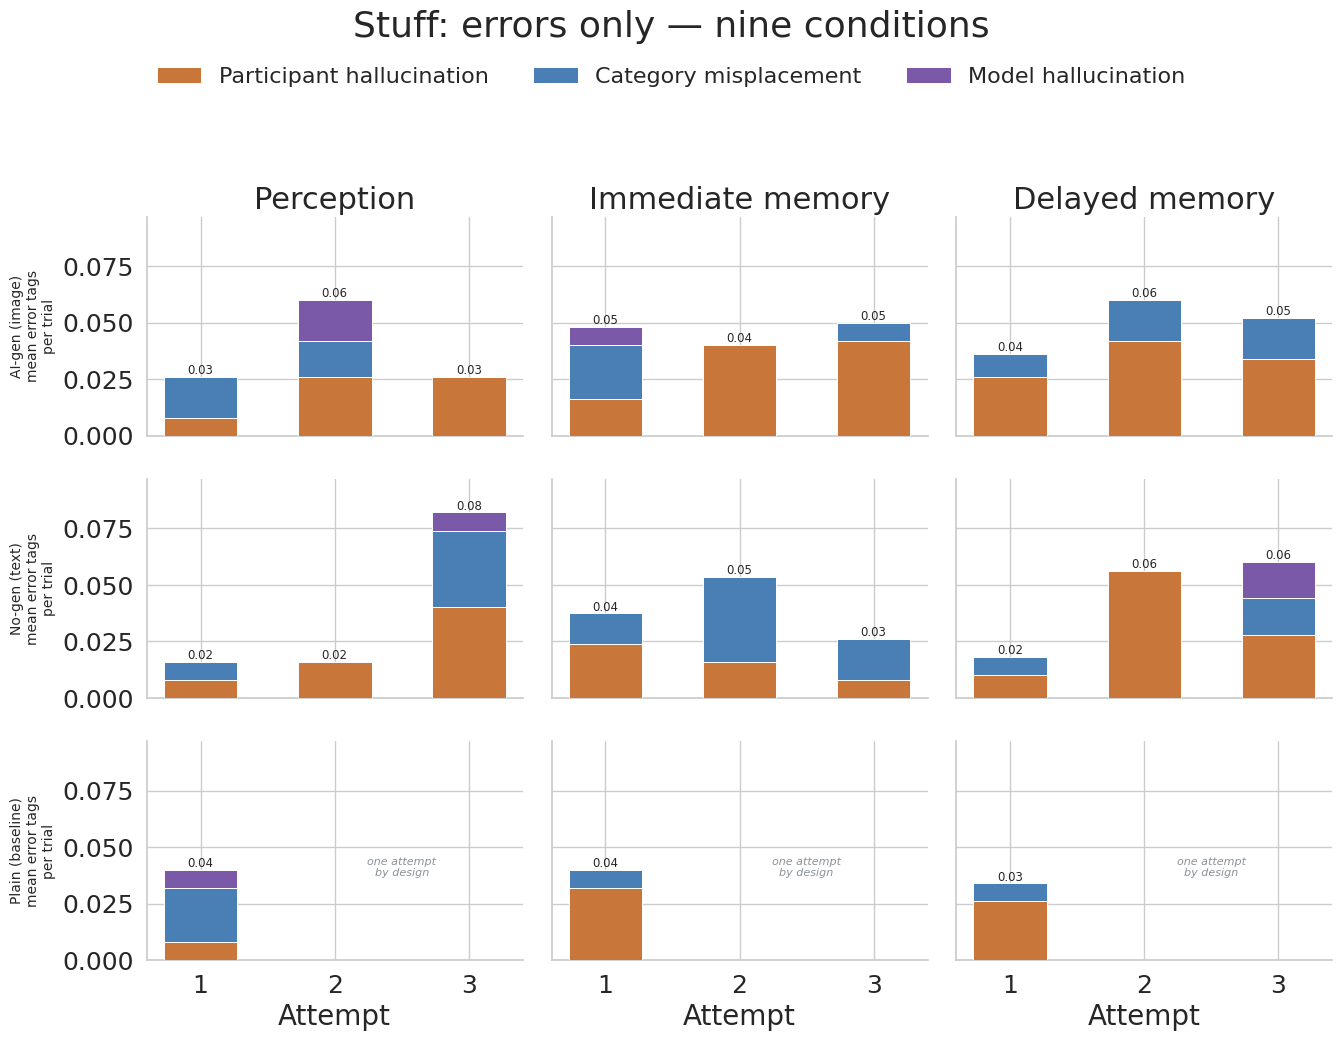


Stuff — errors only (count)


Participant hallucination  \
generation task       attempt                              
aigen      perception 1                            0.008   
                      2                            0.026   
                      3                            0.026   
           immediate  1                            0.016   
                      2                            0.040   
                      3                            0.042   
           delay      1                            0.026   
                      2                            0.042   
                      3                            0.034   
nogen      perception 1                            0.008   
                      2                            0.016   
                      3                            0.040   
           immediate  1                            0.024   
                      2                            0.016   
                      3                            0.008   
           delay      1                            0.010   
                      2                            0.056   
                      3                            0.028   
plain      perception 1                            0.008   
           immediate  1                            0.032   
           delay      1                            0.026   

                               Category misplacement  Model hallucination  
generation task       attempt                                              
aigen      perception 1                        0.018                0.000  
                      2                        0.016                0.018  
                      3                        0.000                0.000  
           immediate  1                        0.024                0.008  
                      2                        0.000                0.000  
                      3                        0.008                0.000  
           delay      1                        0.010                0.000  
                      2                        0.018                0.000  
                      3                        0.018                0.000  
nogen      perception 1                        0.008                0.000  
                      2                        0.000                0.000  
                      3                        0.034                0.008  
           immediate  1                        0.013                0.000  
                      2                        0.037                0.000  
                      3                        0.018                0.000  
           delay      1                        0.008                0.000  
                      2                        0.000                0.000  
                      3                        0.016                0.016  
plain      perception 1                        0.024                0.008  
           immediate  1                        0.008                0.000  
           delay      1                        0.008                0.000

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7a_errors_count_scene_category_grid.png


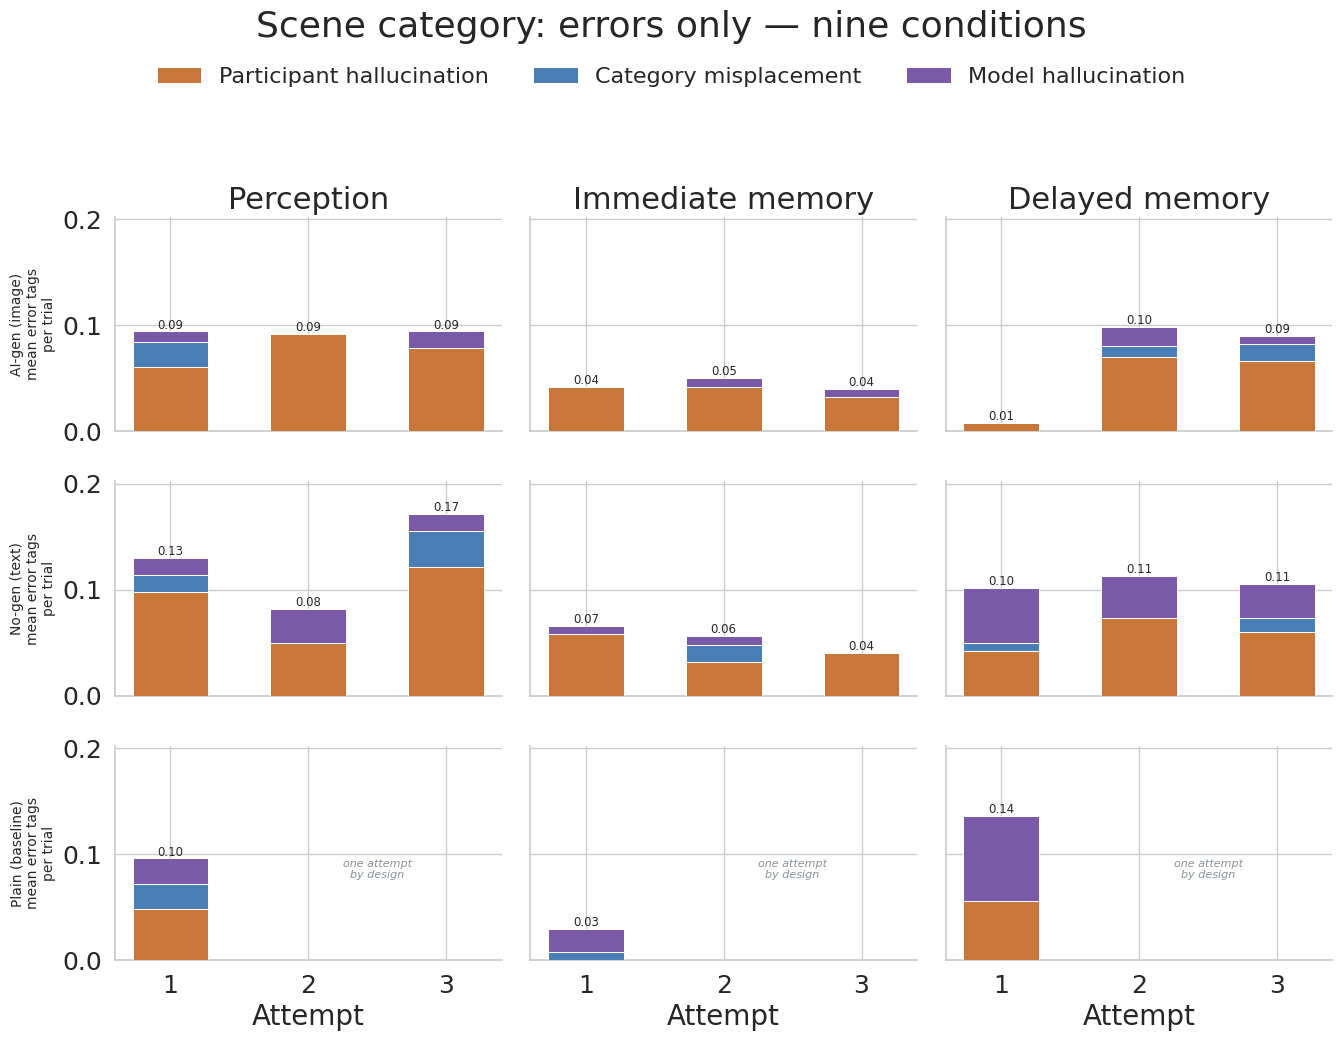


Scene category — errors only (count)


Participant hallucination  \
generation task       attempt                              
aigen      perception 1                            0.060   
                      2                            0.092   
                      3                            0.078   
           immediate  1                            0.042   
                      2                            0.042   
                      3                            0.032   
           delay      1                            0.008   
                      2                            0.070   
                      3                            0.066   
nogen      perception 1                            0.098   
                      2                            0.050   
                      3                            0.121   
           immediate  1                            0.058   
                      2                            0.032   
                      3                            0.040   
           delay      1                            0.042   
                      2                            0.073   
                      3                            0.060   
plain      perception 1                            0.048   
           immediate  1                            0.000   
           delay      1                            0.056   

                               Category misplacement  Model hallucination  
generation task       attempt                                              
aigen      perception 1                        0.024                0.010  
                      2                        0.000                0.000  
                      3                        0.000                0.016  
           immediate  1                        0.000                0.000  
                      2                        0.000                0.008  
                      3                        0.000                0.008  
           delay      1                        0.000                0.000  
                      2                        0.010                0.018  
                      3                        0.016                0.008  
nogen      perception 1                        0.016                0.016  
                      2                        0.000                0.032  
                      3                        0.034                0.016  
           immediate  1                        0.000                0.008  
                      2                        0.016                0.008  
                      3                        0.000                0.000  
           delay      1                        0.008                0.052  
                      2                        0.000                0.040  
                      3                        0.013                0.032  
plain      perception 1                        0.024                0.024  
           immediate  1                        0.008                0.021  
           delay      1                        0.000                0.080

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7a_errors_count_spatial_relations_grid.png


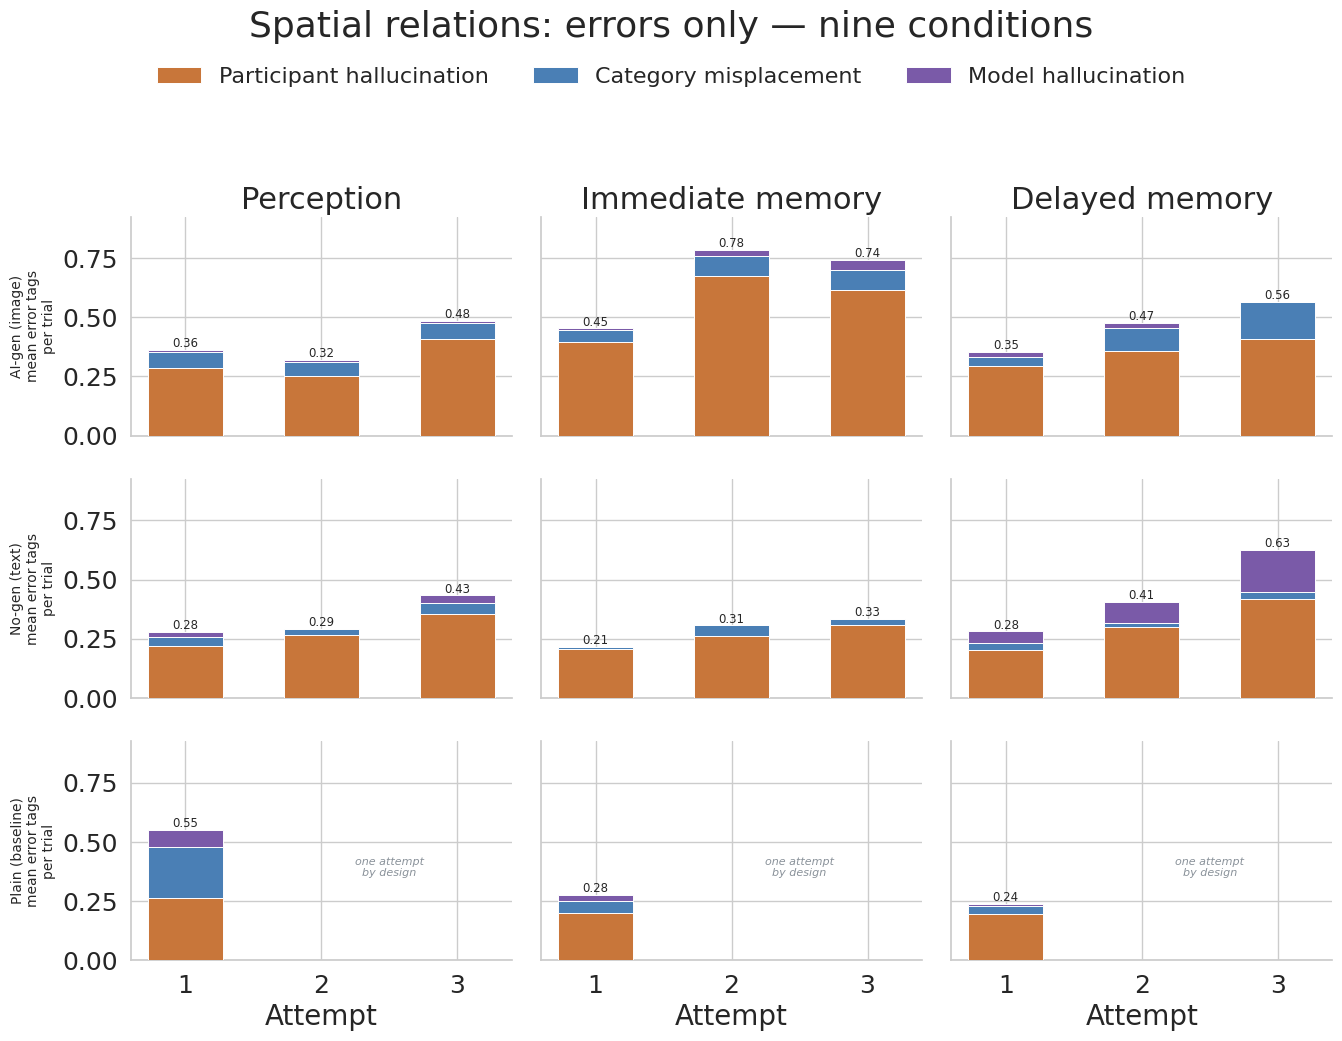


Spatial relations — errors only (count)


Participant hallucination  \
generation task       attempt                              
aigen      perception 1                            0.287   
                      2                            0.252   
                      3                            0.407   
           immediate  1                            0.397   
                      2                            0.675   
                      3                            0.613   
           delay      1                            0.295   
                      2                            0.359   
                      3                            0.409   
nogen      perception 1                            0.219   
                      2                            0.264   
                      3                            0.356   
           immediate  1                            0.207   
                      2                            0.261   
                      3                            0.307   
           delay      1                            0.204   
                      2                            0.301   
                      3                            0.417   
plain      perception 1                            0.264   
           immediate  1                            0.199   
           delay      1                            0.196   

                               Category misplacement  Model hallucination  
generation task       attempt                                              
aigen      perception 1                        0.066                0.008  
                      2                        0.059                0.008  
                      3                        0.068                0.008  
           immediate  1                        0.048                0.008  
                      2                        0.084                0.024  
                      3                        0.088                0.040  
           delay      1                        0.036                0.021  
                      2                        0.095                0.021  
                      3                        0.156                0.000  
nogen      perception 1                        0.036                0.024  
                      2                        0.028                0.000  
                      3                        0.045                0.032  
           immediate  1                        0.008                0.000  
                      2                        0.045                0.000  
                      3                        0.028                0.000  
           delay      1                        0.029                0.048  
                      2                        0.016                0.090  
                      3                        0.031                0.178  
plain      perception 1                        0.213                0.072  
           immediate  1                        0.053                0.024  
           delay      1                        0.032                0.010

saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7a_errors_count_attr_color_grid.png


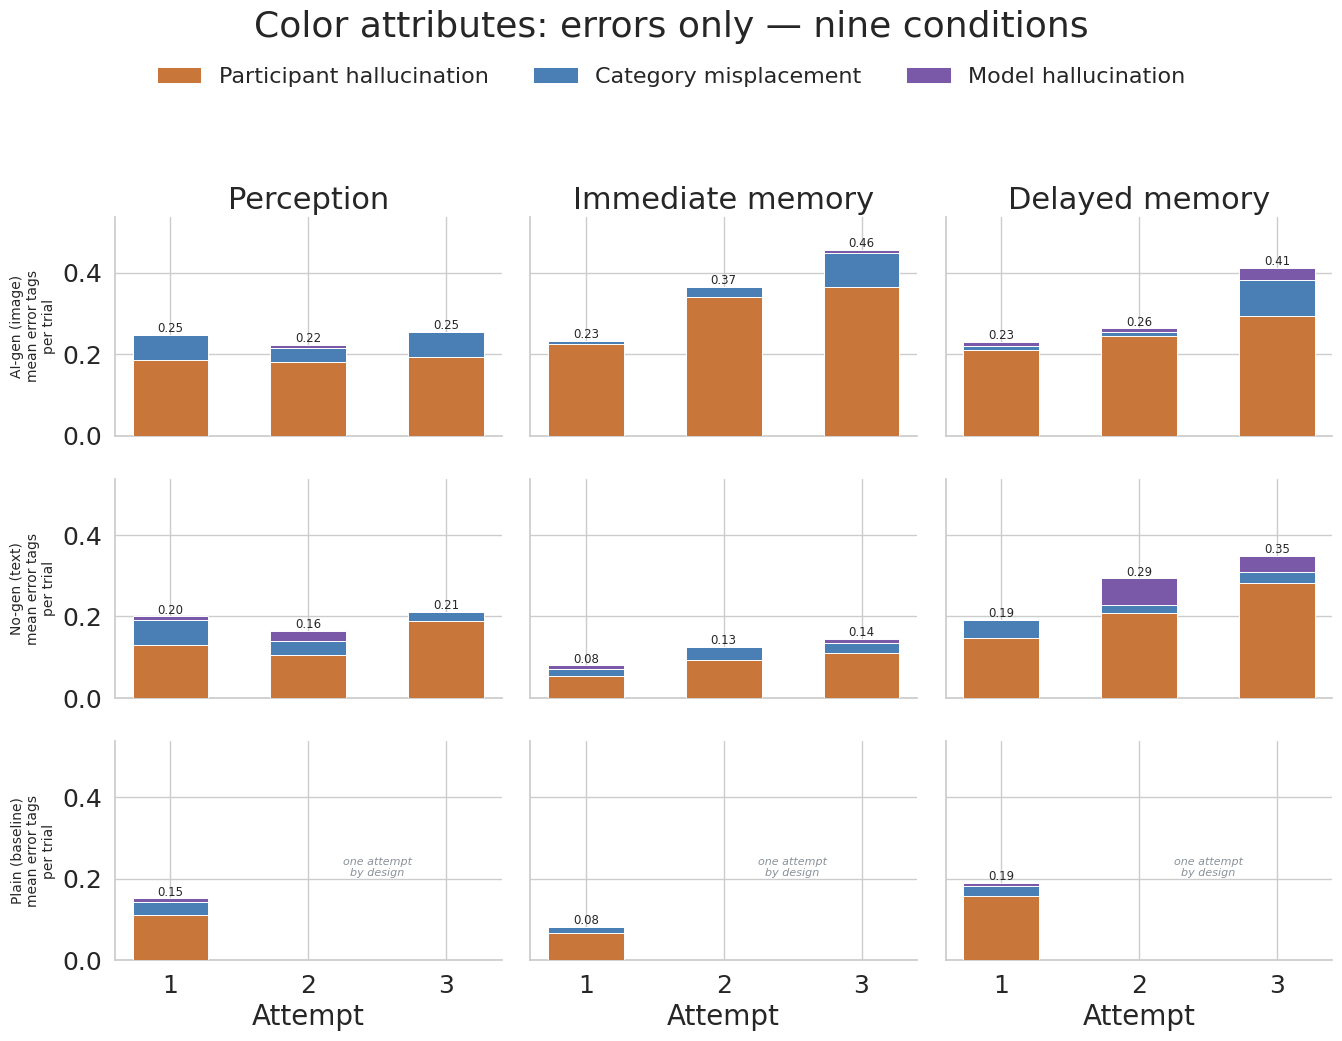


Color attributes — errors only (count)


Participant hallucination  \
generation task       attempt                              
aigen      perception 1                            0.186   
                      2                            0.180   
                      3                            0.192   
           immediate  1                            0.225   
                      2                            0.341   
                      3                            0.365   
           delay      1                            0.211   
                      2                            0.245   
                      3                            0.295   
nogen      perception 1                            0.130   
                      2                            0.106   
                      3                            0.188   
           immediate  1                            0.054   
                      2                            0.094   
                      3                            0.110   
           delay      1                            0.147   
                      2                            0.208   
                      3                            0.281   
plain      perception 1                            0.112   
           immediate  1                            0.066   
           delay      1                            0.158   

                               Category misplacement  Model hallucination  
generation task       attempt                                              
aigen      perception 1                        0.062                0.000  
                      2                        0.034                0.008  
                      3                        0.062                0.000  
           immediate  1                        0.008                0.000  
                      2                        0.024                0.000  
                      3                        0.082                0.008  
           delay      1                        0.010                0.008  
                      2                        0.010                0.008  
                      3                        0.087                0.031  
nogen      perception 1                        0.062                0.008  
                      2                        0.034                0.024  
                      3                        0.024                0.000  
           immediate  1                        0.018                0.008  
                      2                        0.032                0.000  
                      3                        0.024                0.010  
           delay      1                        0.044                0.000  
                      2                        0.021                0.064  
                      3                        0.027                0.040  
plain      perception 1                        0.032                0.008  
           immediate  1                        0.016                0.000  
           delay      1                        0.024                0.008

In [73]:
# 7a. Errors only, one figure per semantic category. Rows = generation, columns = task:
# the nine conditions as a 3x3 grid, shared y within a figure so cells compare directly.
#
# `norm` picks what the height means, and the two answer different questions:
#   "count" - mean wrong tags per trial. How much bad content a description carries.
#   "rate"  - those as a %% of extracted tags. How reliable the describer is.
# They can disagree: a condition producing more tags gains errors in count while holding
# steady in rate, so read growth in one against the other before calling it an effect.
ERR_SEG = [s for s in BUDGET_SEG if not s[0].startswith("n_valid")]
GEN_ROWS = ["aigen", "nogen", "plain"]


def error_means(category, gen, norm="count"):
    """Participant-averaged error counts, optionally as a share of extracted tags."""
    d = df[df["generation"] == gen].copy()
    d = d[d["error"].isna()] if "error" in d.columns else d
    d["attempt"] = d["attempt"].astype(int)
    labels = []
    for tmpl, label, _ in ERR_SEG:
        d[label] = pd.to_numeric(d[tmpl.format(c=category)], errors="coerce").fillna(0)
        labels.append(label)
    d["_extracted"] = pd.to_numeric(d[f"n_extracted_{category}"], errors="coerce").fillna(0)
    per_uid = d.groupby(["task", "attempt", "uid"])[labels + ["_extracted"]].sum().reset_index()
    if norm == "rate":
        # Ratio of sums within a participant, so a trial with many tags is not
        # weighted the same as a trial with two.
        for label in labels:
            per_uid[label] = 100 * per_uid[label] / per_uid["_extracted"].replace(0, np.nan)
    else:
        n_trials = d.groupby(["task", "attempt", "uid"]).size().to_numpy()
        for label in labels:
            per_uid[label] = per_uid[label] / n_trials
    return per_uid.groupby(["task", "attempt"])[labels].mean()


def plot_error_grid(category="objects", gens=GEN_ROWS, attempts=ATTEMPTS,
                    norm="count", save=True):
    frames = {g: error_means(category, g, norm=norm) for g in gens}
    labels = [lab for _, lab, _ in ERR_SEG]
    vmax = max(float(m[labels].sum(axis=1).max()) for m in frames.values())
    unit = "mean error tags\nper trial" if norm == "count" else "% of extracted tags"
    fmt = (lambda v: f"{v:.2f}") if norm == "count" else (lambda v: f"{v:.1f}%")

    fig, axes = plt.subplots(len(gens), len(TASK_ORDER),
                             figsize=(4.6 * len(TASK_ORDER), 3.5 * len(gens)),
                             sharey=True, sharex=True)
    axes = np.atleast_2d(axes)
    for r, gen in enumerate(gens):
        m = frames[gen]
        for c, task in enumerate(TASK_ORDER):
            ax = axes[r, c]
            if task in m.index.get_level_values(0):
                sub = m.loc[task].reindex(attempts)
                x = np.arange(len(sub))
                bottom = np.zeros(len(sub))
                for (_t, label, colour) in ERR_SEG:
                    vals = sub[label].fillna(0).to_numpy(dtype=float)
                    ax.bar(x, vals, 0.55, bottom=bottom, color=colour, edgecolor="white",
                           linewidth=0.7, zorder=3,
                           label=label if (r == 0 and c == 0) else None)
                    bottom += vals
                for xi, tot in zip(x, bottom):
                    if tot > 0:
                        ax.text(xi, tot, fmt(tot), ha="center", va="bottom",
                                fontsize=8.5, zorder=4)
                missing = [a for a in attempts if a not in sub.dropna(how="all").index]
                if missing:
                    ax.text(np.mean([attempts.index(a) for a in missing]), vmax * 0.5,
                            "one attempt\nby design", ha="center", va="center",
                            fontsize=8, color="#8a929a", style="italic")
            ax.set_xticks(np.arange(len(attempts)))
            ax.set_xticklabels([str(int(a)) for a in attempts])
            ax.spines[["top", "right"]].set_visible(False)
            if r == 0:
                ax.set_title(TASK_LABELS[task])
            if r == len(gens) - 1:
                ax.set_xlabel("Attempt")
            if c == 0:
                ax.set_ylabel(f"{GEN_LABELS.get(gen, gen)}\n{unit}", fontsize=10)
    for ax in axes.ravel():
        ax.set_ylim(0, vmax * 1.18)
    handles, lab = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, lab, loc="upper center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, 0.965))
    fig.suptitle(f"{cat_label(category)}: errors only \u2014 nine conditions"
                 + ("" if norm == "count" else ", as a share of extracted tags"), y=1.0)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    if save:
        _save(fig, GRAPHS / f"q7a_errors_{norm}_{category}_grid.png")
    plt.show()
    return pd.concat({g: frames[g][labels] for g in gens}, names=["generation"])


ERROR_NORM = "count"      # flip to "rate" for the same grids as percentages

for category in VALIDATED_CATEGORIES:
    tab = plot_error_grid(category, norm=ERROR_NORM)
    print(f"\n{cat_label(category)} \u2014 errors only ({ERROR_NORM})")
    display(tab.reindex(TASK_ORDER, level=1).round(3))


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7b_errors_objects_reference_sets.png


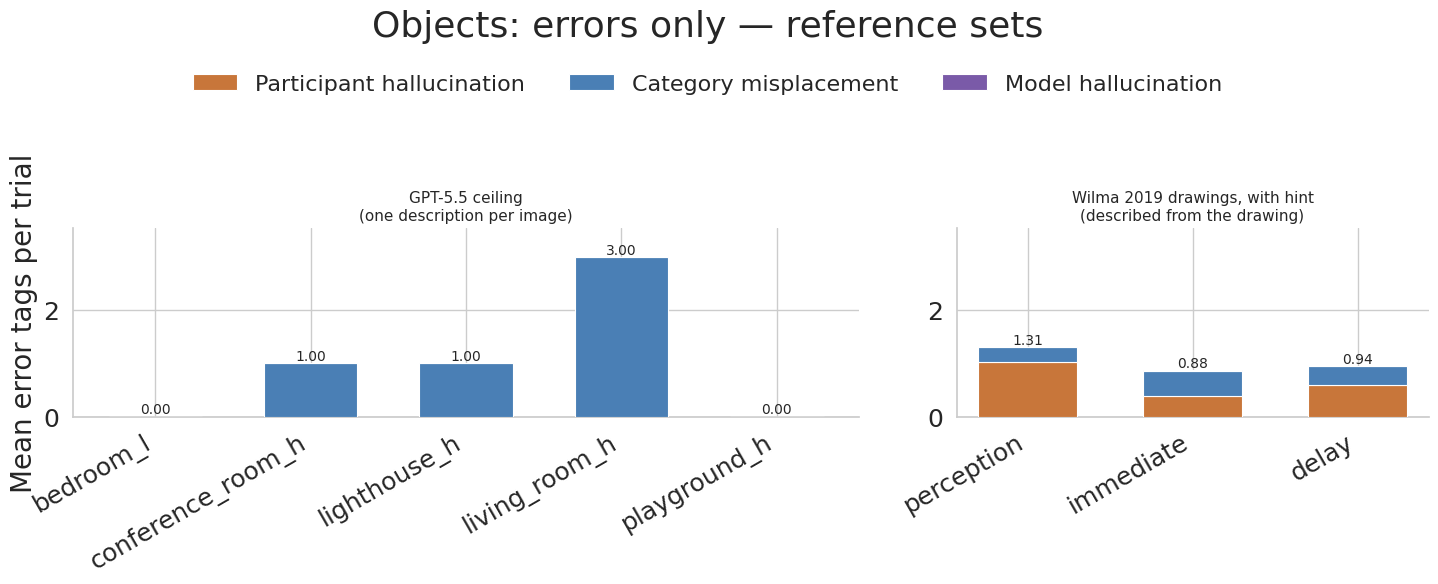


Objects — GPT-5.5 ceiling


,Participant hallucination,Category misplacement,Model hallucination
gt,,,
bedroom_l.jpg,0.0,0.0,0.0
conference_room_h.jpg,0.0,1.0,0.0
lighthouse_h.jpg,0.0,1.0,0.0
living_room_h.jpg,0.0,3.0,0.0
playground_h.jpg,0.0,0.0,0.0



Objects — Wilma 2019 drawings, with hint


,Participant hallucination,Category misplacement,Model hallucination
task,,,
perception,1.035,0.272,0.000
immediate,0.389,0.475,0.017
delay,0.587,0.357,0.000


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7b_errors_stuff_reference_sets.png


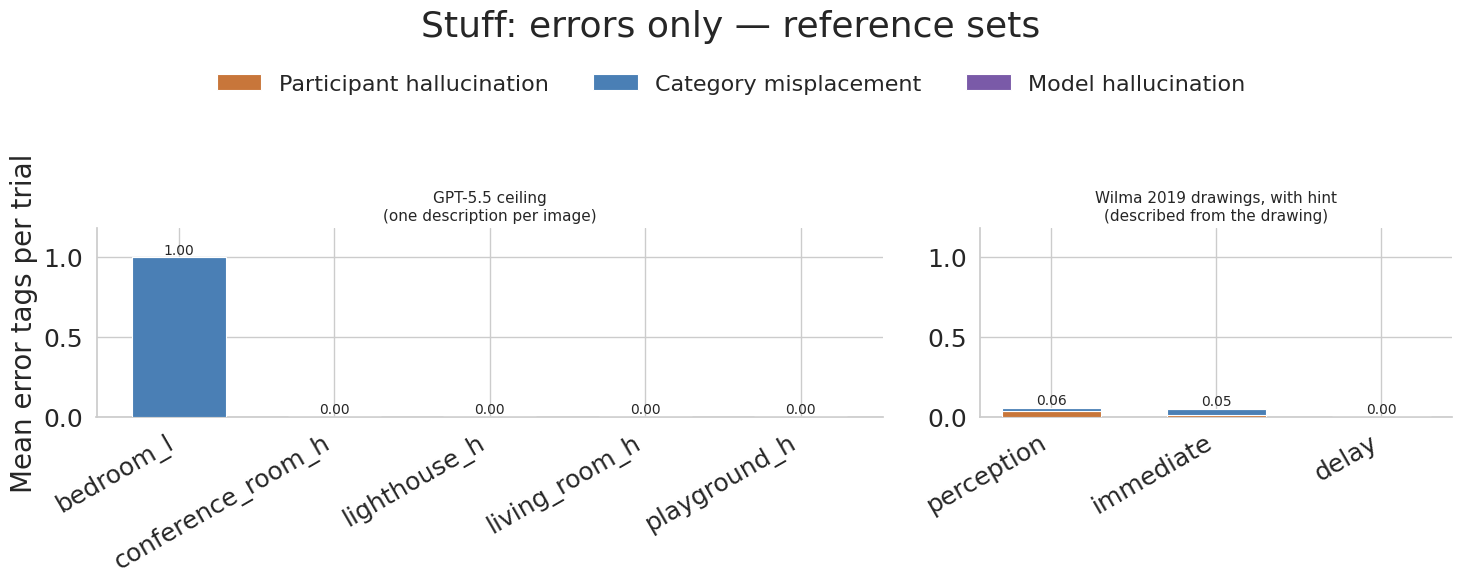


Stuff — GPT-5.5 ceiling


,Participant hallucination,Category misplacement,Model hallucination
gt,,,
bedroom_l.jpg,0.0,1.0,0.0
conference_room_h.jpg,0.0,0.0,0.0
lighthouse_h.jpg,0.0,0.0,0.0
living_room_h.jpg,0.0,0.0,0.0
playground_h.jpg,0.0,0.0,0.0



Stuff — Wilma 2019 drawings, with hint


,Participant hallucination,Category misplacement,Model hallucination
task,,,
perception,0.038,0.020,0.0
immediate,0.008,0.042,0.0
delay,0.000,0.000,0.0


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7b_errors_scene_category_reference_sets.png


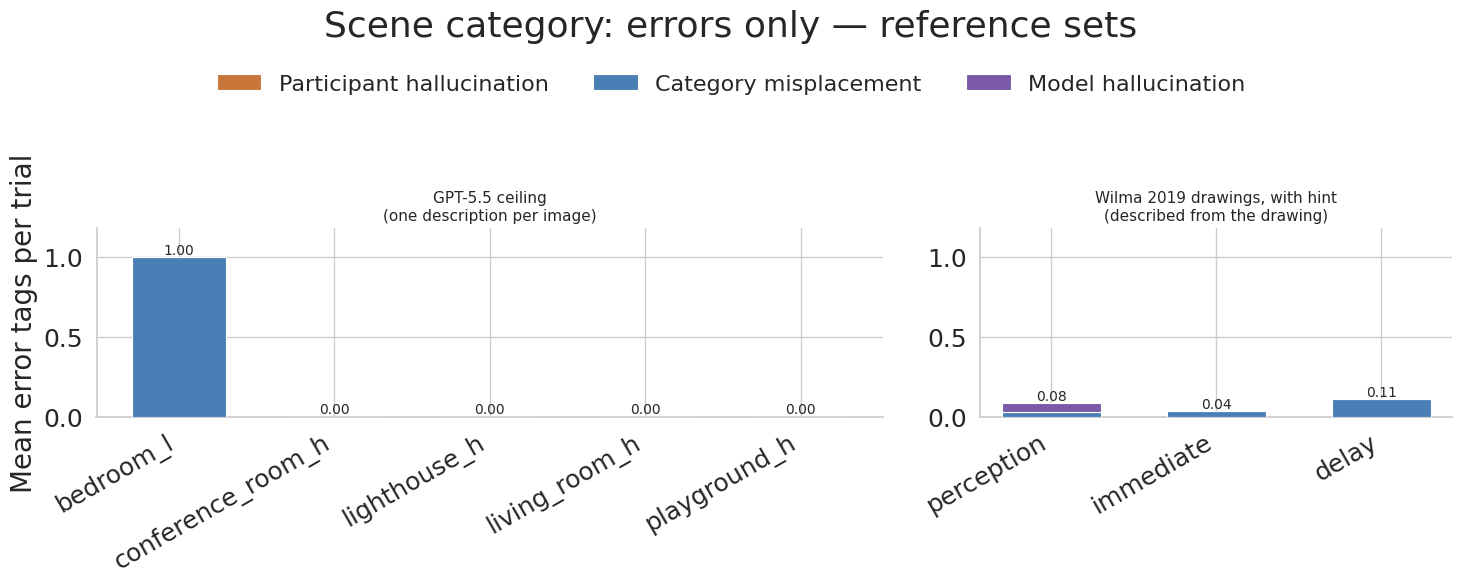


Scene category — GPT-5.5 ceiling


,Participant hallucination,Category misplacement,Model hallucination
gt,,,
bedroom_l.jpg,0.0,1.0,0.0
conference_room_h.jpg,0.0,0.0,0.0
lighthouse_h.jpg,0.0,0.0,0.0
living_room_h.jpg,0.0,0.0,0.0
playground_h.jpg,0.0,0.0,0.0



Scene category — Wilma 2019 drawings, with hint


,Participant hallucination,Category misplacement,Model hallucination
task,,,
perception,0.0,0.029,0.054
immediate,0.0,0.036,0.000
delay,0.0,0.111,0.000


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7b_errors_spatial_relations_reference_sets.png


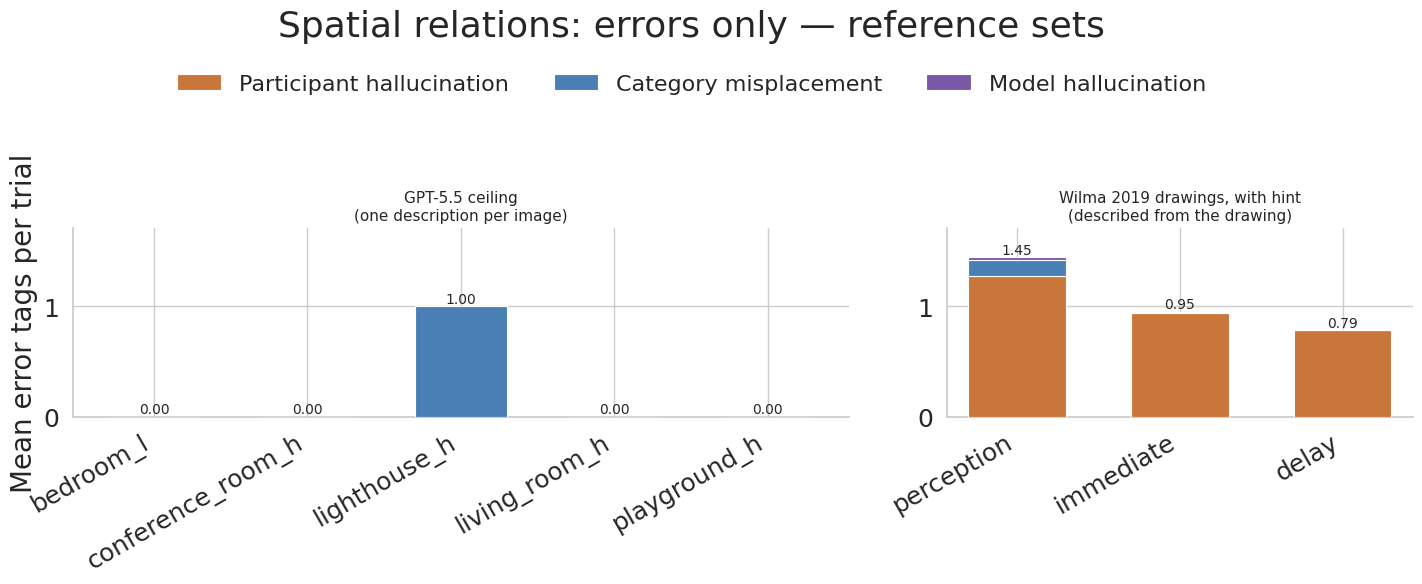


Spatial relations — GPT-5.5 ceiling


,Participant hallucination,Category misplacement,Model hallucination
gt,,,
bedroom_l.jpg,0.0,0.0,0.0
conference_room_h.jpg,0.0,0.0,0.0
lighthouse_h.jpg,0.0,1.0,0.0
living_room_h.jpg,0.0,0.0,0.0
playground_h.jpg,0.0,0.0,0.0



Spatial relations — Wilma 2019 drawings, with hint


,Participant hallucination,Category misplacement,Model hallucination
task,,,
perception,1.279,0.145,0.025
immediate,0.936,0.017,0.000
delay,0.786,0.000,0.000


saved: /mnt/hdd/anatkorol/Imagination_in_translation/analysis/outputs/Full_experiment/combined/graphs/full_data_comparisons/q7b_errors_attr_color_reference_sets.png


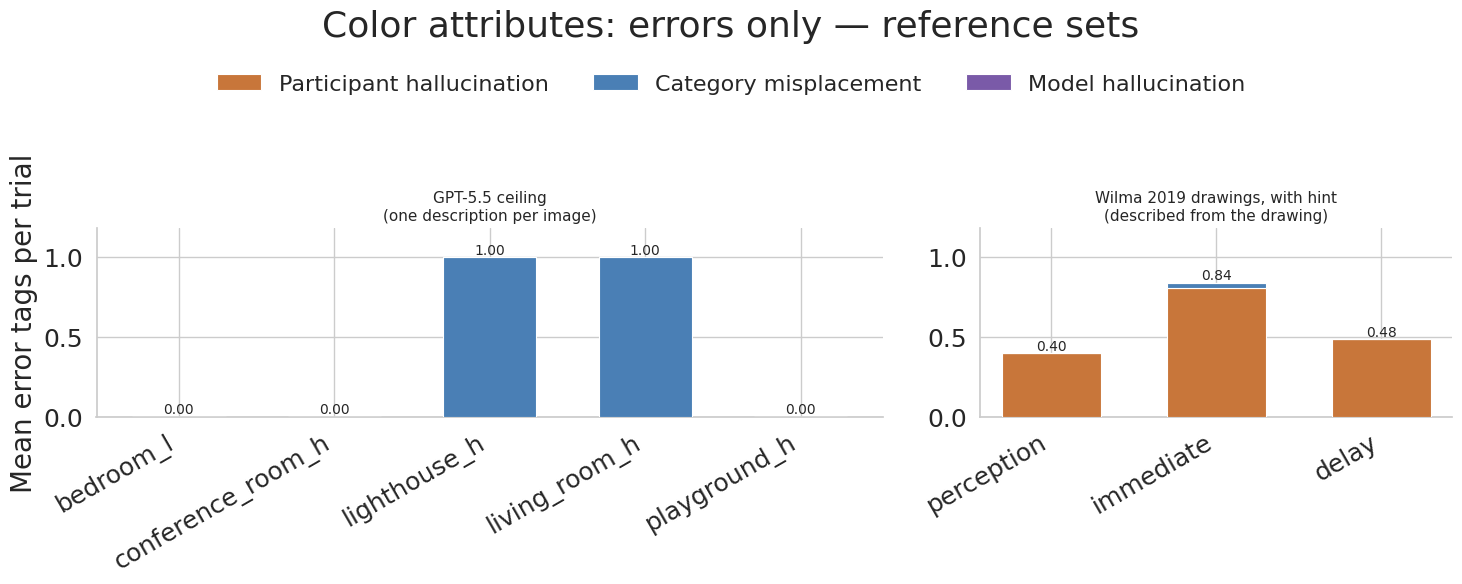


Color attributes — GPT-5.5 ceiling


,Participant hallucination,Category misplacement,Model hallucination
gt,,,
bedroom_l.jpg,0.0,0.0,0.0
conference_room_h.jpg,0.0,0.0,0.0
lighthouse_h.jpg,0.0,1.0,0.0
living_room_h.jpg,0.0,1.0,0.0
playground_h.jpg,0.0,0.0,0.0



Color attributes — Wilma 2019 drawings, with hint


,Participant hallucination,Category misplacement,Model hallucination
task,,,
perception,0.400,0.000,0.0
immediate,0.806,0.033,0.0
delay,0.484,0.000,0.0


In [74]:
# 7b. the two reference sets. Neither has attempts: the ceiling is one description per
# image, the drawings one drawing per participant per task.
def error_counts(frame, category="objects", group=None, label=""):
    """Mean error tags per trial, participant-averaged where a uid column exists."""
    d = frame.copy()
    d = d[d["error"].isna()] if "error" in d.columns else d
    keys = []
    for tmpl, lab, _ in ERR_SEG:
        d[lab] = pd.to_numeric(d[tmpl.format(c=category)], errors="coerce").fillna(0)
        keys.append(lab)
    if group is None:
        return pd.DataFrame({label: d[keys].mean()}).T
    if "uid" in d.columns:
        d = d.groupby([group, "uid"])[keys].mean().reset_index()
    return d.groupby(group)[keys].mean()


CEIL_PATH = (config.ROOT / "Data" / "processed_data" / "Full_experiment" / "combined"
             / "gpt_ceiling" / "gpt_ceiling_semantic_tag_image_validation_verbosity-medium.csv")
ceil_df = pd.read_csv(CEIL_PATH)
draw_df = pd.read_csv(DRAW_PATH)
DRAW_TASK = {"draw_perc": "perception", "draw_imm": "immediate", "draw_del": "delay"}
draw_df["task"] = draw_df["condition"].map(DRAW_TASK)

def reference_panels(category):
    return [("GPT-5.5 ceiling\n(one description per image)",
            error_counts(ceil_df, category=category, group="gt")),
           ("Wilma 2019 drawings, with hint\n(described from the drawing)",
            error_counts(draw_df, category=category, group="task").reindex(TASK_ORDER))]


def plot_reference_errors(category="objects", save=True):
    panels = reference_panels(category)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [5, 3]})
    vmax = max(float(t.sum(axis=1).max()) for _, t in panels) or 1.0
    for i, (ax, (title, tab)) in enumerate(zip(axes, panels)):
        x = np.arange(len(tab))
        bottom = np.zeros(len(tab))
        for (_t, label, colour) in ERR_SEG:
            vals = tab[label].fillna(0).to_numpy(dtype=float)
            ax.bar(x, vals, 0.6, bottom=bottom, color=colour, edgecolor="white",
                   linewidth=0.8, zorder=3, label=label if i == 0 else None)
            bottom += vals
        for xi, tot in zip(x, bottom):
            ax.text(xi, tot, f"{tot:.2f}", ha="center", va="bottom", fontsize=10, zorder=4)
        ax.set_xticks(x)
        ax.set_xticklabels([str(v).replace(".jpg", "") for v in tab.index],
                           rotation=30, ha="right")
        ax.set_title(title, fontsize=11)
        ax.set_ylabel("Mean error tags per trial" if i == 0 else "")
        ax.set_ylim(0, vmax * 1.18)
        ax.spines[["top", "right"]].set_visible(False)
    handles, lab = axes[0].get_legend_handles_labels()
    fig.legend(handles, lab, loc="upper center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, 0.98))
    fig.suptitle(f"{cat_label(category)}: errors only \u2014 reference sets", y=1.06)
    fig.tight_layout(rect=(0, 0, 1, 0.90))
    if save:
        _save(fig, GRAPHS / f"q7b_errors_{category}_reference_sets.png")
    plt.show()
    return panels


for category in VALIDATED_CATEGORIES:
    panels = plot_reference_errors(category)
    for title, tab in panels:
        print(f"\n{cat_label(category)} \u2014 {title.splitlines()[0]}")
        display(tab.round(3))


---
### Notes
- **`plain` and attempts.** `plain` is one attempt by design; any view with `attempts=[1,2,3]`
  simply leaves its 2 and 3 slots empty. That is why 3a/3b/3c pin everything to attempt 1.
- **Drawings.** The `_no_hint` file next to the one loaded here holds the same drawings described
  *without* the category hint; point `DRAW_PATH` at it to redo section 5 on that arm.
- **Raw counts.** Flip `COUNT_MODE` to `"raw"` in the load cell to reproduce every figure on
  un-validated tag counts. Filenames carry the mode, so the two sets never overwrite each other.